In [ ]:
# uploading the dataset
from google.colab import files
uploaded = files.upload()


Saving pima-indians-diabetes.csv to pima-indians-diabetes.csv


In [ ]:
# Import necessary libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:
# Load the dataset correctly

columns = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
    'Outcome'
]

df = pd.read_csv(
    'pima-indians-diabetes.csv',
    header=None,
    names=columns
)

# Display first five records
print("First five records of the dataset:")
display(df.head())

# Display dataset shape
print("\nDataset Shape:")
print(df.shape)


First five records of the dataset:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset Shape:
(768, 9)


In [ ]:
#checking dataset information

print("Dataset Information:")
df.info()

print("\nStatistical Description:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nOutcome Distribution:")
print(df['Outcome'].value_counts())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical Description:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Outcome Distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


In [ ]:
# Check zero values in selected columns

columns_to_check = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

print("Number of zero values in each column:\n")

for column in columns_to_check:
    zero_count = (df[column] == 0).sum()
    print(f"{column}: {zero_count}")


Number of zero values in each column:

Glucose: 5
BloodPressure: 35
SkinThickness: 227
Insulin: 374
BMI: 11


**DATA PREPROCESSING**

In [ ]:
# Replace invalid zero values with NaN

columns_to_check = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

df[columns_to_check] = df[columns_to_check].replace(0, np.nan)

print("Missing values after replacing zeros:\n")
print(df.isnull().sum())


Missing values after replacing zeros:

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [ ]:
# Separate independent and dependent variables

X = df.drop('Outcome', axis=1)
y = df['Outcome']

print("Independent Variables (X):")
display(X.head())

print("\nDependent Variable (y):")
print(y.head())



Independent Variables (X):


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33



Dependent Variable (y):
0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64


In [ ]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))



Training records: 614
Testing records: 154


In [ ]:
# Handle missing values and apply feature scaling

preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

print("Missing values handled successfully!")
print("Feature scaling completed successfully!")

print("\nTraining data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)


Missing values handled successfully!
Feature scaling completed successfully!

Training data shape: (614, 8)
Testing data shape: (154, 8)


**VERSION 1: BASELINE KNN MODEL ->
Model Training and Optimal K Selection**

In [ ]:
# Import libraries for model selection

from sklearn.model_selection import GridSearchCV, StratifiedKFold
print("Model selection libraries imported successfully!")

Model selection libraries imported successfully!


In [ ]:
# Create a pipeline for the KNN model

knn_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

print("KNN model pipeline created successfully!")

KNN model pipeline created successfully!


In [ ]:
# Find the optimal K value using GridSearchCV

param_grid = {
    'knn__n_neighbors': list(range(1, 22, 2))
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

# Train the model using training data
grid_search.fit(X_train, y_train)

# Display the best K value and accuracy
best_k = grid_search.best_params_['knn__n_neighbors']

print("Optimal K value:", best_k)
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_ * 100:.2f}%")


Optimal K value: 13
Best Cross-Validation Accuracy: 77.52%


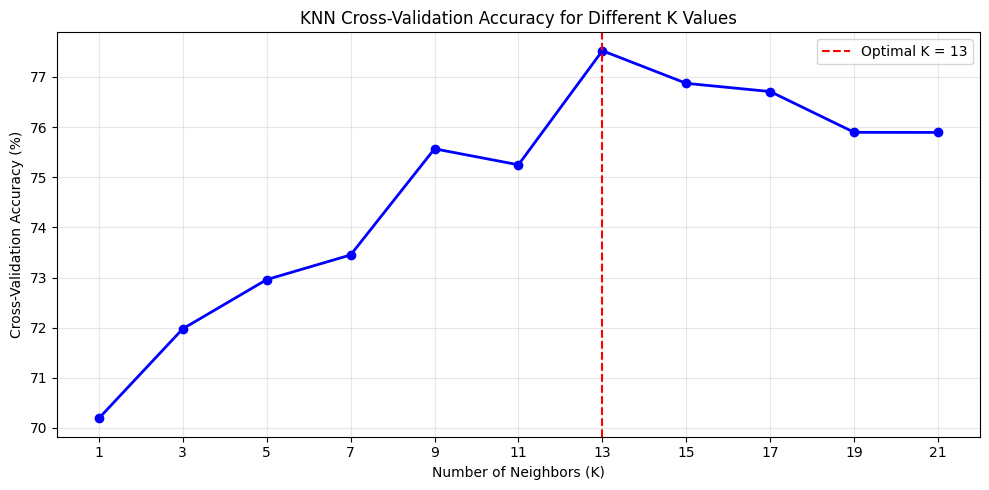

In [ ]:
# Plot cross-validation accuracy for different K values

k_values = list(range(1, 22, 2))
cv_scores = grid_search.cv_results_['mean_test_score'] * 100

plt.figure(figsize=(10, 5))

plt.plot(
    k_values,
    cv_scores,
    marker='o',
    color='blue',
    linewidth=2
)

plt.axvline(
    x=best_k,
    color='red',
    linestyle='--',
    label=f'Optimal K = {best_k}'
)

plt.title('KNN Cross-Validation Accuracy for Different K Values')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Cross-Validation Accuracy (%)')
plt.xticks(k_values)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Store the best trained KNN model

knn_model = grid_search.best_estimator_

print("KNN model trained successfully!")
print("Selected number of neighbors:", best_k)

KNN model trained successfully!
Selected number of neighbors: 13


**BASELINE KNN MODEL EVALUATION**

In [ ]:
# Import additional evaluation metrics

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

print("Evaluation libraries imported successfully!")

Evaluation libraries imported successfully!


In [ ]:
# Make predictions using the trained KNN model

y_train_pred = knn_model.predict(X_train)
y_pred = knn_model.predict(X_test)

# Predict probabilities for the positive class
y_prob = knn_model.predict_proba(X_test)[:, 1]

print("Predictions completed successfully!")
print("Total testing predictions:", len(y_pred))

print("\nFirst 10 predicted outcomes:")
print(y_pred[:10])

print("\nFirst 10 actual outcomes:")
print(y_test.values[:10])

Predictions completed successfully!
Total testing predictions: 154

First 10 predicted outcomes:
[1 0 0 0 0 0 0 1 0 1]

First 10 actual outcomes:
[0 0 0 1 0 0 1 1 0 0]


In [ ]:
# Calculate training and testing accuracy

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Training Accuracy: {train_accuracy * 100:.2f}%")
print(f"Testing Accuracy: {test_accuracy * 100:.2f}%")
print(f"Cross-Validation Accuracy: {grid_search.best_score_ * 100:.2f}%")

Training Accuracy: 80.62%
Testing Accuracy: 71.43%
Cross-Validation Accuracy: 77.52%


In [ ]:
# Generate the confusion matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Extract confusion matrix values

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negatives (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives (TP):", tp)

Confusion Matrix:
[[82 18]
 [26 28]]

True Negatives (TN): 82
False Positives (FP): 18
False Negatives (FN): 26
True Positives (TP): 28


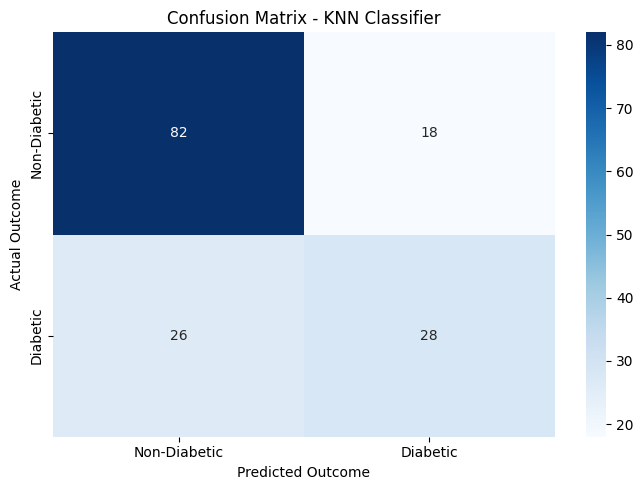

In [ ]:
# Visualize the confusion matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Diabetic', 'Diabetic'],
    yticklabels=['Non-Diabetic', 'Diabetic']
)

plt.title('Confusion Matrix - KNN Classifier')
plt.xlabel('Predicted Outcome')
plt.ylabel('Actual Outcome')
plt.tight_layout()
plt.show()


In [ ]:
# Calculate evaluation metrics

precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("KNN Model Performance Metrics:\n")

print(f"Accuracy:  {test_accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1-Score:  {f1 * 100:.2f}%")

KNN Model Performance Metrics:

Accuracy:  71.43%
Precision: 60.87%
Recall:    51.85%
F1-Score:  56.00%


In [ ]:
# Display the classification report

print("Classification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=['Non-Diabetic', 'Diabetic'],
    digits=4,
    zero_division=0
))

Classification Report:

              precision    recall  f1-score   support

Non-Diabetic     0.7593    0.8200    0.7885       100
    Diabetic     0.6087    0.5185    0.5600        54

    accuracy                         0.7143       154
   macro avg     0.6840    0.6693    0.6742       154
weighted avg     0.7065    0.7143    0.7084       154



In [ ]:
# Calculate ROC-AUC score

auc_score = roc_auc_score(y_test, y_prob)

print(f"ROC-AUC Score: {auc_score:.4f}")

ROC-AUC Score: 0.7944


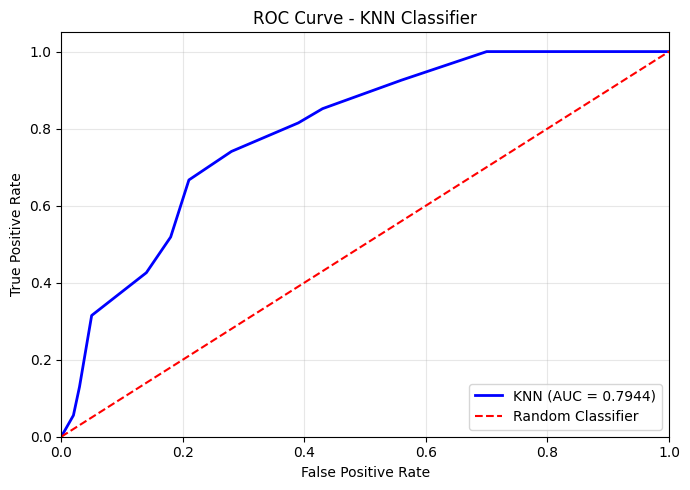

In [ ]:
# Calculate ROC-AUC score and plot the ROC curve
auc_score = roc_auc_score(y_test, y_prob)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    color='blue',
    linewidth=2,
    label=f'KNN (AUC = {auc_score:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    color='red',
    linestyle='--',
    label='Random Classifier'
)

plt.title('ROC Curve - KNN Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.xlim([0, 1])
plt.ylim([0, 1.05])
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**EXPLORATORY DATA ANALYSIS AND VISUALIZATION**

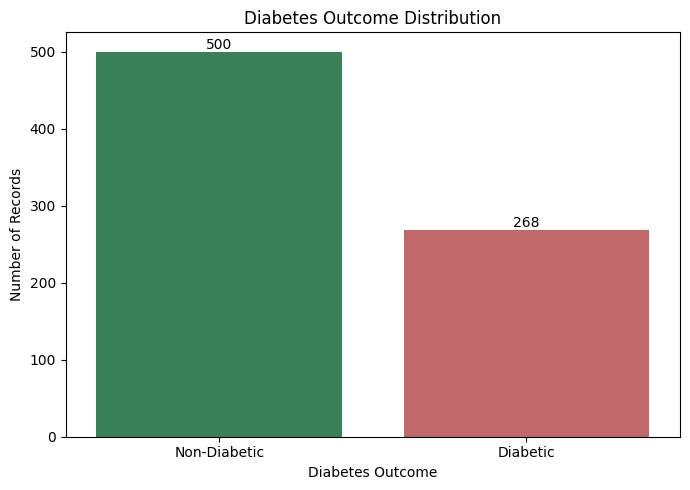

In [ ]:
# Visualize diabetes outcome distribution

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x='Outcome',
    hue='Outcome',
    palette=['seagreen', 'indianred'],
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title('Diabetes Outcome Distribution')
plt.xlabel('Diabetes Outcome')
plt.ylabel('Number of Records')
plt.xticks([0, 1], ['Non-Diabetic', 'Diabetic'])
plt.tight_layout()
plt.show()


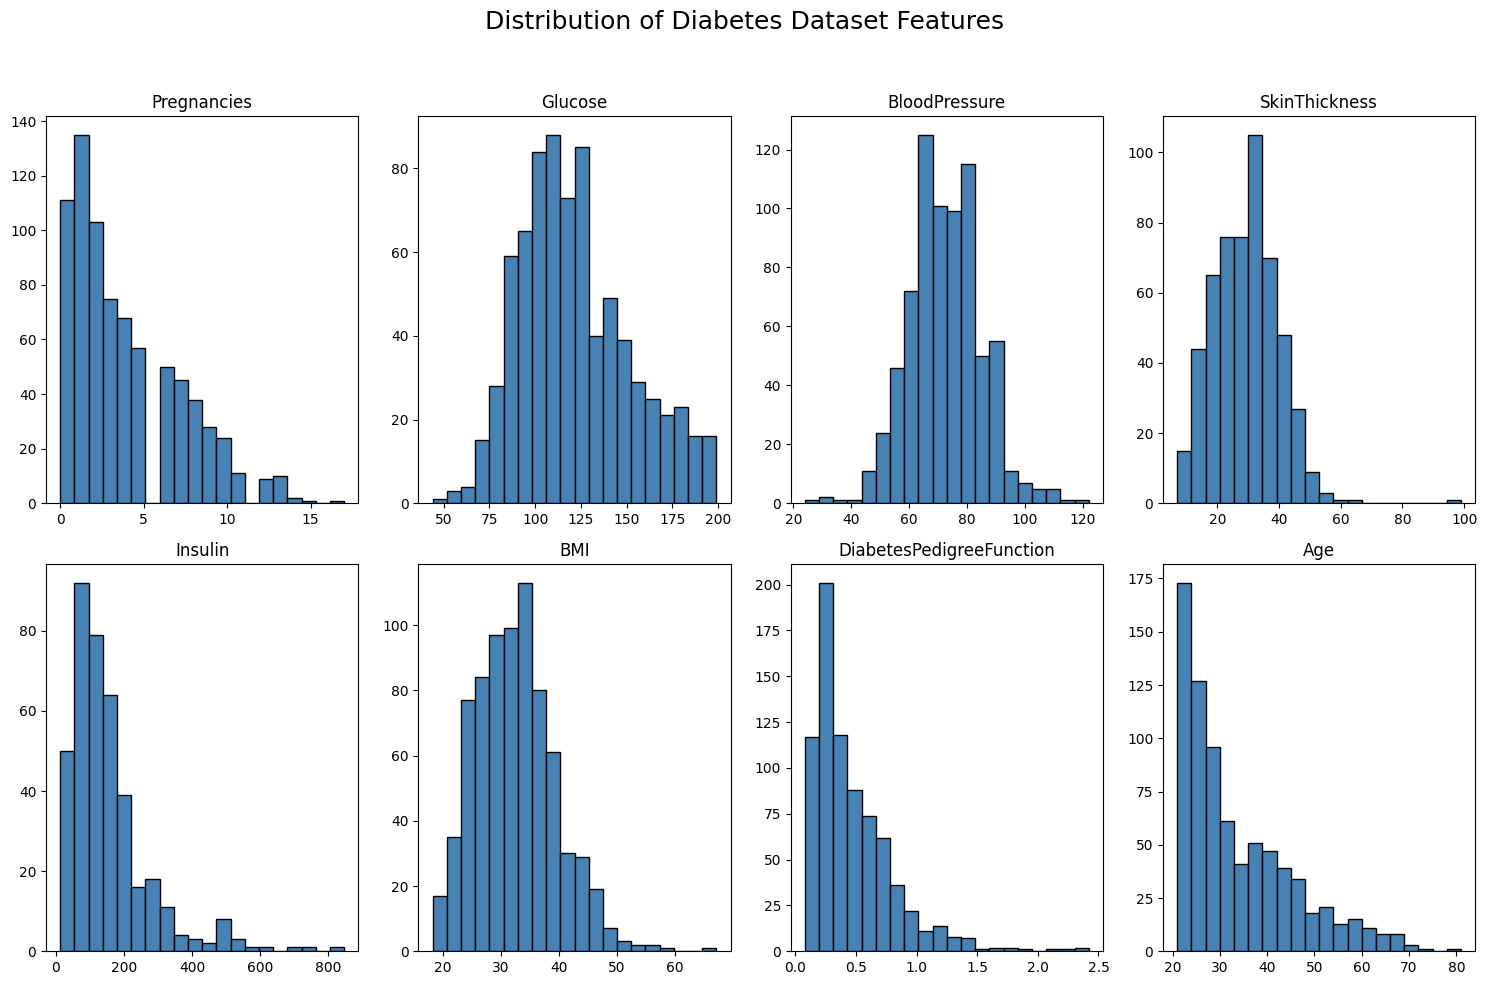

In [ ]:
# Visualize the distribution of all input features

df.drop(columns='Outcome').hist(
    figsize=(15, 10),
    bins=20,
    color='steelblue',
    edgecolor='black',
    grid=False,
    layout=(2, 4)
)

plt.suptitle(
    'Distribution of Diabetes Dataset Features',
    fontsize=18
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


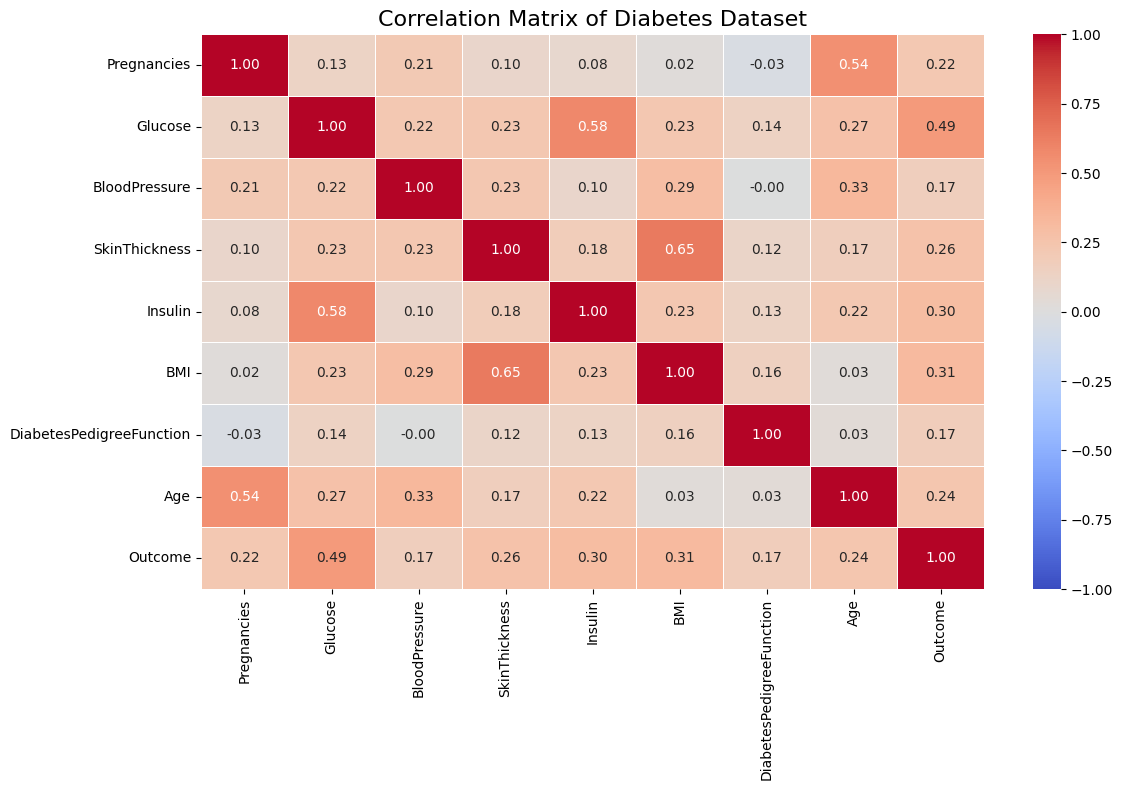

In [ ]:
# Generate correlation matrix heatmap

correlation_matrix = df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Correlation Matrix of Diabetes Dataset', fontsize=16)
plt.tight_layout()
plt.show()


In [ ]:
# Display feature correlations with diabetes outcome

outcome_correlation = (
    correlation_matrix['Outcome']
    .drop('Outcome')
    .sort_values(ascending=False)
)

print("Feature Correlations with Diabetes Outcome:\n")
print(outcome_correlation.round(4))

Feature Correlations with Diabetes Outcome:

Glucose                     0.4947
BMI                         0.3137
Insulin                     0.3035
SkinThickness               0.2595
Age                         0.2384
Pregnancies                 0.2219
DiabetesPedigreeFunction    0.1738
BloodPressure               0.1706
Name: Outcome, dtype: float64


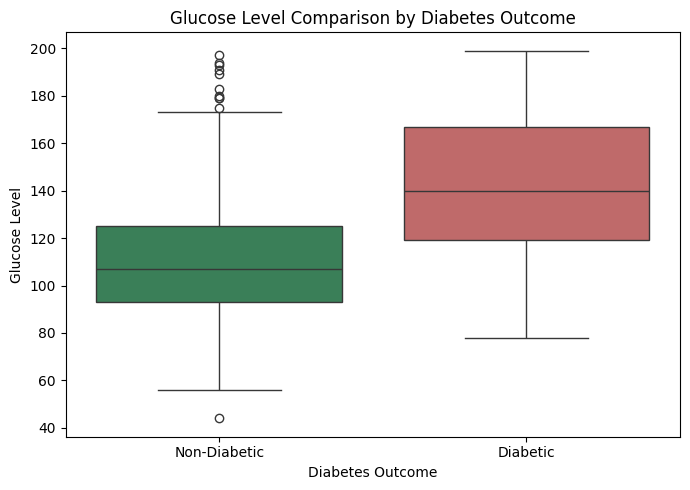

In [ ]:
# Compare glucose levels by diabetes outcome

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='Outcome',
    y='Glucose',
    hue='Outcome',
    palette=['seagreen', 'indianred'],
    legend=False
)

plt.title('Glucose Level Comparison by Diabetes Outcome')
plt.xlabel('Diabetes Outcome')
plt.ylabel('Glucose Level')
plt.xticks([0, 1], ['Non-Diabetic', 'Diabetic'])
plt.tight_layout()
plt.show()


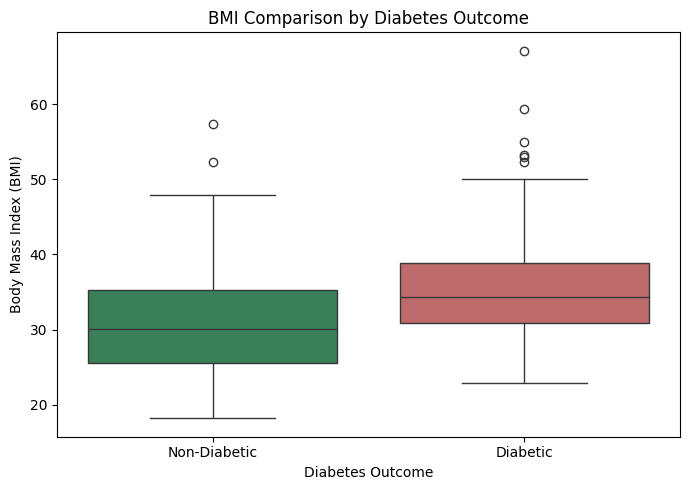

In [ ]:
# Compare BMI by diabetes outcome

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='Outcome',
    y='BMI',
    hue='Outcome',
    palette=['seagreen', 'indianred'],
    legend=False
)

plt.title('BMI Comparison by Diabetes Outcome')
plt.xlabel('Diabetes Outcome')
plt.ylabel('Body Mass Index (BMI)')
plt.xticks([0, 1], ['Non-Diabetic', 'Diabetic'])
plt.tight_layout()
plt.show()


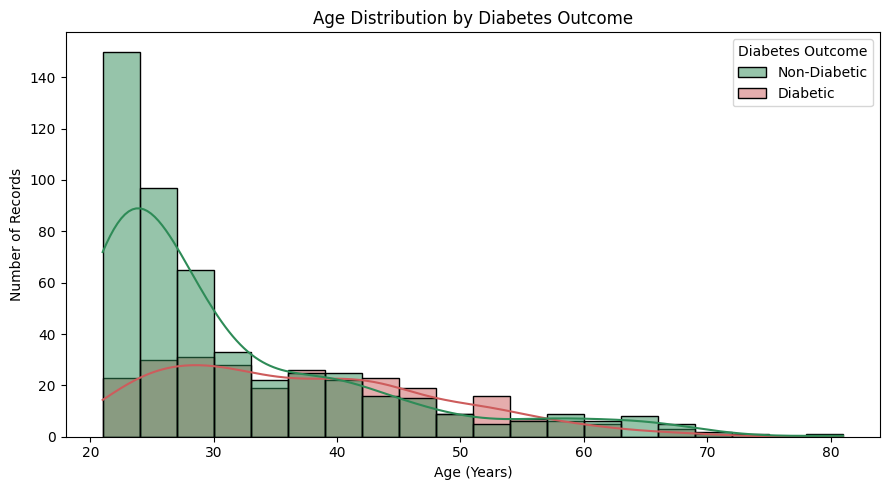

In [ ]:
# Compare age distribution by diabetes outcome

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='Age',
    hue='Outcome',
    hue_order=[0, 1],
    palette=['seagreen', 'indianred'],
    bins=20,
    kde=True,
    alpha=0.5,
    multiple='layer'
)

plt.title('Age Distribution by Diabetes Outcome')
plt.xlabel('Age (Years)')
plt.ylabel('Number of Records')

legend = plt.gca().get_legend()
legend.set_title('Diabetes Outcome')

for text, label in zip(
    legend.get_texts(),
    ['Non-Diabetic', 'Diabetic']
):
    text.set_text(label)

plt.tight_layout()
plt.show()


In [ ]:
# Compare average feature values by diabetes outcome

group_means = df.groupby('Outcome').mean().T

group_means.columns = ['Non-Diabetic', 'Diabetic']

print("Average Feature Values by Diabetes Outcome:\n")

display(group_means.round(2))

Average Feature Values by Diabetes Outcome:



,Non-Diabetic,Diabetic
Pregnancies,3.30,4.87
Glucose,110.64,142.32
BloodPressure,70.88,75.32
SkinThickness,27.24,33.00
Insulin,130.29,206.85
BMI,30.86,35.41
DiabetesPedigreeFunction,0.43,0.55
Age,31.19,37.07


**OBSERVATIONS FROM EXPLORATORY DATA ANALYSIS**

1. The dataset contains 768 records, including 500 non-diabetic and 268 diabetic records, indicating moderate class imbalance.

2. Glucose has the strongest positive correlation with diabetes outcome (0.4947), followed by BMI (0.3137) and Insulin (0.3035).

3. The average glucose level of diabetic records is 142.32, compared to 110.64 for non-diabetic records.

4. The diabetic group has a higher average BMI of 35.41 compared to 30.86 in the non-diabetic group.

5. The average age of the diabetic group is 37.07 years, whereas the non-diabetic group has an average age of 31.19 years.

6. Features such as Insulin, Age, Pregnancies and DiabetesPedigreeFunction exhibit right-skewed distributions.

7. The exploratory analysis reveals associations between the input features and diabetes outcome. However, correlation does not establish causation.

8. Class imbalance and overlapping feature distributions may contribute to the model's lower recall for diabetic records.

**INTERACTIVE PREDICTION USING BASELINE KNN**

In [ ]:
# Create a function for diabetes prediction

def predict_diabetes(input_data):

    # Convert input data into a DataFrame
    input_df = pd.DataFrame(
        [input_data],
        columns=X_train.columns
    )

    # Replace invalid zero values with NaN
    input_df[columns_to_check] = (
        input_df[columns_to_check].replace(0, np.nan)
    )

    # Predict diabetes outcome
    prediction = knn_model.predict(input_df)[0]

    # Calculate class probabilities
    probabilities = knn_model.predict_proba(input_df)[0]

    return prediction, probabilities


print("Diabetes prediction function created successfully!")


Diabetes prediction function created successfully!


In [ ]:
# Test the model with sample input data

sample_data = [
    2,       # Pregnancies
    120,     # Glucose
    72,      # Blood Pressure
    25,      # Skin Thickness
    100,     # Insulin
    28.5,    # BMI
    0.350,   # Diabetes Pedigree Function
    30       # Age
]

prediction, probabilities = predict_diabetes(sample_data)

print("Sample Diabetes Prediction:\n")

if prediction == 0:
    print("Predicted Outcome: Non-Diabetic")
else:
    print("Predicted Outcome: Diabetic")

print(f"\nNon-Diabetic Probability: {probabilities[0] * 100:.2f}%")
print(f"Diabetic Probability: {probabilities[1] * 100:.2f}%")


Sample Diabetes Prediction:

Predicted Outcome: Non-Diabetic

Non-Diabetic Probability: 61.54%
Diabetic Probability: 38.46%


In [ ]:
# Accept user input for diabetes prediction

print("=" * 50)
print("       DIABETES PREDICTION USING KNN")
print("=" * 50)

print("\nEnter the following details:\n")

try:
    pregnancies = int(input("Number of Pregnancies: "))
    glucose = float(input("Glucose Level: "))
    blood_pressure = float(input("Blood Pressure: "))
    skin_thickness = float(input("Skin Thickness: "))
    insulin = float(input("Insulin Level: "))
    bmi = float(input("BMI: "))
    dpf = float(input("Diabetes Pedigree Function: "))
    age = int(input("Age: "))

    user_data = [
        pregnancies,
        glucose,
        blood_pressure,
        skin_thickness,
        insulin,
        bmi,
        dpf,
        age
    ]

    # Validate input values
    if any(not np.isfinite(value) or value < 0
           for value in user_data):
        print("\nInvalid input! Enter finite, non-negative values.")

    elif age < 21:
        print("\nInvalid input! This dataset represents adults aged 21 or above.")

    else:
        # Generate prediction
        prediction, probabilities = predict_diabetes(user_data)

        print("\n" + "=" * 50)
        print("              PREDICTION RESULT")
        print("=" * 50)

        if prediction == 0:
            print("\nPredicted Outcome: Non-Diabetic")
        else:
            print("\nPredicted Outcome: Diabetic")

        print(f"\nNon-Diabetic Probability: {probabilities[0] * 100:.2f}%")
        print(f"Diabetic Probability: {probabilities[1] * 100:.2f}%")

        print("\nOptimal K Value:", best_k)

        print("=" * 50)

except ValueError:
    print("\nInvalid input! Please enter numerical values.")


       DIABETES PREDICTION USING KNN

Enter the following details:

Number of Pregnancies: 1
Glucose Level: 95
Blood Pressure: 70
Skin Thickness: 20
Insulin Level: 85
BMI: 23.5
Diabetes Pedigree Function: 0.200
Age: 25

              PREDICTION RESULT

Predicted Outcome: Non-Diabetic

Non-Diabetic Probability: 100.00%
Diabetic Probability: 0.00%

Optimal K Value: 13


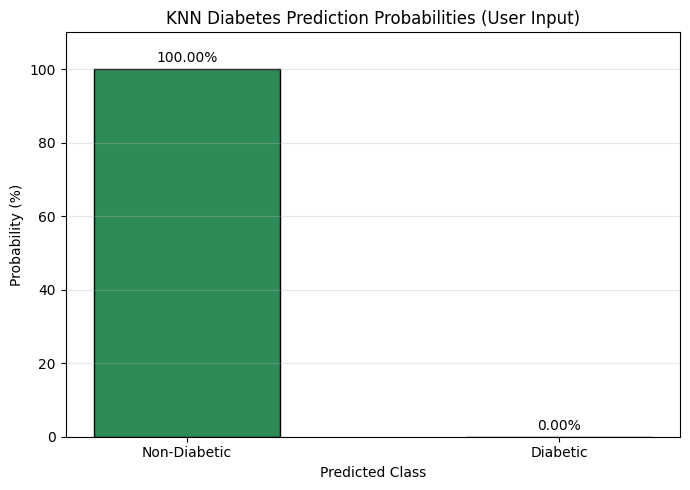

In [ ]:
# Visualize user input prediction probabilities

user_prediction, user_probabilities = predict_diabetes(
    user_data
)

labels = ['Non-Diabetic', 'Diabetic']
probability_values = user_probabilities * 100

plt.figure(figsize=(7, 5))

bars = plt.bar(
    labels,
    probability_values,
    color=['seagreen', 'indianred'],
    width=0.5,
    edgecolor='black'
)

plt.bar_label(
    bars,
    fmt='%.2f%%',
    padding=3
)

plt.title('KNN Diabetes Prediction Probabilities (User Input)')
plt.xlabel('Predicted Class')
plt.ylabel('Probability (%)')
plt.ylim(0, 110)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


**BASELINE MODEL PRESERVATION AND PERFORMANCE BENCHMARKING**

The initial KNN model is preserved as the baseline model for
comparison with subsequent optimized versions.

Additional cross-validation metrics are calculated to establish
a consistent evaluation framework for model optimization.

The objective is to improve classification performance,
particularly recall and F1-score, while maintaining a reasonable
level of accuracy and precision.

In [ ]:
# Preserve the original baseline KNN model

from copy import deepcopy

baseline_model = deepcopy(knn_model)

baseline_params = {
    'Number of Neighbors (K)': baseline_model.named_steps['knn'].n_neighbors,
    'Neighbor Weights': baseline_model.named_steps['knn'].weights,
    'Distance Metric': baseline_model.named_steps['knn'].effective_metric_,
    'Missing Value Treatment': baseline_model.named_steps['imputer'].strategy,
    'Feature Scaling': type(baseline_model.named_steps['scaler']).__name__,
    'Class Balancing': 'None',
    'Optimization Metric': 'Accuracy'
}

print("Baseline KNN model preserved successfully!")
print("\nBaseline Model Configuration:\n")

for parameter, value in baseline_params.items():
    print(f"{parameter}: {value}")

Baseline KNN model preserved successfully!

Baseline Model Configuration:

Number of Neighbors (K): 13
Neighbor Weights: uniform
Distance Metric: euclidean
Missing Value Treatment: median
Feature Scaling: StandardScaler
Class Balancing: None
Optimization Metric: Accuracy


In [ ]:
# Establish a common evaluation strategy

from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer

comparison_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'roc_auc': 'roc_auc'
}

print("Common evaluation strategy established successfully!")
print("\nCross-Validation Configuration:")
print("Method: Stratified K-Fold Cross-Validation")
print("Number of Folds:", comparison_cv.n_splits)
print("Random State:", comparison_cv.random_state)
print("Primary Model Selection Metric: F1-Score")

print("\nEvaluation Metrics:")
for metric in scoring_metrics:
    print("-", metric)

Common evaluation strategy established successfully!

Cross-Validation Configuration:
Method: Stratified K-Fold Cross-Validation
Number of Folds: 5
Random State: 42
Primary Model Selection Metric: F1-Score

Evaluation Metrics:
- accuracy
- precision
- recall
- f1
- roc_auc


In [ ]:
# Calculate additional baseline cross-validation metrics

baseline_cv_results = cross_validate(
    estimator=baseline_model,
    X=X_train,
    y=y_train,
    cv=comparison_cv,
    scoring=scoring_metrics,
    n_jobs=-1
)

baseline_cv_summary = {}

print("Baseline KNN Cross-Validation Performance:\n")

for metric in scoring_metrics:

    scores = baseline_cv_results[f'test_{metric}']

    mean_score = scores.mean()
    std_score = scores.std()

    baseline_cv_summary[metric] = mean_score

    print(
        f"{metric.upper():10s}: "
        f"{mean_score * 100:.2f}% "
        f"(+/- {std_score * 100:.2f} percentage points)"
    )

Baseline KNN Cross-Validation Performance:

ACCURACY  : 77.52% (+/- 4.17 percentage points)
PRECISION : 72.10% (+/- 10.10 percentage points)
RECALL    : 60.32% (+/- 4.83 percentage points)
F1        : 65.32% (+/- 5.15 percentage points)
ROC_AUC   : 82.82% (+/- 2.83 percentage points)


In [ ]:
# Preserve baseline model testing performance

baseline_train_pred = baseline_model.predict(X_train)
baseline_test_pred = baseline_model.predict(X_test)
baseline_test_prob = baseline_model.predict_proba(X_test)[:, 1]

baseline_cm = confusion_matrix(
    y_test,
    baseline_test_pred,
    labels=[0, 1]
)

baseline_tn, baseline_fp, baseline_fn, baseline_tp = (
    baseline_cm.ravel()
)

baseline_test_summary = {
    'Training Accuracy': accuracy_score(
        y_train, baseline_train_pred
    ),
    'Testing Accuracy': accuracy_score(
        y_test, baseline_test_pred
    ),
    'Precision': precision_score(
        y_test, baseline_test_pred, zero_division=0
    ),
    'Recall': recall_score(
        y_test, baseline_test_pred, zero_division=0
    ),
    'F1-Score': f1_score(
        y_test, baseline_test_pred, zero_division=0
    ),
    'ROC-AUC': roc_auc_score(
        y_test, baseline_test_prob
    )
}

print("Baseline Model Testing Performance:\n")

for metric, value in baseline_test_summary.items():
    print(f"{metric:20s}: {value * 100:.2f}%")

print("\nBaseline Confusion Matrix:")
print(baseline_cm)

print("\nTrue Negatives:", baseline_tn)
print("False Positives:", baseline_fp)
print("False Negatives:", baseline_fn)
print("True Positives:", baseline_tp)

print("\nBaseline testing performance preserved successfully!")

Baseline Model Testing Performance:

Training Accuracy   : 80.62%
Testing Accuracy    : 71.43%
Precision           : 60.87%
Recall              : 51.85%
F1-Score            : 56.00%
ROC-AUC             : 79.44%

Baseline Confusion Matrix:
[[82 18]
 [26 28]]

True Negatives: 82
False Positives: 18
False Negatives: 26
True Positives: 28

Baseline testing performance preserved successfully!


In [ ]:
# Initialize the model performance comparison table

model_results = [
    {
        'Model': 'Version 1 - Baseline KNN',
        'Optimal K': baseline_model.named_steps['knn'].n_neighbors,
        'Weights': baseline_model.named_steps['knn'].weights,
        'Distance Metric': baseline_model.named_steps['knn'].effective_metric_,
        'Imputation': 'Median',
        'Scaler': 'StandardScaler',
        'SMOTE': 'No',
        'Selection Metric': 'Accuracy',
        'CV Accuracy (%)': baseline_cv_summary['accuracy'] * 100,
        'CV Precision (%)': baseline_cv_summary['precision'] * 100,
        'CV Recall (%)': baseline_cv_summary['recall'] * 100,
        'CV F1-Score (%)': baseline_cv_summary['f1'] * 100,
        'CV ROC-AUC': baseline_cv_summary['roc_auc']
    }
]

comparison_df = pd.DataFrame(model_results)

print("Model Performance Comparison Table:\n")

display(comparison_df.round(4))

print("\nBaseline model successfully added to the comparison table!")

Model Performance Comparison Table:



,Model,Optimal K,Weights,Distance Metric,Imputation,Scaler,SMOTE,Selection Metric,CV Accuracy (%),CV Precision (%),CV Recall (%),CV F1-Score (%),CV ROC-AUC
0,Version 1 - Baseline KNN,13,uniform,euclidean,Median,StandardScaler,No,Accuracy,77.5237,72.0985,60.3212,65.3198,0.8282



Baseline model successfully added to the comparison table!


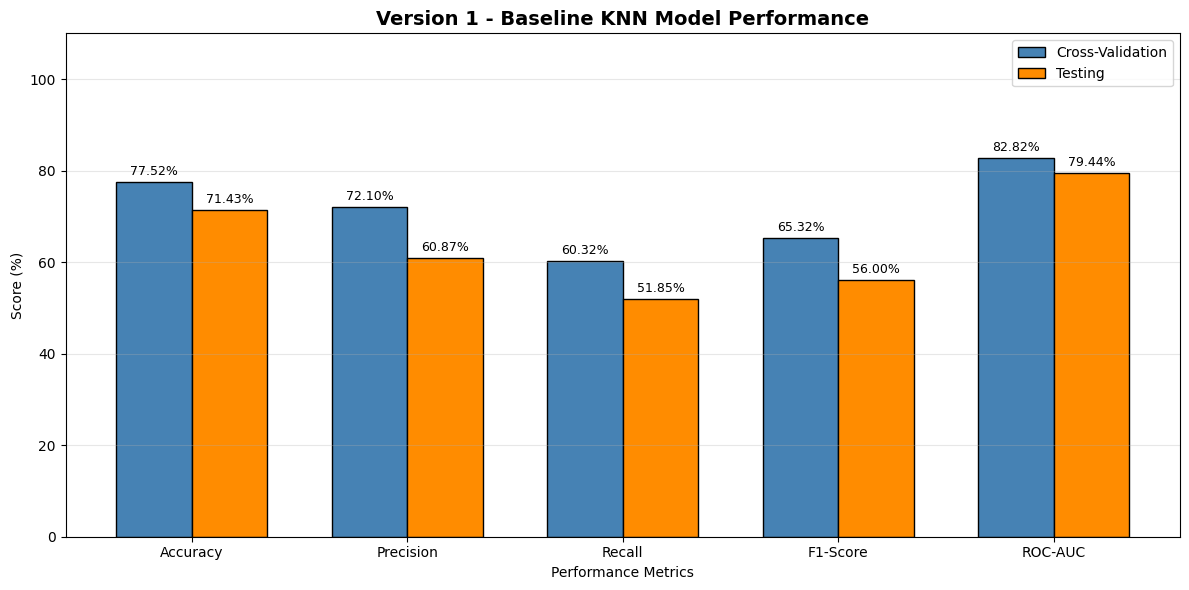

In [ ]:
# Visualize baseline cross-validation and testing performance

metric_names = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score',
    'ROC-AUC'
]

cv_values = [
    baseline_cv_summary['accuracy'] * 100,
    baseline_cv_summary['precision'] * 100,
    baseline_cv_summary['recall'] * 100,
    baseline_cv_summary['f1'] * 100,
    baseline_cv_summary['roc_auc'] * 100
]

test_values = [
    baseline_test_summary['Testing Accuracy'] * 100,
    baseline_test_summary['Precision'] * 100,
    baseline_test_summary['Recall'] * 100,
    baseline_test_summary['F1-Score'] * 100,
    baseline_test_summary['ROC-AUC'] * 100
]

x = np.arange(len(metric_names))
width = 0.35

plt.figure(figsize=(12, 6))

bars1 = plt.bar(
    x - width / 2,
    cv_values,
    width,
    label='Cross-Validation',
    color='steelblue',
    edgecolor='black'
)

bars2 = plt.bar(
    x + width / 2,
    test_values,
    width,
    label='Testing',
    color='darkorange',
    edgecolor='black'
)

plt.bar_label(bars1, fmt='%.2f%%', padding=3, fontsize=9)
plt.bar_label(bars2, fmt='%.2f%%', padding=3, fontsize=9)

plt.title(
    'Version 1 - Baseline KNN Model Performance',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Performance Metrics')
plt.ylabel('Score (%)')
plt.xticks(x, metric_names)
plt.ylim(0, 110)
plt.legend(loc='upper right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**BASELINE MODEL ANALYSIS AND MOTIVATION FOR OPTIMIZATION**

The initial KNN model was developed using median imputation, standard feature scaling, uniform neighbor weights and Euclidean distance. The optimal number of neighbors was determined to be 13 using five-fold stratified cross-validation.

**Observations**

1. The baseline model achieved a cross-validation accuracy of 77.52% and a testing accuracy of 71.43%.

2. The training accuracy of 80.62% was higher than the testing accuracy by 9.19 percentage points, suggesting possible overfitting or limited generalization.

3. The testing recall of 51.85% indicates that the model correctly identified only slightly more than half of the actual diabetic records.

4. The model produced 26 false-negative predictions out of 54 actual diabetic records.

5. The testing F1-score of 56.00% indicates considerable scope for improving the balance between precision and recall.

6. The initial hyperparameter optimization considered only the number of nearest neighbors.

7. The dataset contains class imbalance, which may contribute to reduced minority-class classification performance.

8. The ROC-AUC score of 0.7944 demonstrates reasonable class discrimination, although further improvements can be explored.

**Proposed Optimization Strategies**

- Version 2: Advanced hyperparameter optimization involving K values, neighbor weights and distance metrics.
- Version 3: Class imbalance treatment using SMOTE.
- Version 4: Advanced preprocessing and feature scaling experiments.

**Optimization Objective**

The primary objective of subsequent experiments is to improve F1-score and recall while maintaining reasonable accuracy, precision and ROC-AUC performance.

All model development experiments will use consistent stratified cross-validation splits. The testing dataset will not be used for hyperparameter selection.

The final model will be selected based on measured performance rather than the number of optimization techniques applied.

**VERSION 2: HYPERPARAMETER-OPTIMIZED KNN MODEL**

The second version of the KNN model introduces advanced
hyperparameter optimization to improve classification performance.

Unlike the baseline model, which optimized only the number of
nearest neighbors, this version simultaneously optimizes:

- Number of nearest neighbors (K)
- Neighbor weighting method
- Distance metric

GridSearchCV with five-fold stratified cross-validation is used
to identify the best hyperparameter combination.

F1-score is used as the primary model selection metric to
achieve a better balance between precision and recall.

The preprocessing techniques remain unchanged to allow
comparison with the baseline model.

In [ ]:
# Create the Version 2 KNN model pipeline

knn_pipeline_v2 = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

print("Version 2 KNN pipeline created successfully!")

print("\nPipeline Configuration:")

for step_name, step in knn_pipeline_v2.steps:
    print(f"{step_name}: {type(step).__name__}")

Version 2 KNN pipeline created successfully!

Pipeline Configuration:
imputer: SimpleImputer
scaler: StandardScaler
knn: KNeighborsClassifier


In [ ]:
# Define the advanced hyperparameter search space

from sklearn.model_selection import ParameterGrid

param_grid_v2 = {
    'knn__n_neighbors': list(range(1, 42, 2)),
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': [
        'euclidean',
        'manhattan',
        'chebyshev'
    ]
}

total_combinations_v2 = len(
    list(ParameterGrid(param_grid_v2))
)

total_fits_v2 = (
    total_combinations_v2 * comparison_cv.n_splits
)

print("Version 2 Hyperparameter Search Space:\n")

print("K Values:", param_grid_v2['knn__n_neighbors'])
print("Neighbor Weights:", param_grid_v2['knn__weights'])
print("Distance Metrics:", param_grid_v2['knn__metric'])

print("\nTotal Hyperparameter Combinations:",
      total_combinations_v2)

print("Number of Cross-Validation Folds:",
      comparison_cv.n_splits)

print("Total Cross-Validation Model Fits:",
      total_fits_v2)

Version 2 Hyperparameter Search Space:

K Values: [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31, 33, 35, 37, 39, 41]
Neighbor Weights: ['uniform', 'distance']
Distance Metrics: ['euclidean', 'manhattan', 'chebyshev']

Total Hyperparameter Combinations: 126
Number of Cross-Validation Folds: 5
Total Cross-Validation Model Fits: 630


In [ ]:
# Perform advanced hyperparameter optimization

grid_search_v2 = GridSearchCV(
    estimator=knn_pipeline_v2,
    param_grid=param_grid_v2,
    cv=comparison_cv,
    scoring=scoring_metrics,
    refit='f1',
    n_jobs=-1,
    return_train_score=True
)

print("Starting Version 2 hyperparameter optimization...")
print("Please wait while the models are evaluated.\n")

grid_search_v2.fit(X_train, y_train)

optimized_model_v2 = grid_search_v2.best_estimator_

best_params_v2 = grid_search_v2.best_params_

best_k_v2 = best_params_v2['knn__n_neighbors']
best_weights_v2 = best_params_v2['knn__weights']
best_metric_v2 = best_params_v2['knn__metric']

print("Hyperparameter optimization completed successfully!")

print("\nOptimal Hyperparameter Configuration:\n")

print("Optimal K Value:", best_k_v2)
print("Optimal Neighbor Weights:", best_weights_v2)
print("Optimal Distance Metric:", best_metric_v2)

print(
    f"\nBest Cross-Validation F1-Score: "
    f"{grid_search_v2.best_score_ * 100:.2f}%"
)

Starting Version 2 hyperparameter optimization...
Please wait while the models are evaluated.

Hyperparameter optimization completed successfully!

Optimal Hyperparameter Configuration:

Optimal K Value: 13
Optimal Neighbor Weights: uniform
Optimal Distance Metric: euclidean

Best Cross-Validation F1-Score: 65.32%


In [ ]:
# Extract cross-validation performance of Version 2

best_index_v2 = grid_search_v2.best_index_

v2_cv_summary = {}

print("Version 2 - Optimized KNN Cross-Validation Performance:\n")

for metric in scoring_metrics:

    mean_score = grid_search_v2.cv_results_[
        f'mean_test_{metric}'
    ][best_index_v2]

    std_score = grid_search_v2.cv_results_[
        f'std_test_{metric}'
    ][best_index_v2]

    v2_cv_summary[metric] = mean_score

    print(
        f"{metric.upper():10s}: "
        f"{mean_score * 100:.2f}% "
        f"(+/- {std_score * 100:.2f} percentage points)"
    )

Version 2 - Optimized KNN Cross-Validation Performance:

ACCURACY  : 77.52% (+/- 4.17 percentage points)
PRECISION : 72.10% (+/- 10.10 percentage points)
RECALL    : 60.32% (+/- 4.83 percentage points)
F1        : 65.32% (+/- 5.15 percentage points)
ROC_AUC   : 82.82% (+/- 2.83 percentage points)


In [ ]:
# Display the top 10 hyperparameter combinations

v2_search_results = pd.DataFrame(
    grid_search_v2.cv_results_
)

top_10_v2 = v2_search_results[[
    'param_knn__n_neighbors',
    'param_knn__weights',
    'param_knn__metric',
    'mean_test_accuracy',
    'mean_test_precision',
    'mean_test_recall',
    'mean_test_f1',
    'mean_test_roc_auc',
    'rank_test_f1'
]].copy()

top_10_v2.columns = [
    'K',
    'Weights',
    'Distance Metric',
    'Accuracy (%)',
    'Precision (%)',
    'Recall (%)',
    'F1-Score (%)',
    'ROC-AUC',
    'Rank'
]

percentage_columns = [
    'Accuracy (%)',
    'Precision (%)',
    'Recall (%)',
    'F1-Score (%)'
]

top_10_v2[percentage_columns] = (
    top_10_v2[percentage_columns] * 100
)

top_10_v2 = (
    top_10_v2
    .sort_values('Rank')
    .head(10)
    .reset_index(drop=True)
)

print("Top 10 Hyperparameter Combinations:\n")

display(top_10_v2.round(4))

Top 10 Hyperparameter Combinations:



,K,Weights,Distance Metric,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC,Rank
0,13,uniform,euclidean,77.5237,72.0985,60.3212,65.3198,0.8282,1
1,13,distance,euclidean,77.3611,71.5641,60.3212,65.1067,0.8289,2
2,7,distance,chebyshev,76.2202,67.2077,63.1118,64.8461,0.8026,3
3,7,uniform,chebyshev,76.0589,67.4627,62.1816,64.4541,0.7988,4
4,17,distance,chebyshev,76.8706,70.6991,59.3798,64.2140,0.8173,5
5,9,distance,euclidean,76.2162,69.0180,59.3355,63.6552,0.8170,6
6,7,uniform,manhattan,76.5401,70.3719,58.4164,63.5740,0.8060,7
7,15,uniform,euclidean,76.8733,71.8961,57.0653,63.1865,0.8318,8
8,17,distance,euclidean,76.5467,70.8655,57.0432,62.9162,0.8332,9
9,15,distance,euclidean,76.5467,71.0870,57.0653,62.8538,0.8328,10


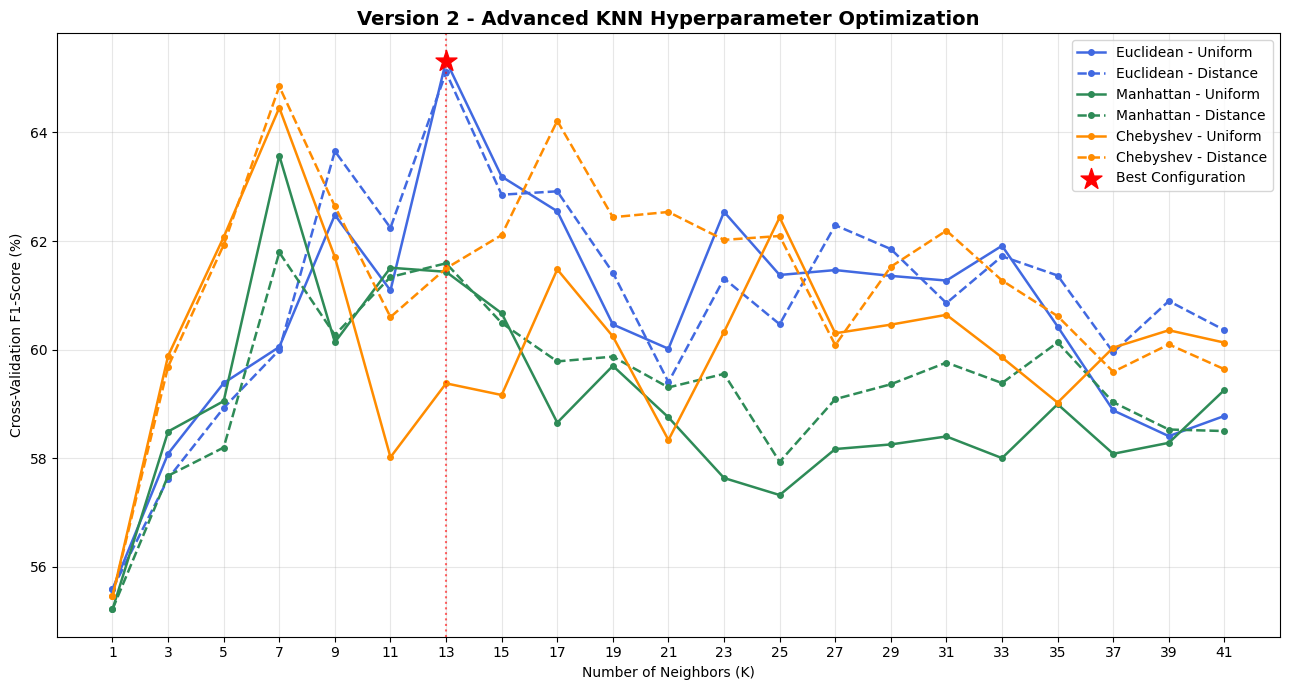

In [ ]:
# Visualize the effect of different K values, distance metrics and neighbor
# weights

plt.figure(figsize=(13, 7))

colors = {
    'euclidean': 'royalblue',
    'manhattan': 'seagreen',
    'chebyshev': 'darkorange'
}

line_styles = {
    'uniform': '-',
    'distance': '--'
}

for metric in param_grid_v2['knn__metric']:

    for weights in param_grid_v2['knn__weights']:

        subset = v2_search_results[
            (v2_search_results['param_knn__metric'] == metric) &
            (v2_search_results['param_knn__weights'] == weights)
        ].sort_values('param_knn__n_neighbors')

        plt.plot(
            subset['param_knn__n_neighbors'].astype(int),
            subset['mean_test_f1'] * 100,
            marker='o',
            markersize=4,
            color=colors[metric],
            linestyle=line_styles[weights],
            linewidth=1.8,
            label=f'{metric.capitalize()} - {weights.capitalize()}'
        )

plt.scatter(
    best_k_v2,
    grid_search_v2.best_score_ * 100,
    color='red',
    marker='*',
    s=250,
    zorder=5,
    label='Best Configuration'
)

plt.axvline(
    x=best_k_v2,
    color='red',
    linestyle=':',
    alpha=0.6
)

plt.title(
    'Version 2 - Advanced KNN Hyperparameter Optimization',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Cross-Validation F1-Score (%)')

plt.xticks(param_grid_v2['knn__n_neighbors'])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Add Version 2 results to the model comparison table

v2_result = {
    'Model': 'Version 2 - Hyperparameter Optimized KNN',
    'Optimal K': best_k_v2,
    'Weights': best_weights_v2,
    'Distance Metric': best_metric_v2,
    'Imputation': 'Median',
    'Scaler': 'StandardScaler',
    'SMOTE': 'No',
    'Selection Metric': 'F1-Score',
    'CV Accuracy (%)': v2_cv_summary['accuracy'] * 100,
    'CV Precision (%)': v2_cv_summary['precision'] * 100,
    'CV Recall (%)': v2_cv_summary['recall'] * 100,
    'CV F1-Score (%)': v2_cv_summary['f1'] * 100,
    'CV ROC-AUC': v2_cv_summary['roc_auc']
}

# Prevent duplicate entries if the cell is executed again

model_results = [
    result for result in model_results
    if result['Model'] != v2_result['Model']
]

model_results.append(v2_result)

comparison_df = pd.DataFrame(model_results)

print("Updated Model Performance Comparison Table:\n")

display(comparison_df.round(4))

print("\nVersion 2 successfully added to the comparison table!")

Updated Model Performance Comparison Table:



,Model,Optimal K,Weights,Distance Metric,Imputation,Scaler,SMOTE,Selection Metric,CV Accuracy (%),CV Precision (%),CV Recall (%),CV F1-Score (%),CV ROC-AUC
0,Version 1 - Baseline KNN,13,uniform,euclidean,Median,StandardScaler,No,Accuracy,77.5237,72.0985,60.3212,65.3198,0.8282
1,Version 2 - Hyperparameter Optimized KNN,13,uniform,euclidean,Median,StandardScaler,No,F1-Score,77.5237,72.0985,60.3212,65.3198,0.8282



Version 2 successfully added to the comparison table!


In [ ]:
# Calculate performance changes from Version 1 to Version 2

metric_labels = {
    'accuracy': 'Accuracy',
    'precision': 'Precision',
    'recall': 'Recall',
    'f1': 'F1-Score',
    'roc_auc': 'ROC-AUC'
}

v2_improvement = []

for metric, label in metric_labels.items():

    baseline_value = baseline_cv_summary[metric] * 100
    optimized_value = v2_cv_summary[metric] * 100

    difference = optimized_value - baseline_value

    if np.isclose(difference, 0):
        difference = 0.0
        status = 'No Change'
    elif difference > 0:
        status = 'Improved'
    else:
        status = 'Decreased'

    v2_improvement.append({
        'Metric': label,
        'Version 1 (%)': baseline_value,
        'Version 2 (%)': optimized_value,
        'Change (pp)': difference,
        'Status': status
    })

v2_improvement_df = pd.DataFrame(v2_improvement)

print("Version 1 vs Version 2 - Performance Changes:\n")

display(v2_improvement_df.round(2))

Version 1 vs Version 2 - Performance Changes:



,Metric,Version 1 (%),Version 2 (%),Change (pp),Status
0,Accuracy,77.52,77.52,0.0,No Change
1,Precision,72.10,72.10,0.0,No Change
2,Recall,60.32,60.32,0.0,No Change
3,F1-Score,65.32,65.32,0.0,No Change
4,ROC-AUC,82.82,82.82,0.0,No Change


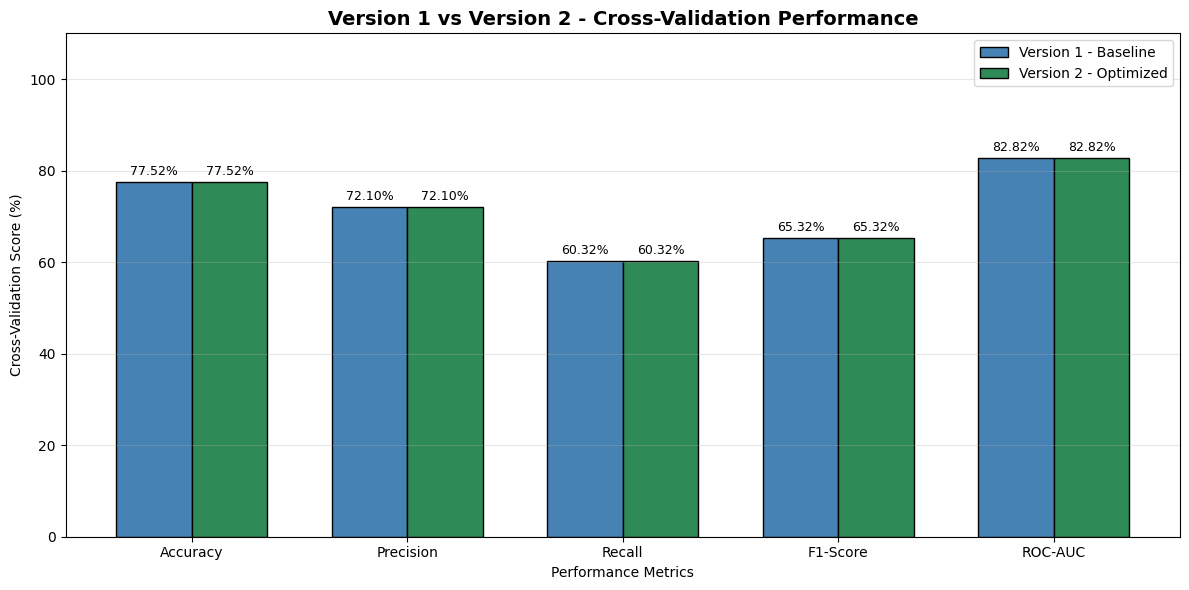

In [ ]:
# Compare Version 1 and Version 2 visually

metric_names = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score',
    'ROC-AUC'
]

baseline_values = [
    baseline_cv_summary[metric] * 100
    for metric in scoring_metrics
]

v2_values = [
    v2_cv_summary[metric] * 100
    for metric in scoring_metrics
]

x = np.arange(len(metric_names))
width = 0.35

plt.figure(figsize=(12, 6))

bars1 = plt.bar(
    x - width / 2,
    baseline_values,
    width,
    label='Version 1 - Baseline',
    color='steelblue',
    edgecolor='black'
)

bars2 = plt.bar(
    x + width / 2,
    v2_values,
    width,
    label='Version 2 - Optimized',
    color='seagreen',
    edgecolor='black'
)

plt.bar_label(
    bars1,
    fmt='%.2f%%',
    padding=3,
    fontsize=9
)

plt.bar_label(
    bars2,
    fmt='%.2f%%',
    padding=3,
    fontsize=9
)

plt.title(
    'Version 1 vs Version 2 - Cross-Validation Performance',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Performance Metrics')
plt.ylabel('Cross-Validation Score (%)')
plt.xticks(x, metric_names)
plt.ylim(0, 110)
plt.legend(loc='upper right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**VERSION 2: EXPERIMENTAL OBSERVATIONS AND ANALYSIS**

1. The hyperparameter search space was expanded from 11 combinations to 126 combinations.

2. A total of 630 cross-validation model fits were performed using five-fold stratified cross-validation.

3. Three hyperparameters were optimized simultaneously: number of nearest neighbors, neighbor weights and distance metric.

4. The primary model selection metric was changed from accuracy to F1-score.

5. The best-performing configuration was found to be:
   - Number of Neighbors: 13
   - Neighbor Weights: Uniform
   - Distance Metric: Euclidean

6. The optimized configuration was identical to the original baseline model.

7. The model achieved a cross-validation accuracy of 77.52%, precision of 72.10%, recall of 60.32%, F1-score of 65.32% and ROC-AUC score of 0.8282.

8. No measurable improvement was observed in the cross-validation performance metrics compared with the baseline model.

9. The expanded search confirmed that the original hyperparameter configuration was already the best-performing configuration within the investigated search space and evaluation framework.

10. Further optimization is required to improve minority-class classification performance, particularly recall and F1-score.

**Conclusion of Version 2**

Advanced hyperparameter tuning alone did not improve the baseline model's performance. Therefore, the next experiment will investigate class imbalance treatment using SMOTE to determine whether improved representation of the minority class can enhance classification performance.

The testing dataset was not used during Version 2 hyperparameter optimization.

**VERSION 3: SMOTE CLASS-BALANCED KNN MODEL**

The third version of the KNN model addresses the class imbalance
present in the diabetes dataset.

Synthetic Minority Over-sampling Technique (SMOTE) is introduced
to generate synthetic minority-class training observations.

Different sampling ratios and SMOTE neighbor configurations
are investigated alongside KNN hyperparameters.

The primary objective is to improve recall and F1-score while
maintaining reasonable accuracy, precision and ROC-AUC performance.

SMOTE is integrated into the model pipeline to prevent data leakage.

Oversampling is performed only within the training portion of
each cross-validation fold.

In [ ]:
# Import libraries required for SMOTE

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

print("SMOTE libraries imported successfully!")

SMOTE libraries imported successfully!


In [ ]:
# Examine the training dataset class distribution

train_class_counts = y_train.value_counts().sort_index()

print("Original Training Dataset Class Distribution:\n")

print("Non-Diabetic Records:", train_class_counts[0])
print("Diabetic Records:", train_class_counts[1])
print("Total Training Records:", len(y_train))

imbalance_ratio = (
    train_class_counts[1] / train_class_counts[0]
)

print(f"\nMinority-to-Majority Ratio: {imbalance_ratio:.4f}")

print("\nOriginal Training Class Percentages:\n")

print(f"Non-Diabetic: {train_class_counts[0] / len(y_train) * 100:.2f}%")
print(f"Diabetic: {train_class_counts[1] / len(y_train) * 100:.2f}%")

Original Training Dataset Class Distribution:

Non-Diabetic Records: 400
Diabetic Records: 214
Total Training Records: 614

Minority-to-Majority Ratio: 0.5350

Original Training Class Percentages:

Non-Diabetic: 65.15%
Diabetic: 34.85%


In [ ]:
# Demonstrate full class balancing using SMOTE

smote_demo = SMOTE(
    sampling_strategy=1.0,
    k_neighbors=5,
    random_state=42
)

X_smote_demo, y_smote_demo = smote_demo.fit_resample(
    X_train_scaled,
    y_train
)

before_smote = y_train.value_counts().sort_index()
after_smote = pd.Series(y_smote_demo).value_counts().sort_index()

print("Training Class Distribution Before SMOTE:\n")
print("Non-Diabetic:", before_smote[0])
print("Diabetic:", before_smote[1])
print("Total Records:", before_smote.sum())

print("\nTraining Class Distribution After SMOTE:\n")
print("Non-Diabetic:", after_smote[0])
print("Diabetic:", after_smote[1])
print("Total Records:", after_smote.sum())

synthetic_records = after_smote.sum() - before_smote.sum()

print("\nSynthetic Records Generated:", synthetic_records)

Training Class Distribution Before SMOTE:

Non-Diabetic: 400
Diabetic: 214
Total Records: 614

Training Class Distribution After SMOTE:

Non-Diabetic: 400
Diabetic: 400
Total Records: 800

Synthetic Records Generated: 186


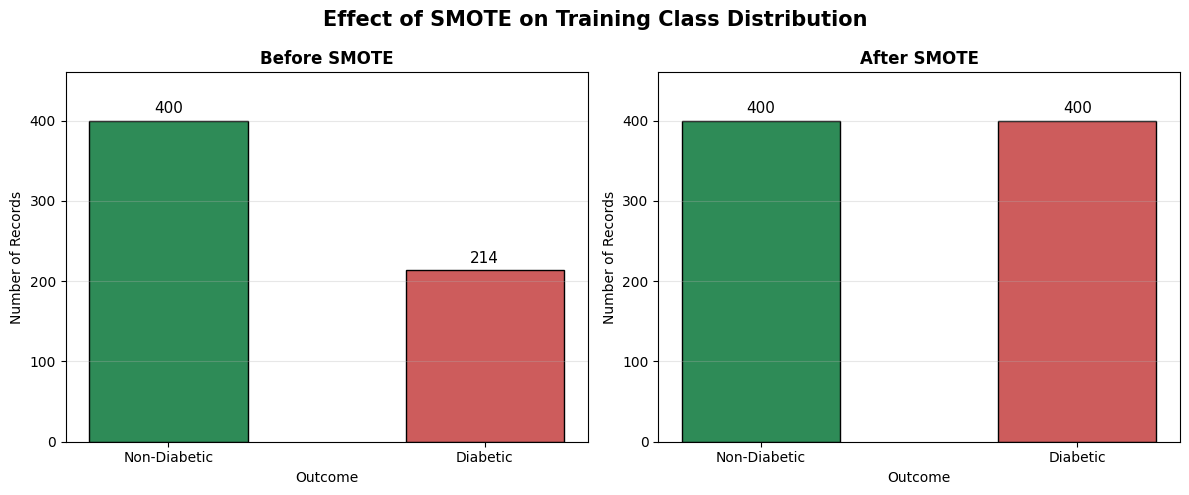

In [ ]:
# Visualize training class distribution before and after SMOTE

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

labels = ['Non-Diabetic', 'Diabetic']
class_colors = ['seagreen', 'indianred']

bars1 = axes[0].bar(
    labels,
    before_smote.values,
    color=class_colors,
    edgecolor='black',
    width=0.5
)

axes[0].bar_label(bars1, padding=3, fontsize=11)
axes[0].set_title('Before SMOTE', fontweight='bold')
axes[0].set_xlabel('Outcome')
axes[0].set_ylabel('Number of Records')
axes[0].set_ylim(0, 460)
axes[0].grid(axis='y', alpha=0.3)

bars2 = axes[1].bar(
    labels,
    after_smote.values,
    color=class_colors,
    edgecolor='black',
    width=0.5
)

axes[1].bar_label(bars2, padding=3, fontsize=11)
axes[1].set_title('After SMOTE', fontweight='bold')
axes[1].set_xlabel('Outcome')
axes[1].set_ylabel('Number of Records')
axes[1].set_ylim(0, 460)
axes[1].grid(axis='y', alpha=0.3)

fig.suptitle(
    'Effect of SMOTE on Training Class Distribution',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [ ]:
# Create Version 3 KNN pipeline with SMOTE

knn_pipeline_v3 = ImbPipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('knn', KNeighborsClassifier())
])

print("Version 3 SMOTE-KNN pipeline created successfully!")

print("\nPipeline Configuration:")

for step_name, step in knn_pipeline_v3.steps:
    print(f"{step_name}: {type(step).__name__}")

Version 3 SMOTE-KNN pipeline created successfully!

Pipeline Configuration:
imputer: SimpleImputer
scaler: StandardScaler
smote: SMOTE
knn: KNeighborsClassifier


In [ ]:
# Define the Version 3 hyperparameter search space

param_grid_v3 = {
    'smote__sampling_strategy': [0.6, 0.8, 0.9, 1.0],
    'smote__k_neighbors': [3, 5],
    'knn__n_neighbors': list(range(1, 42, 2)),
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': [
        'euclidean',
        'manhattan',
        'chebyshev'
    ]
}

total_combinations_v3 = len(
    list(ParameterGrid(param_grid_v3))
)

total_fits_v3 = (
    total_combinations_v3 * comparison_cv.n_splits
)

print("Version 3 Hyperparameter Search Space:\n")

print("SMOTE Sampling Ratios:",
      param_grid_v3['smote__sampling_strategy'])

print("SMOTE Neighbors:",
      param_grid_v3['smote__k_neighbors'])

print("KNN K Values:",
      param_grid_v3['knn__n_neighbors'])

print("KNN Neighbor Weights:",
      param_grid_v3['knn__weights'])

print("KNN Distance Metrics:",
      param_grid_v3['knn__metric'])

print("\nTotal Hyperparameter Combinations:",
      total_combinations_v3)

print("Number of Cross-Validation Folds:",
      comparison_cv.n_splits)

print("Total Cross-Validation Model Fits:",
      total_fits_v3)

Version 3 Hyperparameter Search Space:

SMOTE Sampling Ratios: [0.6, 0.8, 0.9, 1.0]
SMOTE Neighbors: [3, 5]
KNN K Values: [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25, 27, 29, 31, 33, 35, 37, 39, 41]
KNN Neighbor Weights: ['uniform', 'distance']
KNN Distance Metrics: ['euclidean', 'manhattan', 'chebyshev']

Total Hyperparameter Combinations: 1008
Number of Cross-Validation Folds: 5
Total Cross-Validation Model Fits: 5040


In [ ]:
# Perform Version 3 SMOTE-KNN hyperparameter optimization

grid_search_v3 = GridSearchCV(
    estimator=knn_pipeline_v3,
    param_grid=param_grid_v3,
    cv=comparison_cv,
    scoring=scoring_metrics,
    refit='f1',
    n_jobs=-1,
    return_train_score=False,
    error_score='raise'
)

print("Starting Version 3 SMOTE-KNN optimization...")
print("Please wait while the models are evaluated.\n")

grid_search_v3.fit(X_train, y_train)

optimized_model_v3 = grid_search_v3.best_estimator_

best_params_v3 = grid_search_v3.best_params_

best_k_v3 = best_params_v3['knn__n_neighbors']
best_weights_v3 = best_params_v3['knn__weights']
best_metric_v3 = best_params_v3['knn__metric']

best_sampling_v3 = best_params_v3[
    'smote__sampling_strategy'
]

best_smote_neighbors_v3 = best_params_v3[
    'smote__k_neighbors'
]

print("Version 3 optimization completed successfully!")

print("\nOptimal Hyperparameter Configuration:\n")

print("Optimal SMOTE Sampling Ratio:", best_sampling_v3)
print("Optimal SMOTE Neighbors:", best_smote_neighbors_v3)
print("Optimal K Value:", best_k_v3)
print("Optimal Neighbor Weights:", best_weights_v3)
print("Optimal Distance Metric:", best_metric_v3)

print(
    f"\nBest Cross-Validation F1-Score: "
    f"{grid_search_v3.best_score_ * 100:.2f}%"
)

Starting Version 3 SMOTE-KNN optimization...
Please wait while the models are evaluated.

Version 3 optimization completed successfully!

Optimal Hyperparameter Configuration:

Optimal SMOTE Sampling Ratio: 0.9
Optimal SMOTE Neighbors: 3
Optimal K Value: 21
Optimal Neighbor Weights: distance
Optimal Distance Metric: euclidean

Best Cross-Validation F1-Score: 70.43%


In [ ]:
# Extract cross-validation performance of Version 3

best_index_v3 = grid_search_v3.best_index_

v3_cv_summary = {}

print("Version 3 - SMOTE-KNN Cross-Validation Performance:\n")

for metric in scoring_metrics:

    mean_score = grid_search_v3.cv_results_[
        f'mean_test_{metric}'
    ][best_index_v3]

    std_score = grid_search_v3.cv_results_[
        f'std_test_{metric}'
    ][best_index_v3]

    v3_cv_summary[metric] = mean_score

    print(
        f"{metric.upper():10s}: "
        f"{mean_score * 100:.2f}% "
        f"(+/- {std_score * 100:.2f} percentage points)"
    )

Version 3 - SMOTE-KNN Cross-Validation Performance:

ACCURACY  : 76.21% (+/- 4.37 percentage points)
PRECISION : 63.17% (+/- 6.96 percentage points)
RECALL    : 80.39% (+/- 2.70 percentage points)
F1        : 70.43% (+/- 3.61 percentage points)
ROC_AUC   : 83.59% (+/- 3.56 percentage points)


In [ ]:
# Display the top 10 Version 3 hyperparameter combinations

v3_search_results = pd.DataFrame(
    grid_search_v3.cv_results_
)

top_10_v3 = v3_search_results[[
    'param_smote__sampling_strategy',
    'param_smote__k_neighbors',
    'param_knn__n_neighbors',
    'param_knn__weights',
    'param_knn__metric',
    'mean_test_accuracy',
    'mean_test_precision',
    'mean_test_recall',
    'mean_test_f1',
    'mean_test_roc_auc',
    'rank_test_f1'
]].copy()

top_10_v3.columns = [
    'SMOTE Ratio',
    'SMOTE Neighbors',
    'K',
    'Weights',
    'Distance Metric',
    'Accuracy (%)',
    'Precision (%)',
    'Recall (%)',
    'F1-Score (%)',
    'ROC-AUC',
    'Rank'
]

percentage_columns = [
    'Accuracy (%)',
    'Precision (%)',
    'Recall (%)',
    'F1-Score (%)'
]

top_10_v3[percentage_columns] = (
    top_10_v3[percentage_columns] * 100
)

top_10_v3 = (
    top_10_v3
    .sort_values('Rank')
    .head(10)
    .reset_index(drop=True)
)

print("Top 10 SMOTE-KNN Hyperparameter Combinations:\n")

display(top_10_v3.round(4))

Top 10 SMOTE-KNN Hyperparameter Combinations:



,SMOTE Ratio,SMOTE Neighbors,K,Weights,Distance Metric,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC,Rank
0,0.9,3,21,distance,euclidean,76.2135,63.1711,80.3876,70.4312,0.8359,1
1,1.0,3,39,distance,euclidean,75.2366,61.0050,83.6545,70.3278,0.8357,2
2,0.9,3,23,uniform,euclidean,75.8883,62.8648,79.9225,70.0185,0.8352,3
3,0.9,3,23,distance,euclidean,75.8883,62.8648,79.9225,70.0185,0.8357,3
4,1.0,3,33,distance,euclidean,75.0740,61.0902,82.7243,69.9547,0.8346,5
5,1.0,5,35,distance,euclidean,74.9087,60.6272,83.1783,69.9093,0.8338,6
6,1.0,5,27,distance,euclidean,74.5795,60.5701,83.1783,69.8252,0.8357,7
7,1.0,3,23,distance,euclidean,74.5835,60.3313,83.6434,69.8121,0.8292,8
8,0.9,3,19,distance,euclidean,75.8870,62.9756,78.9812,69.7451,0.8321,9
9,1.0,3,35,distance,euclidean,74.9100,61.0456,82.2591,69.7287,0.8352,10


In [ ]:
# Identify the best configuration for each SMOTE sampling ratio

best_ratio_indices = (
    v3_search_results
    .groupby('param_smote__sampling_strategy')['mean_test_f1']
    .idxmax()
)

smote_ratio_summary = v3_search_results.loc[
    best_ratio_indices,
    [
        'param_smote__sampling_strategy',
        'mean_test_accuracy',
        'mean_test_precision',
        'mean_test_recall',
        'mean_test_f1',
        'mean_test_roc_auc'
    ]
].copy()

smote_ratio_summary.columns = [
    'SMOTE Ratio',
    'Accuracy (%)',
    'Precision (%)',
    'Recall (%)',
    'F1-Score (%)',
    'ROC-AUC'
]

smote_ratio_summary[percentage_columns] = (
    smote_ratio_summary[percentage_columns] * 100
)

smote_ratio_summary = (
    smote_ratio_summary
    .sort_values('SMOTE Ratio')
    .reset_index(drop=True)
)

print("Best Model Performance for Each SMOTE Sampling Ratio:\n")

display(smote_ratio_summary.round(4))

Best Model Performance for Each SMOTE Sampling Ratio:



,SMOTE Ratio,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC
0,0.6,77.3584,68.9952,65.4374,66.9155,0.8280
1,0.8,75.8936,63.5802,74.3300,68.3054,0.8342
2,0.9,76.2135,63.1711,80.3876,70.4312,0.8359
3,1.0,75.2366,61.0050,83.6545,70.3278,0.8357


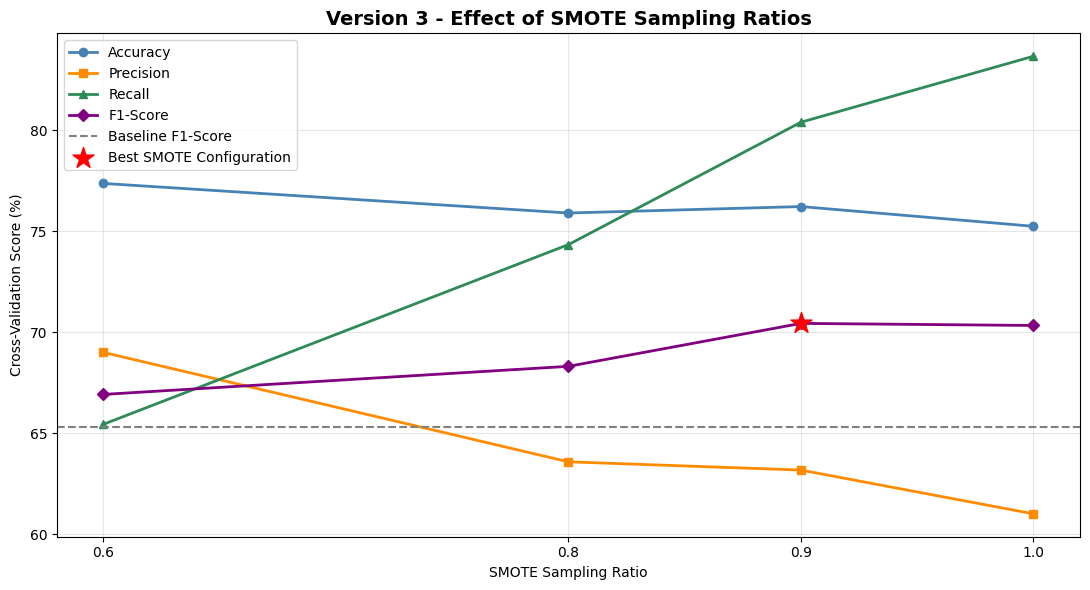

In [ ]:
# Visualize performance across different SMOTE sampling ratios

ratios = smote_ratio_summary['SMOTE Ratio'].astype(float)

plt.figure(figsize=(11, 6))

plt.plot(
    ratios,
    smote_ratio_summary['Accuracy (%)'],
    marker='o',
    color='steelblue',
    linewidth=2,
    label='Accuracy'
)

plt.plot(
    ratios,
    smote_ratio_summary['Precision (%)'],
    marker='s',
    color='darkorange',
    linewidth=2,
    label='Precision'
)

plt.plot(
    ratios,
    smote_ratio_summary['Recall (%)'],
    marker='^',
    color='seagreen',
    linewidth=2,
    label='Recall'
)

plt.plot(
    ratios,
    smote_ratio_summary['F1-Score (%)'],
    marker='D',
    color='purple',
    linewidth=2,
    label='F1-Score'
)

plt.axhline(
    y=baseline_cv_summary['f1'] * 100,
    color='gray',
    linestyle='--',
    label='Baseline F1-Score'
)

plt.scatter(
    best_sampling_v3,
    grid_search_v3.best_score_ * 100,
    color='red',
    marker='*',
    s=250,
    zorder=5,
    label='Best SMOTE Configuration'
)

plt.title(
    'Version 3 - Effect of SMOTE Sampling Ratios',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('SMOTE Sampling Ratio')
plt.ylabel('Cross-Validation Score (%)')

plt.xticks([0.6, 0.8, 0.9, 1.0])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Add Version 3 results to the model comparison table

v3_result = {
    'Model': 'Version 3 - SMOTE-KNN',
    'Optimal K': best_k_v3,
    'Weights': best_weights_v3,
    'Distance Metric': best_metric_v3,
    'Imputation': 'Median',
    'Scaler': 'StandardScaler',
    'SMOTE': 'Yes',
    'SMOTE Ratio': best_sampling_v3,
    'SMOTE Neighbors': best_smote_neighbors_v3,
    'Selection Metric': 'F1-Score',
    'CV Accuracy (%)': v3_cv_summary['accuracy'] * 100,
    'CV Precision (%)': v3_cv_summary['precision'] * 100,
    'CV Recall (%)': v3_cv_summary['recall'] * 100,
    'CV F1-Score (%)': v3_cv_summary['f1'] * 100,
    'CV ROC-AUC': v3_cv_summary['roc_auc']
}

# Prevent duplicate entries if the cell is executed again

model_results = [
    result for result in model_results
    if result['Model'] != v3_result['Model']
]

model_results.append(v3_result)

comparison_df = pd.DataFrame(model_results)

# Display non-applicable SMOTE parameters clearly

comparison_display = comparison_df.copy()

for column in ['SMOTE Ratio', 'SMOTE Neighbors']:

    comparison_display[column] = (
        comparison_display[column]
        .astype(object)
        .where(comparison_display[column].notna(), 'N/A')
    )

print("Updated Model Performance Comparison Table:\n")

display(comparison_display.round(4))

print("\nVersion 3 successfully added to the comparison table!")

Updated Model Performance Comparison Table:



,Model,Optimal K,Weights,Distance Metric,Imputation,Scaler,SMOTE,Selection Metric,CV Accuracy (%),CV Precision (%),CV Recall (%),CV F1-Score (%),CV ROC-AUC,SMOTE Ratio,SMOTE Neighbors
0,Version 1 - Baseline KNN,13,uniform,euclidean,Median,StandardScaler,No,Accuracy,77.5237,72.0985,60.3212,65.3198,0.8282,N/A,N/A
1,Version 2 - Hyperparameter Optimized KNN,13,uniform,euclidean,Median,StandardScaler,No,F1-Score,77.5237,72.0985,60.3212,65.3198,0.8282,N/A,N/A
2,Version 3 - SMOTE-KNN,21,distance,euclidean,Median,StandardScaler,Yes,F1-Score,76.2135,63.1711,80.3876,70.4312,0.8359,0.9,3.0



Version 3 successfully added to the comparison table!


In [ ]:
# Calculate performance changes from Version 1 to Version 3

v3_improvement = []

for metric, label in metric_labels.items():

    baseline_value = baseline_cv_summary[metric] * 100
    optimized_value = v3_cv_summary[metric] * 100

    difference = optimized_value - baseline_value

    if np.isclose(difference, 0):
        difference = 0.0
        status = 'No Change'

    elif difference > 0:
        status = 'Improved'

    else:
        status = 'Decreased'

    v3_improvement.append({
        'Metric': label,
        'Version 1 (%)': baseline_value,
        'Version 3 (%)': optimized_value,
        'Change (pp)': difference,
        'Status': status
    })

v3_improvement_df = pd.DataFrame(v3_improvement)

print("Version 1 vs Version 3 - Performance Changes:\n")

display(v3_improvement_df.round(2))

f1_improvement_v3 = (
    v3_cv_summary['f1'] - baseline_cv_summary['f1']
) * 100

recall_improvement_v3 = (
    v3_cv_summary['recall'] - baseline_cv_summary['recall']
) * 100

print(
    f"\nF1-Score Change: "
    f"{f1_improvement_v3:+.2f} percentage points"
)

print(
    f"Recall Change: "
    f"{recall_improvement_v3:+.2f} percentage points"
)

Version 1 vs Version 3 - Performance Changes:



,Metric,Version 1 (%),Version 3 (%),Change (pp),Status
0,Accuracy,77.52,76.21,-1.31,Decreased
1,Precision,72.10,63.17,-8.93,Decreased
2,Recall,60.32,80.39,20.07,Improved
3,F1-Score,65.32,70.43,5.11,Improved
4,ROC-AUC,82.82,83.59,0.77,Improved



F1-Score Change: +5.11 percentage points
Recall Change: +20.07 percentage points


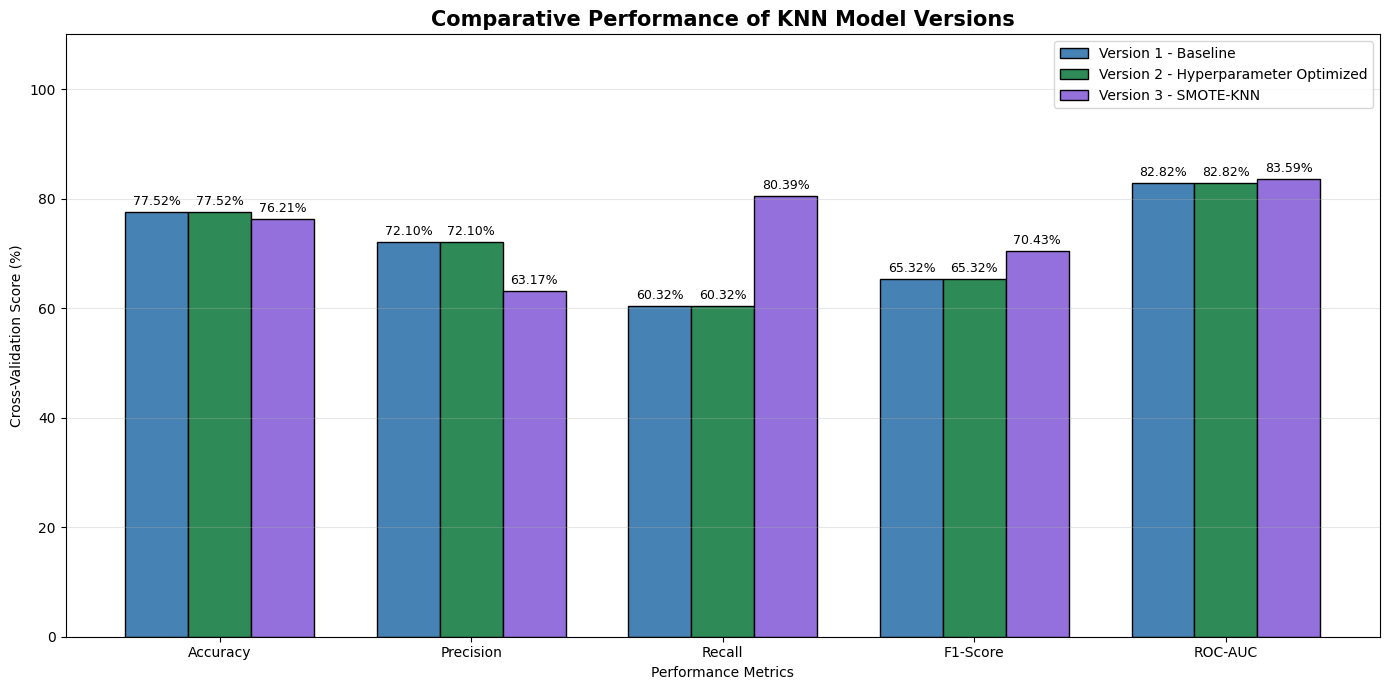

In [ ]:
# Compare Versions 1, 2 and 3 visually

metric_names = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score',
    'ROC-AUC'
]

metric_keys = [
    'accuracy',
    'precision',
    'recall',
    'f1',
    'roc_auc'
]

baseline_values = [
    baseline_cv_summary[metric] * 100
    for metric in metric_keys
]

v2_values = [
    v2_cv_summary[metric] * 100
    for metric in metric_keys
]

v3_values = [
    v3_cv_summary[metric] * 100
    for metric in metric_keys
]

x = np.arange(len(metric_names))
width = 0.25

plt.figure(figsize=(14, 7))

bars1 = plt.bar(
    x - width,
    baseline_values,
    width,
    label='Version 1 - Baseline',
    color='steelblue',
    edgecolor='black'
)

bars2 = plt.bar(
    x,
    v2_values,
    width,
    label='Version 2 - Hyperparameter Optimized',
    color='seagreen',
    edgecolor='black'
)

bars3 = plt.bar(
    x + width,
    v3_values,
    width,
    label='Version 3 - SMOTE-KNN',
    color='mediumpurple',
    edgecolor='black'
)

plt.bar_label(bars1, fmt='%.2f%%', padding=3, fontsize=9)
plt.bar_label(bars2, fmt='%.2f%%', padding=3, fontsize=9)
plt.bar_label(bars3, fmt='%.2f%%', padding=3, fontsize=9)

plt.title(
    'Comparative Performance of KNN Model Versions',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Performance Metrics')
plt.ylabel('Cross-Validation Score (%)')
plt.xticks(x, metric_names)
plt.ylim(0, 110)
plt.legend(loc='upper right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Summarize Version 3 experimental findings

print("=" * 60)
print("        VERSION 3 - SMOTE-KNN EXPERIMENT SUMMARY")
print("=" * 60)

print("\nTotal Configurations Investigated:",
      total_combinations_v3)

print("Total Cross-Validation Fits:",
      total_fits_v3)

print("\nBest SMOTE Sampling Ratio:", best_sampling_v3)
print("Best SMOTE Neighbors:", best_smote_neighbors_v3)
print("Optimal K Value:", best_k_v3)
print("Optimal Neighbor Weights:", best_weights_v3)
print("Optimal Distance Metric:", best_metric_v3)

print("\nF1-Score Comparison:")

print(
    f"Baseline F1-Score: "
    f"{baseline_cv_summary['f1'] * 100:.2f}%"
)

print(
    f"Version 3 F1-Score: "
    f"{v3_cv_summary['f1'] * 100:.2f}%"
)

print(
    f"Change: "
    f"{f1_improvement_v3:+.2f} percentage points"
)

print("\nRecall Comparison:")

print(
    f"Baseline Recall: "
    f"{baseline_cv_summary['recall'] * 100:.2f}%"
)

print(
    f"Version 3 Recall: "
    f"{v3_cv_summary['recall'] * 100:.2f}%"
)

print(
    f"Change: "
    f"{recall_improvement_v3:+.2f} percentage points"
)

print("\nExperimental Conclusion:")

if np.isclose(f1_improvement_v3, 0):

    print("SMOTE produced no measurable change in CV F1-score.")

elif f1_improvement_v3 > 0:

    print("SMOTE-KNN improved the cross-validation F1-score.")

else:

    print("SMOTE-KNN decreased the cross-validation F1-score.")

if np.isclose(recall_improvement_v3, 0):

    print("Minority-class recall remained unchanged.")

elif recall_improvement_v3 > 0:

    print("Minority-class recall improved.")

else:

    print("Minority-class recall decreased.")

print("\nFinal model selection will be performed after Version 4.")

print("The testing dataset was not used for Version 3 optimization.")

print("=" * 60)

        VERSION 3 - SMOTE-KNN EXPERIMENT SUMMARY

Total Configurations Investigated: 1008
Total Cross-Validation Fits: 5040

Best SMOTE Sampling Ratio: 0.9
Best SMOTE Neighbors: 3
Optimal K Value: 21
Optimal Neighbor Weights: distance
Optimal Distance Metric: euclidean

F1-Score Comparison:
Baseline F1-Score: 65.32%
Version 3 F1-Score: 70.43%
Change: +5.11 percentage points

Recall Comparison:
Baseline Recall: 60.32%
Version 3 Recall: 80.39%
Change: +20.07 percentage points

Experimental Conclusion:
SMOTE-KNN improved the cross-validation F1-score.
Minority-class recall improved.

Final model selection will be performed after Version 4.
The testing dataset was not used for Version 3 optimization.


**VERSION 3: EXPERIMENTAL OBSERVATIONS AND ANALYSIS**

**Class Balancing and Hyperparameter Optimization**

1. The original training dataset contained 400 non-diabetic records and 214 diabetic records, resulting in a minority-to-majority ratio of 0.535.

2. SMOTE was introduced to improve minority-class representation by generating synthetic training observations.

3. The full-balancing demonstration generated 186 synthetic diabetic records, increasing the total number of training records from 614 to 800.

4. Four SMOTE sampling ratios (0.6, 0.8, 0.9 and 1.0) and two SMOTE neighbor configurations (3 and 5) were investigated alongside the KNN hyperparameters.

5. A total of 1,008 hyperparameter combinations and 5,040 cross-validation model fits were evaluated using five-fold stratified cross-validation.

6. The optimal hyperparameter configuration was found to be:
   - SMOTE Sampling Ratio: 0.9
   - SMOTE Neighbors: 3
   - Number of Neighbors (K): 21
   - Neighbor Weights: Distance
   - Distance Metric: Euclidean

7. The selected SMOTE sampling ratio of 0.9 generates 146 synthetic minority-class records when applied to the complete training dataset, resulting in 400 non-diabetic and 360 diabetic records.

**Performance Analysis**

8. The optimized SMOTE-KNN model achieved the following cross-validation performance:
   - Accuracy: 76.21%
   - Precision: 63.17%
   - Recall: 80.39%
   - F1-Score: 70.43%
   - ROC-AUC: 0.8359

9. Compared with the baseline model, recall improved by 20.07 percentage points, while F1-score improved by 5.11 percentage points.

10. ROC-AUC increased from 0.8282 to 0.8359, indicating a modest improvement in estimated class discrimination.

11. Accuracy decreased by 1.31 percentage points, while precision decreased by 8.93 percentage points. These reductions demonstrate the trade-off associated with improving minority-class recall.

**Effect of SMOTE Sampling Ratios**

12. All four investigated sampling ratios produced selected configurations with higher cross-validation F1-scores than the baseline model.

13. Complete class balancing with a sampling ratio of 1.0 achieved a recall of 83.65%, which was the highest recall among the four configurations selected by F1-score for each sampling ratio.

14. Partial class balancing with a sampling ratio of 0.9 achieved the highest cross-validation F1-score of 70.43%.

15. The results suggest that complete class balancing is not necessarily required to achieve the best F1-score within the investigated search space.

**Data Leakage Prevention**

16. SMOTE was integrated into the imbalanced-learn pipeline after missing-value imputation and feature scaling.

17. Synthetic observations were generated only within the training portion of each cross-validation fold.

18. The validation folds and testing dataset retained their original class distributions.

**Conclusion of Version 3**

The introduction of SMOTE combined with hyperparameter optimization improved the model's cross-validation F1-score and minority-class recall compared with Versions 1 and 2.

Although accuracy and precision decreased, the substantial improvement in recall and the increase in F1-score support the effectiveness of this optimization strategy within the development evaluation framework.

Version 3 currently achieves the highest cross-validation F1-score among the three investigated model versions.

Further experiments involving alternative imputation and feature scaling techniques will be conducted in Version 4 to investigate whether additional improvements are possible.

The testing dataset was not used during Version 3 optimization. Final model selection and testing evaluation will be conducted after completing the remaining optimization experiments.

**VERSION 4: ADVANCED PREPROCESSING-OPTIMIZED KNN MODEL**

The fourth version of the KNN model investigates alternative
missing-value imputation and feature scaling techniques.

The following preprocessing methods are evaluated:

Missing-Value Imputation:
- Median Imputation
- KNN Imputation

Feature Scaling:
- StandardScaler
- MinMaxScaler
- RobustScaler

Class Balancing:
- Without SMOTE
- With SMOTE

A two-stage optimization strategy is implemented.

In the first stage, different preprocessing configurations
are compared using previously optimized model parameters.

In the second stage, the three strongest preprocessing
configurations are selected for further hyperparameter
optimization.

The primary model selection metric remains F1-score.

All preprocessing and resampling operations are performed
within the model pipeline to prevent data leakage.

In [ ]:
# Import additional preprocessing libraries

from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler, RobustScaler
from sklearn.base import clone

print("Advanced preprocessing libraries imported successfully!")

Advanced preprocessing libraries imported successfully!


In [ ]:
# Define alternative preprocessing configurations

imputation_options = {
    'Median': SimpleImputer(strategy='median'),
    'KNN': KNNImputer(n_neighbors=5)
}

scaling_options = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler()
}

balancing_options = [
    'Without SMOTE',
    'With SMOTE'
]

total_preprocessing_combinations = (
    len(imputation_options) *
    len(scaling_options) *
    len(balancing_options)
)

print("Version 4 Preprocessing Search Space:\n")

print("Imputation Methods:")

for method in imputation_options:
    print("-", method)

print("\nFeature Scaling Methods:")

for method in scaling_options:
    print("-", method)

print("\nClass Balancing Methods:")

for method in balancing_options:
    print("-", method)

print("\nTotal Preprocessing Configurations:",
      total_preprocessing_combinations)

print("Total Stage A Cross-Validation Fits:",
      total_preprocessing_combinations *
      comparison_cv.n_splits)

Version 4 Preprocessing Search Space:

Imputation Methods:
- Median
- KNN

Feature Scaling Methods:
- StandardScaler
- MinMaxScaler
- RobustScaler

Class Balancing Methods:
- Without SMOTE
- With SMOTE

Total Preprocessing Configurations: 12
Total Stage A Cross-Validation Fits: 60


In [ ]:
# Create a flexible pipeline for preprocessing experiments

def create_v4_pipeline(
    imputation_method,
    scaling_method,
    use_smote
):

    steps = []

    # Scale before KNN imputation because it uses distances

    if imputation_method == 'KNN':

        steps.append((
            'scaler',
            clone(scaling_options[scaling_method])
        ))

        steps.append((
            'imputer',
            clone(imputation_options[imputation_method])
        ))

    else:

        steps.append((
            'imputer',
            clone(imputation_options[imputation_method])
        ))

        steps.append((
            'scaler',
            clone(scaling_options[scaling_method])
        ))

    # Use the previously optimized model parameters

    if use_smote:

        steps.append((
            'smote',
            SMOTE(
                sampling_strategy=best_sampling_v3,
                k_neighbors=best_smote_neighbors_v3,
                random_state=42
            )
        ))

        steps.append((
            'knn',
            KNeighborsClassifier(
                n_neighbors=best_k_v3,
                weights=best_weights_v3,
                metric=best_metric_v3
            )
        ))

    else:

        steps.append((
            'knn',
            KNeighborsClassifier(
                n_neighbors=best_k_v2,
                weights=best_weights_v2,
                metric=best_metric_v2
            )
        ))

    return ImbPipeline(steps)


print("Flexible Version 4 pipeline function created successfully!")

Flexible Version 4 pipeline function created successfully!


In [ ]:
# Stage A: Compare all preprocessing configurations

preprocessing_results_v4 = []

print("Starting Stage A - Preprocessing Comparison...\n")

configuration_number = 0

for imputation_method in imputation_options:

    for scaling_method in scaling_options:

        for balancing_method in balancing_options:

            configuration_number += 1

            use_smote = (
                balancing_method == 'With SMOTE'
            )

            pipeline = create_v4_pipeline(
                imputation_method,
                scaling_method,
                use_smote
            )

            cv_results = cross_validate(
                estimator=pipeline,
                X=X_train,
                y=y_train,
                cv=comparison_cv,
                scoring=scoring_metrics,
                n_jobs=-1,
                error_score='raise'
            )

            result = {
                'Imputation': imputation_method,
                'Scaler': scaling_method,
                'SMOTE': 'Yes' if use_smote else 'No',
                'CV Accuracy (%)':
                    cv_results['test_accuracy'].mean() * 100,
                'CV Precision (%)':
                    cv_results['test_precision'].mean() * 100,
                'CV Recall (%)':
                    cv_results['test_recall'].mean() * 100,
                'CV F1-Score (%)':
                    cv_results['test_f1'].mean() * 100,
                'CV ROC-AUC':
                    cv_results['test_roc_auc'].mean()
            }

            preprocessing_results_v4.append(result)

            print(
                f"[{configuration_number}/"
                f"{total_preprocessing_combinations}] "
                f"{imputation_method} | "
                f"{scaling_method} | "
                f"{balancing_method}"
            )

            print(
                f"CV F1-Score: "
                f"{result['CV F1-Score (%)']:.2f}%\n"
            )

print("Stage A completed successfully!")

Starting Stage A - Preprocessing Comparison...

[1/12] Median | StandardScaler | Without SMOTE
CV F1-Score: 65.32%

[2/12] Median | StandardScaler | With SMOTE
CV F1-Score: 70.43%

[3/12] Median | MinMaxScaler | Without SMOTE
CV F1-Score: 61.22%

[4/12] Median | MinMaxScaler | With SMOTE
CV F1-Score: 69.29%

[5/12] Median | RobustScaler | Without SMOTE
CV F1-Score: 56.78%

[6/12] Median | RobustScaler | With SMOTE
CV F1-Score: 65.40%

[7/12] KNN | StandardScaler | Without SMOTE
CV F1-Score: 63.53%

[8/12] KNN | StandardScaler | With SMOTE
CV F1-Score: 66.54%

[9/12] KNN | MinMaxScaler | Without SMOTE
CV F1-Score: 60.54%

[10/12] KNN | MinMaxScaler | With SMOTE
CV F1-Score: 69.14%

[11/12] KNN | RobustScaler | Without SMOTE
CV F1-Score: 63.39%

[12/12] KNN | RobustScaler | With SMOTE
CV F1-Score: 66.62%

Stage A completed successfully!


In [ ]:
# Rank preprocessing configurations by F1-score

preprocessing_df_v4 = pd.DataFrame(
    preprocessing_results_v4
)

preprocessing_df_v4 = (
    preprocessing_df_v4
    .sort_values(
        'CV F1-Score (%)',
        ascending=False
    )
    .reset_index(drop=True)
)

preprocessing_df_v4.insert(
    0,
    'Rank',
    range(1, len(preprocessing_df_v4) + 1)
)

print("Stage A - Preprocessing Performance Comparison:\n")

display(preprocessing_df_v4.round(4))

print("\nBest Preprocessing Configuration in Stage A:\n")

best_preprocessing_v4 = preprocessing_df_v4.iloc[0]

print("Imputation:", best_preprocessing_v4['Imputation'])
print("Scaler:", best_preprocessing_v4['Scaler'])
print("SMOTE:", best_preprocessing_v4['SMOTE'])

print(
    f"CV F1-Score: "
    f"{best_preprocessing_v4['CV F1-Score (%)']:.2f}%"
)

Stage A - Preprocessing Performance Comparison:



,Rank,Imputation,Scaler,SMOTE,CV Accuracy (%),CV Precision (%),CV Recall (%),CV F1-Score (%),CV ROC-AUC
0,1,Median,StandardScaler,Yes,76.2135,63.1711,80.3876,70.4312,0.8359
1,2,Median,MinMaxScaler,Yes,75.7270,62.8097,78.0620,69.2919,0.8340
2,3,KNN,MinMaxScaler,Yes,75.3978,62.2140,78.5271,69.1407,0.8312
3,4,KNN,RobustScaler,Yes,73.1254,59.2943,76.6667,66.6160,0.8234
4,5,KNN,StandardScaler,Yes,73.6132,60.0112,75.2713,66.5366,0.8308
5,6,Median,RobustScaler,Yes,71.8179,57.4300,76.6667,65.3995,0.7746
6,7,Median,StandardScaler,No,77.5237,72.0985,60.3212,65.3198,0.8282
7,8,KNN,StandardScaler,No,76.8719,71.4221,57.9845,63.5278,0.8281
8,9,KNN,RobustScaler,No,76.0589,69.3321,59.3909,63.3938,0.8226
9,10,Median,MinMaxScaler,No,75.2419,68.4810,56.1130,61.2211,0.8238



Best Preprocessing Configuration in Stage A:

Imputation: Median
Scaler: StandardScaler
SMOTE: Yes
CV F1-Score: 70.43%


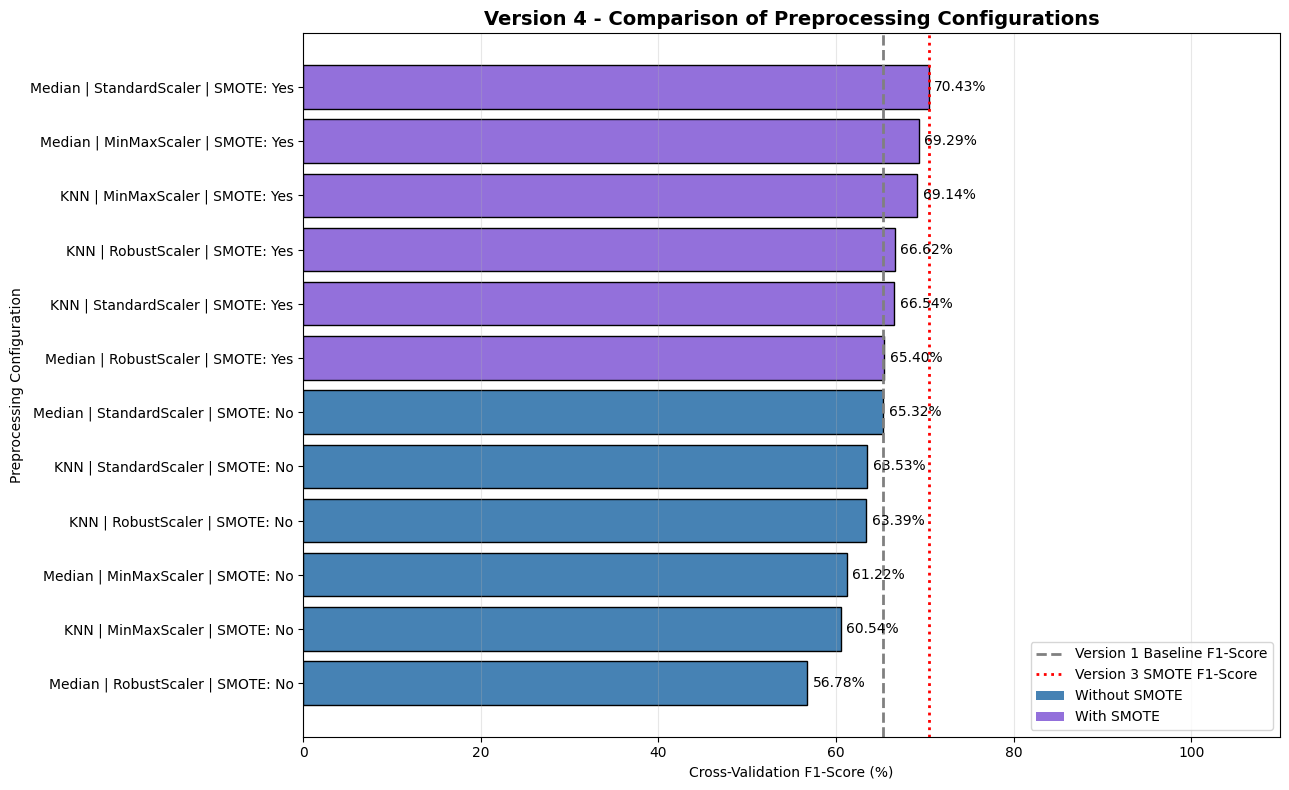

In [ ]:
# Visualize all 12 preprocessing configurations

plot_df_v4 = preprocessing_df_v4.copy()

plot_df_v4['Configuration'] = (
    plot_df_v4['Imputation'] + ' | ' +
    plot_df_v4['Scaler'] + ' | SMOTE: ' +
    plot_df_v4['SMOTE']
)

plot_df_v4 = plot_df_v4.sort_values(
    'CV F1-Score (%)',
    ascending=True
)

bar_colors = [
    'mediumpurple' if value == 'Yes'
    else 'steelblue'
    for value in plot_df_v4['SMOTE']
]

plt.figure(figsize=(13, 8))

bars = plt.barh(
    plot_df_v4['Configuration'],
    plot_df_v4['CV F1-Score (%)'],
    color=bar_colors,
    edgecolor='black'
)

plt.bar_label(
    bars,
    fmt='%.2f%%',
    padding=4,
    fontsize=10
)

plt.axvline(
    baseline_cv_summary['f1'] * 100,
    color='gray',
    linestyle='--',
    linewidth=2,
    label='Version 1 Baseline F1-Score'
)

plt.axvline(
    v3_cv_summary['f1'] * 100,
    color='red',
    linestyle=':',
    linewidth=2,
    label='Version 3 SMOTE F1-Score'
)

from matplotlib.patches import Patch

handles, labels = plt.gca().get_legend_handles_labels()

handles.extend([
    Patch(
        facecolor='steelblue',
        label='Without SMOTE'
    ),
    Patch(
        facecolor='mediumpurple',
        label='With SMOTE'
    )
])

plt.title(
    'Version 4 - Comparison of Preprocessing Configurations',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Cross-Validation F1-Score (%)')
plt.ylabel('Preprocessing Configuration')

plt.xlim(0, 110)
plt.legend(handles=handles, loc='lower right')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Select the three strongest preprocessing configurations

top_preprocessing_v4 = (
    preprocessing_df_v4
    .head(3)
    .copy()
    .reset_index(drop=True)
)

print("Top 3 Preprocessing Configurations for Stage B:\n")

display(top_preprocessing_v4.round(4))

print("\nSelected Configurations:\n")

for index, row in top_preprocessing_v4.iterrows():

    print(f"Configuration {index + 1}:")

    print("Imputation:", row['Imputation'])
    print("Scaler:", row['Scaler'])
    print("SMOTE:", row['SMOTE'])

    print(
        f"CV F1-Score: "
        f"{row['CV F1-Score (%)']:.2f}%\n"
    )

print("Stage B candidate configurations selected successfully!")

Top 3 Preprocessing Configurations for Stage B:



,Rank,Imputation,Scaler,SMOTE,CV Accuracy (%),CV Precision (%),CV Recall (%),CV F1-Score (%),CV ROC-AUC
0,1,Median,StandardScaler,Yes,76.2135,63.1711,80.3876,70.4312,0.8359
1,2,Median,MinMaxScaler,Yes,75.7270,62.8097,78.0620,69.2919,0.8340
2,3,KNN,MinMaxScaler,Yes,75.3978,62.2140,78.5271,69.1407,0.8312



Selected Configurations:

Configuration 1:
Imputation: Median
Scaler: StandardScaler
SMOTE: Yes
CV F1-Score: 70.43%

Configuration 2:
Imputation: Median
Scaler: MinMaxScaler
SMOTE: Yes
CV F1-Score: 69.29%

Configuration 3:
Imputation: KNN
Scaler: MinMaxScaler
SMOTE: Yes
CV F1-Score: 69.14%

Stage B candidate configurations selected successfully!


In [ ]:
# Define Stage B hyperparameter search spaces

base_param_grid_v4 = {
    'knn__n_neighbors': list(range(1, 42, 2)),
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': [
        'euclidean',
        'manhattan',
        'chebyshev'
    ]
}

def create_param_grid_v4(
    imputation_method,
    use_smote
):

    param_grid = {
        key: list(values)
        for key, values in base_param_grid_v4.items()
    }

    if imputation_method == 'KNN':

        param_grid['imputer__n_neighbors'] = [
            3, 5, 7
        ]

    if use_smote:

        param_grid['smote__sampling_strategy'] = [
            0.8, 0.9, 1.0
        ]

        param_grid['smote__k_neighbors'] = [
            3, 5
        ]

    return param_grid


print("Stage B Hyperparameter Search Configuration:\n")

total_combinations_v4 = 0

for index, row in top_preprocessing_v4.iterrows():

    use_smote = row['SMOTE'] == 'Yes'

    param_grid = create_param_grid_v4(
        row['Imputation'],
        use_smote
    )

    combinations = len(
        list(ParameterGrid(param_grid))
    )

    total_combinations_v4 += combinations

    print(f"Configuration {index + 1}:")

    print("Imputation:", row['Imputation'])
    print("Scaler:", row['Scaler'])
    print("SMOTE:", row['SMOTE'])

    print("Hyperparameter Combinations:",
          combinations)

    print()

total_fits_v4 = (
    total_combinations_v4 *
    comparison_cv.n_splits
)

print("Total Stage B Hyperparameter Combinations:",
      total_combinations_v4)

print("Total Stage B Cross-Validation Fits:",
      total_fits_v4)

Stage B Hyperparameter Search Configuration:

Configuration 1:
Imputation: Median
Scaler: StandardScaler
SMOTE: Yes
Hyperparameter Combinations: 756

Configuration 2:
Imputation: Median
Scaler: MinMaxScaler
SMOTE: Yes
Hyperparameter Combinations: 756

Configuration 3:
Imputation: KNN
Scaler: MinMaxScaler
SMOTE: Yes
Hyperparameter Combinations: 2268

Total Stage B Hyperparameter Combinations: 3780
Total Stage B Cross-Validation Fits: 18900


In [ ]:
# Stage B: Optimize the top three preprocessing configurations

v4_grid_searches = []
v4_stage_b_results = []

print("Starting Stage B - Joint Hyperparameter Optimization...\n")

for index, row in top_preprocessing_v4.iterrows():

    imputation_method = row['Imputation']
    scaling_method = row['Scaler']
    use_smote = row['SMOTE'] == 'Yes'

    pipeline = create_v4_pipeline(
        imputation_method,
        scaling_method,
        use_smote
    )

    param_grid = create_param_grid_v4(
        imputation_method,
        use_smote
    )

    print("=" * 60)

    print(f"Optimizing Configuration {index + 1} of 3")

    print("Imputation:", imputation_method)
    print("Scaler:", scaling_method)
    print("SMOTE:", row['SMOTE'])

    print("Please wait...\n")

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=comparison_cv,
        scoring=scoring_metrics,
        refit='f1',
        n_jobs=-1,
        return_train_score=False,
        error_score='raise'
    )

    search.fit(X_train, y_train)

    v4_grid_searches.append(search)

    best_index = search.best_index_

    result = {
        'Configuration': index + 1,
        'Imputation': imputation_method,
        'Scaler': scaling_method,
        'SMOTE': row['SMOTE'],
        'Best Parameters': search.best_params_,
        'CV Accuracy (%)':
            search.cv_results_['mean_test_accuracy'][best_index] * 100,
        'CV Precision (%)':
            search.cv_results_['mean_test_precision'][best_index] * 100,
        'CV Recall (%)':
            search.cv_results_['mean_test_recall'][best_index] * 100,
        'CV F1-Score (%)':
            search.cv_results_['mean_test_f1'][best_index] * 100,
        'CV ROC-AUC':
            search.cv_results_['mean_test_roc_auc'][best_index]
    }

    v4_stage_b_results.append(result)

    print("Best Hyperparameters:")

    for parameter, value in search.best_params_.items():
        print(f"{parameter}: {value}")

    print(
        f"\nBest CV F1-Score: "
        f"{search.best_score_ * 100:.2f}%"
    )

    print("Configuration optimization completed!\n")

print("=" * 60)
print("Stage B optimization completed successfully!")

Starting Stage B - Joint Hyperparameter Optimization...

Optimizing Configuration 1 of 3
Imputation: Median
Scaler: StandardScaler
SMOTE: Yes
Please wait...

Best Hyperparameters:
knn__metric: euclidean
knn__n_neighbors: 21
knn__weights: distance
smote__k_neighbors: 3
smote__sampling_strategy: 0.9

Best CV F1-Score: 70.43%
Configuration optimization completed!

Optimizing Configuration 2 of 3
Imputation: Median
Scaler: MinMaxScaler
SMOTE: Yes
Please wait...

Best Hyperparameters:
knn__metric: euclidean
knn__n_neighbors: 39
knn__weights: distance
smote__k_neighbors: 3
smote__sampling_strategy: 1.0

Best CV F1-Score: 69.78%
Configuration optimization completed!

Optimizing Configuration 3 of 3
Imputation: KNN
Scaler: MinMaxScaler
SMOTE: Yes
Please wait...

Best Hyperparameters:
imputer__n_neighbors: 3
knn__metric: euclidean
knn__n_neighbors: 25
knn__weights: distance
smote__k_neighbors: 5
smote__sampling_strategy: 1.0

Best CV F1-Score: 70.96%
Configuration optimization completed!

Stage

In [ ]:
# Select the strongest Version 4 configuration

stage_b_df_v4 = pd.DataFrame(
    v4_stage_b_results
)

stage_b_df_v4 = (
    stage_b_df_v4
    .sort_values(
        'CV F1-Score (%)',
        ascending=False
    )
    .reset_index(drop=True)
)

print("Stage B - Optimized Configuration Comparison:\n")

display(
    stage_b_df_v4
    .drop(columns=['Best Parameters'])
    .round(4)
)

best_configuration_v4 = stage_b_df_v4.iloc[0]

best_search_index_v4 = (
    int(best_configuration_v4['Configuration']) - 1
)

grid_search_v4 = v4_grid_searches[
    best_search_index_v4
]

optimized_model_v4 = grid_search_v4.best_estimator_

best_params_v4 = grid_search_v4.best_params_

best_imputation_v4 = best_configuration_v4['Imputation']
best_scaler_v4 = best_configuration_v4['Scaler']
best_smote_v4 = best_configuration_v4['SMOTE']

best_k_v4 = best_params_v4['knn__n_neighbors']
best_weights_v4 = best_params_v4['knn__weights']
best_metric_v4 = best_params_v4['knn__metric']

best_imputer_neighbors_v4 = best_params_v4.get(
    'imputer__n_neighbors',
    'N/A'
)

best_sampling_v4 = best_params_v4.get(
    'smote__sampling_strategy',
    'N/A'
)

best_smote_neighbors_v4 = best_params_v4.get(
    'smote__k_neighbors',
    'N/A'
)

print("\nOptimal Version 4 Configuration:\n")

print("Imputation Method:", best_imputation_v4)
print("KNN Imputer Neighbors:", best_imputer_neighbors_v4)
print("Feature Scaler:", best_scaler_v4)
print("SMOTE:", best_smote_v4)
print("SMOTE Sampling Ratio:", best_sampling_v4)
print("SMOTE Neighbors:", best_smote_neighbors_v4)
print("Optimal K Value:", best_k_v4)
print("Neighbor Weights:", best_weights_v4)
print("Distance Metric:", best_metric_v4)

print(
    f"\nBest Cross-Validation F1-Score: "
    f"{grid_search_v4.best_score_ * 100:.2f}%"
)

print("\nVersion 4 model preserved successfully!")

Stage B - Optimized Configuration Comparison:



,Configuration,Imputation,Scaler,SMOTE,CV Accuracy (%),CV Precision (%),CV Recall (%),CV F1-Score (%),CV ROC-AUC
0,3,KNN,MinMaxScaler,Yes,76.3748,62.7414,82.2481,70.9576,0.8403
1,1,Median,StandardScaler,Yes,76.2135,63.1711,80.3876,70.4312,0.8359
2,2,Median,MinMaxScaler,Yes,75.2379,61.1886,81.7940,69.7808,0.8380



Optimal Version 4 Configuration:

Imputation Method: KNN
KNN Imputer Neighbors: 3
Feature Scaler: MinMaxScaler
SMOTE: Yes
SMOTE Sampling Ratio: 1.0
SMOTE Neighbors: 5
Optimal K Value: 25
Neighbor Weights: distance
Distance Metric: euclidean

Best Cross-Validation F1-Score: 70.96%

Version 4 model preserved successfully!


In [ ]:
# Extract cross-validation performance of Version 4

best_index_v4 = grid_search_v4.best_index_

v4_cv_summary = {}

print("Version 4 - Cross-Validation Performance:\n")

for metric in scoring_metrics:

    mean_score = grid_search_v4.cv_results_[
        f'mean_test_{metric}'
    ][best_index_v4]

    std_score = grid_search_v4.cv_results_[
        f'std_test_{metric}'
    ][best_index_v4]

    v4_cv_summary[metric] = mean_score

    print(
        f"{metric.upper():10s}: "
        f"{mean_score * 100:.2f}% "
        f"(+/- {std_score * 100:.2f} percentage points)"
    )

Version 4 - Cross-Validation Performance:

ACCURACY  : 76.37% (+/- 3.64 percentage points)
PRECISION : 62.74% (+/- 5.41 percentage points)
RECALL    : 82.25% (+/- 3.12 percentage points)
F1        : 70.96% (+/- 2.95 percentage points)
ROC_AUC   : 84.03% (+/- 2.87 percentage points)


In [ ]:
# Combine hyperparameter search results from Stage B

all_v4_search_results = []

for index, search in enumerate(v4_grid_searches):

    search_df = pd.DataFrame(
        search.cv_results_
    )

    configuration = top_preprocessing_v4.iloc[index]

    search_df['Imputation'] = configuration['Imputation']
    search_df['Scaler'] = configuration['Scaler']
    search_df['SMOTE'] = configuration['SMOTE']

    all_v4_search_results.append(search_df)

v4_search_results = pd.concat(
    all_v4_search_results,
    ignore_index=True
)

top_10_v4 = v4_search_results[[
    'Imputation',
    'Scaler',
    'SMOTE',
    'param_knn__n_neighbors',
    'param_knn__weights',
    'param_knn__metric',
    'mean_test_accuracy',
    'mean_test_precision',
    'mean_test_recall',
    'mean_test_f1',
    'mean_test_roc_auc'
]].copy()

top_10_v4.columns = [
    'Imputation',
    'Scaler',
    'SMOTE',
    'K',
    'Weights',
    'Distance Metric',
    'Accuracy (%)',
    'Precision (%)',
    'Recall (%)',
    'F1-Score (%)',
    'ROC-AUC'
]

percentage_columns = [
    'Accuracy (%)',
    'Precision (%)',
    'Recall (%)',
    'F1-Score (%)'
]

top_10_v4[percentage_columns] = (
    top_10_v4[percentage_columns] * 100
)

top_10_v4 = (
    top_10_v4
    .sort_values('F1-Score (%)', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

top_10_v4.insert(
    0,
    'Rank',
    range(1, len(top_10_v4) + 1)
)

print("Top 10 Version 4 Hyperparameter Configurations:\n")

display(top_10_v4.round(4))

Top 10 Version 4 Hyperparameter Configurations:



,Rank,Imputation,Scaler,SMOTE,K,Weights,Distance Metric,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC
0,1,KNN,MinMaxScaler,Yes,25,distance,euclidean,76.3748,62.7414,82.2481,70.9576,0.8403
1,2,KNN,MinMaxScaler,Yes,33,distance,manhattan,76.6987,63.7018,80.3765,70.7955,0.8388
2,3,KNN,MinMaxScaler,Yes,29,uniform,manhattan,77.0265,64.6957,78.5271,70.5948,0.8384
3,4,KNN,MinMaxScaler,Yes,23,uniform,euclidean,75.7257,62.0060,82.7353,70.5821,0.8368
4,5,KNN,MinMaxScaler,Yes,25,uniform,manhattan,76.8599,64.7140,78.5271,70.5365,0.8402
5,6,KNN,MinMaxScaler,Yes,23,uniform,manhattan,76.8599,65.0291,78.0620,70.4364,0.8385
6,7,Median,StandardScaler,Yes,21,distance,euclidean,76.2135,63.1711,80.3876,70.4312,0.8359
7,8,KNN,MinMaxScaler,Yes,17,uniform,manhattan,77.0292,64.6969,78.0731,70.3753,0.8333
8,9,KNN,MinMaxScaler,Yes,37,distance,manhattan,76.5374,63.6086,79.4463,70.3728,0.8433
9,10,KNN,MinMaxScaler,Yes,25,distance,manhattan,77.0239,65.4316,77.1318,70.3333,0.8424


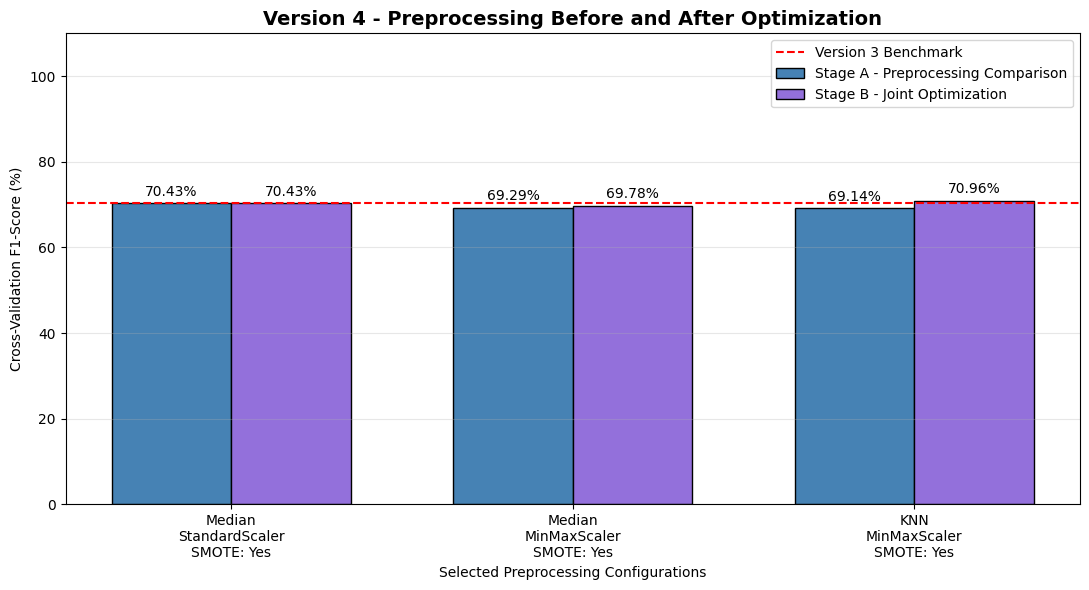

In [ ]:
# Compare preprocessing performance before and after tuning

stage_a_scores = (
    top_preprocessing_v4['CV F1-Score (%)']
    .to_numpy()
)

stage_b_scores = (
    stage_b_df_v4
    .sort_values('Configuration')['CV F1-Score (%)']
    .to_numpy()
)

configuration_labels = []

for index, row in top_preprocessing_v4.iterrows():

    configuration_labels.append(
        f"{row['Imputation']}\n"
        f"{row['Scaler']}\n"
        f"SMOTE: {row['SMOTE']}"
    )

x = np.arange(len(configuration_labels))
width = 0.35

plt.figure(figsize=(11, 6))

bars1 = plt.bar(
    x - width / 2,
    stage_a_scores,
    width,
    label='Stage A - Preprocessing Comparison',
    color='steelblue',
    edgecolor='black'
)

bars2 = plt.bar(
    x + width / 2,
    stage_b_scores,
    width,
    label='Stage B - Joint Optimization',
    color='mediumpurple',
    edgecolor='black'
)

plt.bar_label(bars1, fmt='%.2f%%', padding=3)
plt.bar_label(bars2, fmt='%.2f%%', padding=3)

plt.axhline(
    v3_cv_summary['f1'] * 100,
    color='red',
    linestyle='--',
    label='Version 3 Benchmark'
)

plt.title(
    'Version 4 - Preprocessing Before and After Optimization',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Selected Preprocessing Configurations')
plt.ylabel('Cross-Validation F1-Score (%)')

plt.xticks(x, configuration_labels)
plt.ylim(0, 110)
plt.legend(loc='upper right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Add Version 4 results to the model comparison table

v4_result = {
    'Model': 'Version 4 - Advanced Preprocessing KNN',
    'Optimal K': best_k_v4,
    'Weights': best_weights_v4,
    'Distance Metric': best_metric_v4,
    'Imputation': best_imputation_v4,
    'Imputer Neighbors': best_imputer_neighbors_v4,
    'Scaler': best_scaler_v4,
    'SMOTE': best_smote_v4,
    'SMOTE Ratio': best_sampling_v4,
    'SMOTE Neighbors': best_smote_neighbors_v4,
    'Selection Metric': 'F1-Score',
    'CV Accuracy (%)': v4_cv_summary['accuracy'] * 100,
    'CV Precision (%)': v4_cv_summary['precision'] * 100,
    'CV Recall (%)': v4_cv_summary['recall'] * 100,
    'CV F1-Score (%)': v4_cv_summary['f1'] * 100,
    'CV ROC-AUC': v4_cv_summary['roc_auc']
}

# Prevent duplicate entries

model_results = [
    result for result in model_results
    if result['Model'] != v4_result['Model']
]

model_results.append(v4_result)

comparison_df = pd.DataFrame(model_results)

comparison_display = comparison_df.copy()

for column in [
    'Imputer Neighbors',
    'SMOTE Ratio',
    'SMOTE Neighbors'
]:

    comparison_display[column] = (
        comparison_display[column]
        .astype(object)
        .where(
            comparison_display[column].notna(),
            'N/A'
        )
    )

print("Complete Model Performance Comparison Table:\n")

display(comparison_display.round(4))

print("\nVersion 4 successfully added to the comparison table!")

Complete Model Performance Comparison Table:



,Model,Optimal K,Weights,Distance Metric,Imputation,Scaler,SMOTE,Selection Metric,CV Accuracy (%),CV Precision (%),CV Recall (%),CV F1-Score (%),CV ROC-AUC,SMOTE Ratio,SMOTE Neighbors,Imputer Neighbors
0,Version 1 - Baseline KNN,13,uniform,euclidean,Median,StandardScaler,No,Accuracy,77.5237,72.0985,60.3212,65.3198,0.8282,N/A,N/A,N/A
1,Version 2 - Hyperparameter Optimized KNN,13,uniform,euclidean,Median,StandardScaler,No,F1-Score,77.5237,72.0985,60.3212,65.3198,0.8282,N/A,N/A,N/A
2,Version 3 - SMOTE-KNN,21,distance,euclidean,Median,StandardScaler,Yes,F1-Score,76.2135,63.1711,80.3876,70.4312,0.8359,0.9,3.0,N/A
3,Version 4 - Advanced Preprocessing KNN,25,distance,euclidean,KNN,MinMaxScaler,Yes,F1-Score,76.3748,62.7414,82.2481,70.9576,0.8403,1.0,5.0,3.0



Version 4 successfully added to the comparison table!


In [ ]:
# Calculate Version 4 performance changes

v4_improvement = []

for metric, label in metric_labels.items():

    baseline_value = baseline_cv_summary[metric] * 100
    v3_value = v3_cv_summary[metric] * 100
    v4_value = v4_cv_summary[metric] * 100

    change_from_v1 = v4_value - baseline_value
    change_from_v3 = v4_value - v3_value

    if np.isclose(change_from_v1, 0):
        change_from_v1 = 0.0

    if np.isclose(change_from_v3, 0):
        change_from_v3 = 0.0

    v4_improvement.append({
        'Metric': label,
        'Version 1 (%)': baseline_value,
        'Version 3 (%)': v3_value,
        'Version 4 (%)': v4_value,
        'Change from V1 (pp)': change_from_v1,
        'Change from V3 (pp)': change_from_v3
    })

v4_improvement_df = pd.DataFrame(
    v4_improvement
)

print("Version 4 - Performance Improvement Analysis:\n")

display(v4_improvement_df.round(2))

f1_improvement_v4 = (
    v4_cv_summary['f1'] -
    baseline_cv_summary['f1']
) * 100

recall_improvement_v4 = (
    v4_cv_summary['recall'] -
    baseline_cv_summary['recall']
) * 100

f1_change_from_v3 = (
    v4_cv_summary['f1'] -
    v3_cv_summary['f1']
) * 100

print(
    f"\nF1-Score Change from Baseline: "
    f"{f1_improvement_v4:+.2f} percentage points"
)

print(
    f"Recall Change from Baseline: "
    f"{recall_improvement_v4:+.2f} percentage points"
)

print(
    f"F1-Score Change from Version 3: "
    f"{f1_change_from_v3:+.2f} percentage points"
)

Version 4 - Performance Improvement Analysis:



,Metric,Version 1 (%),Version 3 (%),Version 4 (%),Change from V1 (pp),Change from V3 (pp)
0,Accuracy,77.52,76.21,76.37,-1.15,0.16
1,Precision,72.10,63.17,62.74,-9.36,-0.43
2,Recall,60.32,80.39,82.25,21.93,1.86
3,F1-Score,65.32,70.43,70.96,5.64,0.53
4,ROC-AUC,82.82,83.59,84.03,1.20,0.44



F1-Score Change from Baseline: +5.64 percentage points
Recall Change from Baseline: +21.93 percentage points
F1-Score Change from Version 3: +0.53 percentage points


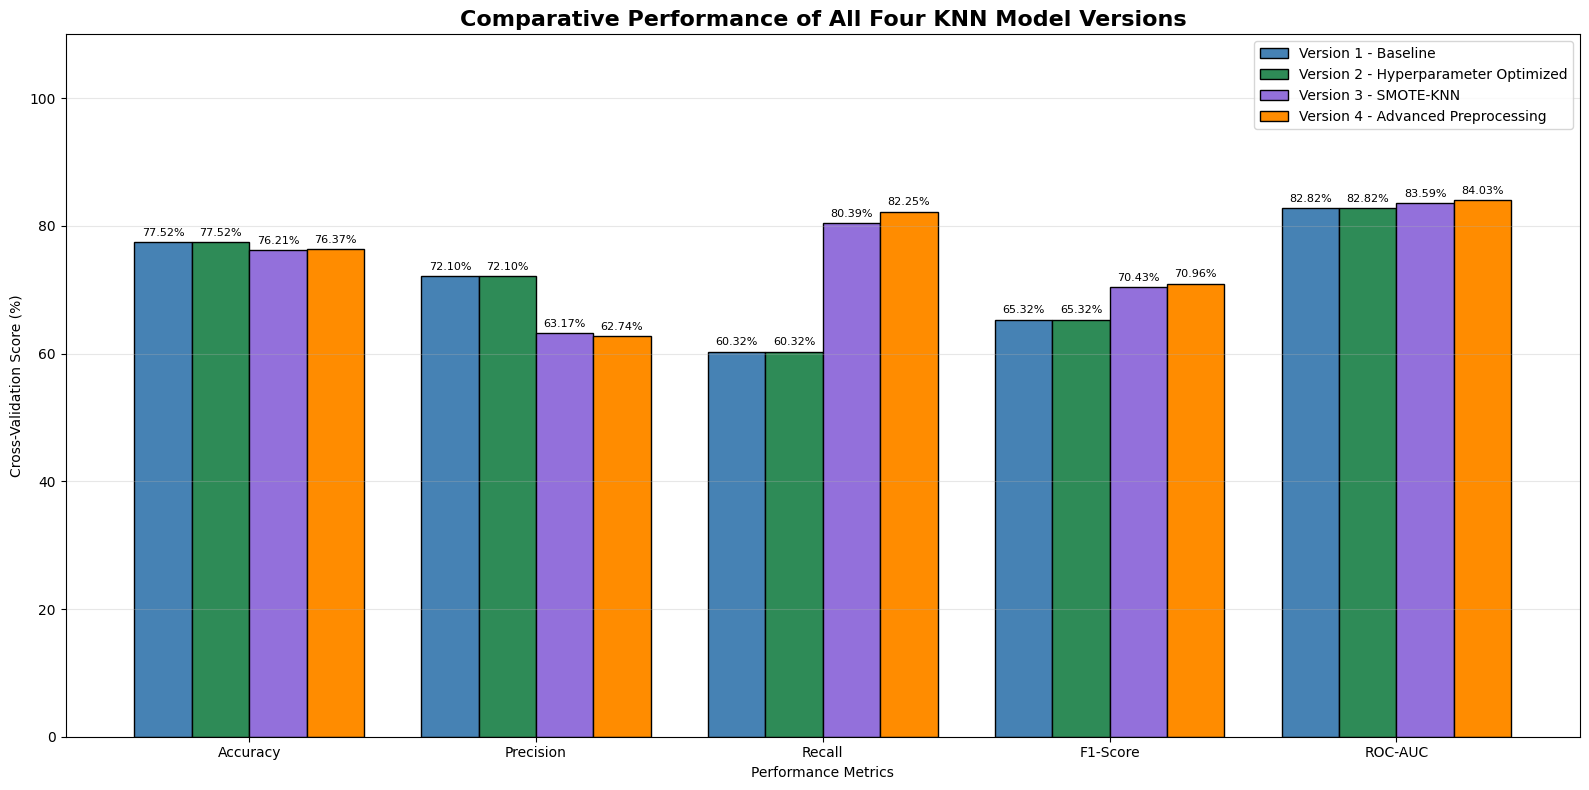

In [ ]:
# Compare all four KNN model versions

metric_names = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score',
    'ROC-AUC'
]

metric_keys = [
    'accuracy',
    'precision',
    'recall',
    'f1',
    'roc_auc'
]

version_summaries = [
    baseline_cv_summary,
    v2_cv_summary,
    v3_cv_summary,
    v4_cv_summary
]

version_labels = [
    'Version 1 - Baseline',
    'Version 2 - Hyperparameter Optimized',
    'Version 3 - SMOTE-KNN',
    'Version 4 - Advanced Preprocessing'
]

version_colors = [
    'steelblue',
    'seagreen',
    'mediumpurple',
    'darkorange'
]

x = np.arange(len(metric_names))
width = 0.20

plt.figure(figsize=(16, 8))

for index, summary in enumerate(version_summaries):

    values = [
        summary[metric] * 100
        for metric in metric_keys
    ]

    bars = plt.bar(
        x + (index - 1.5) * width,
        values,
        width,
        label=version_labels[index],
        color=version_colors[index],
        edgecolor='black'
    )

    plt.bar_label(
        bars,
        fmt='%.2f%%',
        padding=3,
        fontsize=8
    )

plt.title(
    'Comparative Performance of All Four KNN Model Versions',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Performance Metrics')
plt.ylabel('Cross-Validation Score (%)')

plt.xticks(x, metric_names)
plt.ylim(0, 110)
plt.legend(loc='upper right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

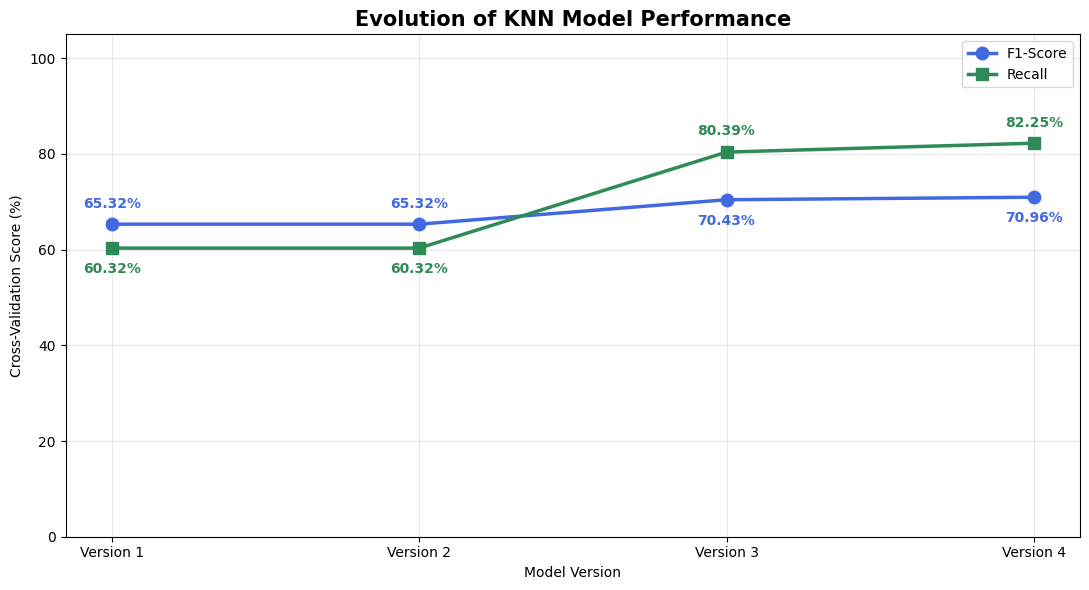

In [ ]:
# Visualize the model improvement journey

versions = [
    'Version 1',
    'Version 2',
    'Version 3',
    'Version 4'
]

f1_scores = [
    summary['f1'] * 100
    for summary in version_summaries
]

recall_scores = [
    summary['recall'] * 100
    for summary in version_summaries
]

plt.figure(figsize=(11, 6))

plt.plot(
    versions,
    f1_scores,
    marker='o',
    markersize=9,
    color='royalblue',
    linewidth=2.5,
    label='F1-Score'
)

plt.plot(
    versions,
    recall_scores,
    marker='s',
    markersize=9,
    color='seagreen',
    linewidth=2.5,
    label='Recall'
)

for index, score in enumerate(f1_scores):

    offset = 12 if score >= recall_scores[index] else -18

    plt.annotate(
        f'{score:.2f}%',
        (index, score),
        textcoords='offset points',
        xytext=(0, offset),
        ha='center',
        color='royalblue',
        fontweight='bold'
    )

for index, score in enumerate(recall_scores):

    offset = 12 if score > f1_scores[index] else -18

    plt.annotate(
        f'{score:.2f}%',
        (index, score),
        textcoords='offset points',
        xytext=(0, offset),
        ha='center',
        color='seagreen',
        fontweight='bold'
    )

plt.title(
    'Evolution of KNN Model Performance',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Model Version')
plt.ylabel('Cross-Validation Score (%)')

plt.ylim(0, 105)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Generate Version 4 experimental summary

print("=" * 65)
print("       VERSION 4 - ADVANCED PREPROCESSING EXPERIMENT")
print("=" * 65)

print("\nStage A - Preprocessing Comparison:")

print("Configurations Investigated:",
      total_preprocessing_combinations)

print("Cross-Validation Fits:",
      total_preprocessing_combinations *
      comparison_cv.n_splits)

print("\nStage B - Joint Optimization:")

print("Configurations Selected:",
      len(top_preprocessing_v4))

print("Hyperparameter Combinations:",
      total_combinations_v4)

print("Cross-Validation Fits:",
      total_fits_v4)

print("\nOptimal Version 4 Configuration:")

print("Imputation:", best_imputation_v4)
print("Imputer Neighbors:", best_imputer_neighbors_v4)
print("Scaler:", best_scaler_v4)
print("SMOTE:", best_smote_v4)
print("SMOTE Ratio:", best_sampling_v4)
print("SMOTE Neighbors:", best_smote_neighbors_v4)
print("Optimal K:", best_k_v4)
print("Weights:", best_weights_v4)
print("Distance Metric:", best_metric_v4)

print("\nCross-Validation F1-Score Comparison:")

for label, summary in zip(
    version_labels,
    version_summaries
):

    print(
        f"{label:40s}: "
        f"{summary['f1'] * 100:.2f}%"
    )

print("\nPerformance Changes:")

print(
    f"F1-Score Change from Baseline: "
    f"{f1_improvement_v4:+.2f} pp"
)

print(
    f"Recall Change from Baseline: "
    f"{recall_improvement_v4:+.2f} pp"
)

print(
    f"F1-Score Change from Version 3: "
    f"{f1_change_from_v3:+.2f} pp"
)

print("\nExperimental Conclusion:")

if np.isclose(f1_change_from_v3, 0):

    print("Version 4 matched Version 3 in CV F1-score.")

elif f1_change_from_v3 > 0:

    print("Version 4 improved upon Version 3 in CV F1-score.")

else:

    print("Version 3 retained a higher CV F1-score.")

print("\nFinal model selection will be conducted in Step 16.")

print("The testing dataset was not used for Version 4 optimization.")

print("=" * 65)

       VERSION 4 - ADVANCED PREPROCESSING EXPERIMENT

Stage A - Preprocessing Comparison:
Configurations Investigated: 12
Cross-Validation Fits: 60

Stage B - Joint Optimization:
Configurations Selected: 3
Hyperparameter Combinations: 3780
Cross-Validation Fits: 18900

Optimal Version 4 Configuration:
Imputation: KNN
Imputer Neighbors: 3
Scaler: MinMaxScaler
SMOTE: Yes
SMOTE Ratio: 1.0
SMOTE Neighbors: 5
Optimal K: 25
Weights: distance
Distance Metric: euclidean

Cross-Validation F1-Score Comparison:
Version 1 - Baseline                    : 65.32%
Version 2 - Hyperparameter Optimized    : 65.32%
Version 3 - SMOTE-KNN                   : 70.43%
Version 4 - Advanced Preprocessing      : 70.96%

Performance Changes:
F1-Score Change from Baseline: +5.64 pp
Recall Change from Baseline: +21.93 pp
F1-Score Change from Version 3: +0.53 pp

Experimental Conclusion:
Version 4 improved upon Version 3 in CV F1-score.

Final model selection will be conducted in Step 16.
The testing dataset was not

**VERSION 4: EXPERIMENTAL OBSERVATIONS AND ANALYSIS**

**Stage A: Preprocessing Comparison**

1. Two missing-value imputation techniques, three feature scaling techniques and two class-balancing approaches were investigated.

2. A total of 12 preprocessing configurations were evaluated using five-fold stratified cross-validation, resulting in 60 cross-validation model fits.

3. Median imputation with StandardScaler and SMOTE achieved the highest Stage A cross-validation F1-score of 70.43%, reproducing the performance of Version 3.

4. All six configurations incorporating SMOTE achieved higher F1-scores than their corresponding configurations without SMOTE under the investigated Stage A settings.

5. The three strongest preprocessing configurations selected for Stage B were:
   - Median Imputation + StandardScaler + SMOTE
   - Median Imputation + MinMaxScaler + SMOTE
   - KNN Imputation + MinMaxScaler + SMOTE

**Stage B: Joint Hyperparameter Optimization**

6. A total of 3,780 hyperparameter combinations and 18,900 cross-validation model fits were evaluated during Stage B.

7. Including both stages, Version 4 performed a total of 18,960 cross-validation model fits.

8. The KNN imputation, MinMaxScaler and SMOTE configuration improved its cross-validation F1-score from 69.14% in Stage A to 70.96% in Stage B.

9. The optimal Version 4 configuration was found to be:
   - Imputation Method: KNN Imputation
   - KNN Imputer Neighbors: 3
   - Feature Scaling: MinMaxScaler
   - SMOTE Sampling Ratio: 1.0
   - SMOTE Neighbors: 5
   - Number of Neighbors (K): 25
   - Neighbor Weights: Distance
   - Distance Metric: Euclidean

**Performance Analysis**

10. The optimized Version 4 model achieved the following cross-validation performance:
    - Accuracy: 76.37%
    - Precision: 62.74%
    - Recall: 82.25%
    - F1-Score: 70.96%
    - ROC-AUC: 0.8403

11. Compared with the baseline model, recall improved by 21.93 percentage points and F1-score improved by 5.64 percentage points.

12. Compared with Version 3, recall improved by 1.86 percentage points and F1-score improved by 0.53 percentage points.

13. ROC-AUC increased from 0.8282 in the baseline model to 0.8403 in Version 4.

14. Accuracy and precision decreased compared with the baseline model, demonstrating the trade-off associated with improving minority-class classification.

15. The cross-validation F1-score standard deviation decreased from 5.15 percentage points in the baseline model to 2.95 percentage points in Version 4, indicating more consistent performance across the investigated folds.

**Preprocessing and Data Leakage Prevention**

16. Feature scaling was performed before KNN imputation to reduce the influence of differences in feature magnitudes on distance calculations.

17. Missing-value imputation, feature scaling and SMOTE were integrated into the model pipeline to prevent leakage between training and validation folds.

18. The testing dataset was not used during Version 4 preprocessing or hyperparameter optimization.

**Experimental Limitations**

19. The two-stage optimization strategy investigated only the three strongest Stage A configurations in Stage B. Therefore, the experiment was a targeted search rather than an exhaustive evaluation of all possible preprocessing and hyperparameter combinations.

20. The cross-validation performance estimates were influenced by model and hyperparameter selection. Consequently, they should not be interpreted as independent estimates of generalization performance.

21. The relatively small F1-score difference between Versions 3 and 4 does not establish a statistically significant improvement.

**Conclusion of Version 4**

The combination of KNN imputation, MinMaxScaler, SMOTE and advanced hyperparameter optimization produced the highest cross-validation F1-score, recall and ROC-AUC among the four selected model versions.

The results suggest that appropriate preprocessing and class balancing, combined with hyperparameter optimization, can improve minority-class classification performance within the investigated development framework.

Version 4 is currently the leading candidate for final model selection based on cross-validation F1-score.

Final model selection, comparative testing evaluation and generalization performance analysis will be conducted in the next stage.

**COMPARATIVE PERFORMANCE ANALYSIS AND FINAL MODEL SELECTION**

Four versions of the KNN classification model were developed
and evaluated through successive optimization experiments.

The final model is selected based on the highest mean
cross-validation F1-score.

All four model versions are evaluated on the same original
testing dataset to ensure a consistent performance comparison.

The comparative evaluation includes:

- Training accuracy
- Cross-validation performance
- Testing accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion matrices
- Classification reports
- False-positive and false-negative analysis
- Generalization performance

The objective is to determine the effectiveness of the
optimization strategies compared with the baseline model.

No further hyperparameter optimization or model selection
is performed using the testing results.

In [ ]:
# Preserve all four KNN model versions

all_models = {
    'Version 1': baseline_model,
    'Version 2': optimized_model_v2,
    'Version 3': optimized_model_v3,
    'Version 4': optimized_model_v4
}

all_cv_summaries = {
    'Version 1': baseline_cv_summary,
    'Version 2': v2_cv_summary,
    'Version 3': v3_cv_summary,
    'Version 4': v4_cv_summary
}

model_descriptions = {
    'Version 1': 'Baseline KNN',
    'Version 2': 'Hyperparameter-Optimized KNN',
    'Version 3': 'SMOTE-KNN',
    'Version 4': 'Advanced Preprocessing KNN'
}

print("All four KNN model versions preserved successfully!\n")

for version, model in all_models.items():

    print(f"{version}: {model_descriptions[version]}")

print("\nTotal Models Available:", len(all_models))

All four KNN model versions preserved successfully!

Version 1: Baseline KNN
Version 2: Hyperparameter-Optimized KNN
Version 3: SMOTE-KNN
Version 4: Advanced Preprocessing KNN

Total Models Available: 4


In [ ]:
# Select the final model using cross-validation F1-score

cv_ranking = []

for version, summary in all_cv_summaries.items():

    cv_ranking.append({
        'Model': version,
        'Description': model_descriptions[version],
        'CV Accuracy (%)': summary['accuracy'] * 100,
        'CV Precision (%)': summary['precision'] * 100,
        'CV Recall (%)': summary['recall'] * 100,
        'CV F1-Score (%)': summary['f1'] * 100,
        'CV ROC-AUC': summary['roc_auc']
    })

cv_ranking_df = pd.DataFrame(cv_ranking)

cv_ranking_df = (
    cv_ranking_df
    .sort_values('CV F1-Score (%)', ascending=False)
    .reset_index(drop=True)
)

cv_ranking_df.insert(
    0,
    'Rank',
    range(1, len(cv_ranking_df) + 1)
)

print("Final Model Selection Based on Cross-Validation:\n")

display(cv_ranking_df.round(4))

final_model_version = cv_ranking_df.iloc[0]['Model']

final_model = all_models[final_model_version]

final_cv_summary = all_cv_summaries[
    final_model_version
]

final_model_name = model_descriptions[
    final_model_version
]

print("\nFinal Model Selected:", final_model_version)
print("Model Description:", final_model_name)
print("Selection Criterion: Cross-Validation F1-Score")

print(
    f"Best Cross-Validation F1-Score: "
    f"{final_cv_summary['f1'] * 100:.2f}%"
)

print("\nFinal model preserved successfully!")

Final Model Selection Based on Cross-Validation:



,Rank,Model,Description,CV Accuracy (%),CV Precision (%),CV Recall (%),CV F1-Score (%),CV ROC-AUC
0,1,Version 4,Advanced Preprocessing KNN,76.3748,62.7414,82.2481,70.9576,0.8403
1,2,Version 3,SMOTE-KNN,76.2135,63.1711,80.3876,70.4312,0.8359
2,3,Version 2,Hyperparameter-Optimized KNN,77.5237,72.0985,60.3212,65.3198,0.8282
3,4,Version 1,Baseline KNN,77.5237,72.0985,60.3212,65.3198,0.8282



Final Model Selected: Version 4
Model Description: Advanced Preprocessing KNN
Selection Criterion: Cross-Validation F1-Score
Best Cross-Validation F1-Score: 70.96%

Final model preserved successfully!


In [ ]:
# Display the selected final model configuration

final_knn = final_model.named_steps['knn']
final_imputer = final_model.named_steps['imputer']
final_scaler = final_model.named_steps['scaler']
final_smote = final_model.named_steps.get('smote')

print("=" * 60)
print("          FINAL SELECTED KNN MODEL CONFIGURATION")
print("=" * 60)

print("\nModel Version:", final_model_version)
print("Model Description:", final_model_name)

print("\nPipeline Steps:")

for step_name, step in final_model.steps:

    print(f"{step_name}: {type(step).__name__}")

print("\nMissing-Value Imputation:")

print("Imputer:", type(final_imputer).__name__)

if isinstance(final_imputer, KNNImputer):

    print("Imputer Neighbors:", final_imputer.n_neighbors)

else:

    print("Imputation Strategy:", final_imputer.strategy)

print("\nFeature Scaling:")

print("Scaler:", type(final_scaler).__name__)

print("\nClass Balancing:")

if final_smote is not None:

    print("SMOTE: Enabled")
    print("Sampling Ratio:", final_smote.sampling_strategy)
    print("SMOTE Neighbors:", final_smote.k_neighbors)

else:

    print("SMOTE: Disabled")

print("\nKNN Classifier:")

print("Number of Neighbors:", final_knn.n_neighbors)
print("Neighbor Weights:", final_knn.weights)
print("Distance Metric:", final_knn.effective_metric_)

print("=" * 60)

          FINAL SELECTED KNN MODEL CONFIGURATION

Model Version: Version 4
Model Description: Advanced Preprocessing KNN

Pipeline Steps:
scaler: MinMaxScaler
imputer: KNNImputer
smote: SMOTE
knn: KNeighborsClassifier

Missing-Value Imputation:
Imputer: KNNImputer
Imputer Neighbors: 3

Feature Scaling:
Scaler: MinMaxScaler

Class Balancing:
SMOTE: Enabled
Sampling Ratio: 1.0
SMOTE Neighbors: 5

KNN Classifier:
Number of Neighbors: 25
Neighbor Weights: distance
Distance Metric: euclidean


In [ ]:
# Verify the original training and testing datasets

print("Dataset Configuration for Final Evaluation:\n")

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Dataset Shape:", X_train.shape)
print("Testing Dataset Shape:", X_test.shape)

test_class_counts = y_test.value_counts().sort_index()

print("\nTesting Class Distribution:\n")

print("Non-Diabetic Records:", test_class_counts[0])
print("Diabetic Records:", test_class_counts[1])

print("\nTesting Class Percentages:\n")

print(
    f"Non-Diabetic: "
    f"{test_class_counts[0] / len(y_test) * 100:.2f}%"
)

print(
    f"Diabetic: "
    f"{test_class_counts[1] / len(y_test) * 100:.2f}%"
)

assert len(X_train) == 614
assert len(X_test) == 154
assert X_train.index.intersection(X_test.index).empty

print("\nTraining and testing datasets verified successfully!")

Dataset Configuration for Final Evaluation:

Training Records: 614
Testing Records: 154

Training Dataset Shape: (614, 8)
Testing Dataset Shape: (154, 8)

Testing Class Distribution:

Non-Diabetic Records: 100
Diabetic Records: 54

Testing Class Percentages:

Non-Diabetic: 64.94%
Diabetic: 35.06%

Training and testing datasets verified successfully!


In [ ]:
# Evaluate all four preserved KNN models

evaluation_results = []

all_predictions = {}
all_probabilities = {}
all_confusion_matrices = {}
all_classification_reports = {}

print("Starting Comparative Model Evaluation...\n")

for version, model in all_models.items():

    # Generate predictions

    train_predictions = model.predict(X_train)

    test_predictions = model.predict(X_test)

    positive_class_index = list(model.classes_).index(1)

    test_probabilities = model.predict_proba(
        X_test
    )[:, positive_class_index]

    # Calculate performance metrics

    training_accuracy = accuracy_score(
        y_train, train_predictions
    )

    testing_accuracy = accuracy_score(
        y_test, test_predictions
    )

    testing_precision = precision_score(
        y_test, test_predictions,
        zero_division=0
    )

    testing_recall = recall_score(
        y_test, test_predictions,
        zero_division=0
    )

    testing_f1 = f1_score(
        y_test, test_predictions,
        zero_division=0
    )

    testing_auc = roc_auc_score(
        y_test, test_probabilities
    )

    # Calculate confusion matrix

    model_cm = confusion_matrix(
        y_test,
        test_predictions,
        labels=[0, 1]
    )

    tn, fp, fn, tp = model_cm.ravel()

    specificity = tn / (tn + fp)

    # Preserve evaluation results

    all_predictions[version] = test_predictions

    all_probabilities[version] = test_probabilities

    all_confusion_matrices[version] = model_cm

    all_classification_reports[version] = (
        classification_report(
            y_test,
            test_predictions,
            labels=[0, 1],
            target_names=[
                'Non-Diabetic',
                'Diabetic'
            ],
            digits=4,
            zero_division=0
        )
    )

    evaluation_results.append({
        'Model': version,
        'Description': model_descriptions[version],
        'Training Accuracy (%)':
            training_accuracy * 100,
        'CV Accuracy (%)':
            all_cv_summaries[version]['accuracy'] * 100,
        'CV F1-Score (%)':
            all_cv_summaries[version]['f1'] * 100,
        'Testing Accuracy (%)':
            testing_accuracy * 100,
        'Testing Precision (%)':
            testing_precision * 100,
        'Testing Recall (%)':
            testing_recall * 100,
        'Testing F1-Score (%)':
            testing_f1 * 100,
        'Testing ROC-AUC':
            testing_auc,
        'Specificity (%)':
            specificity * 100,
        'True Negatives': tn,
        'False Positives': fp,
        'False Negatives': fn,
        'True Positives': tp
    })

    print(f"{version} - {model_descriptions[version]}")

    print(f"Training Accuracy: {training_accuracy * 100:.2f}%")
    print(f"Testing Accuracy: {testing_accuracy * 100:.2f}%")
    print(f"Testing Precision: {testing_precision * 100:.2f}%")
    print(f"Testing Recall: {testing_recall * 100:.2f}%")
    print(f"Testing F1-Score: {testing_f1 * 100:.2f}%")
    print(f"Testing ROC-AUC: {testing_auc:.4f}")

    print("\nConfusion Matrix:")
    print(model_cm)

    print("-" * 60)

evaluation_df = pd.DataFrame(evaluation_results)

print("\nComparative evaluation completed successfully!")

Starting Comparative Model Evaluation...

Version 1 - Baseline KNN
Training Accuracy: 80.62%
Testing Accuracy: 71.43%
Testing Precision: 60.87%
Testing Recall: 51.85%
Testing F1-Score: 56.00%
Testing ROC-AUC: 0.7944

Confusion Matrix:
[[82 18]
 [26 28]]
------------------------------------------------------------
Version 2 - Hyperparameter-Optimized KNN
Training Accuracy: 80.62%
Testing Accuracy: 71.43%
Testing Precision: 60.87%
Testing Recall: 51.85%
Testing F1-Score: 56.00%
Testing ROC-AUC: 0.7944

Confusion Matrix:
[[82 18]
 [26 28]]
------------------------------------------------------------
Version 3 - SMOTE-KNN
Training Accuracy: 100.00%
Testing Accuracy: 70.78%
Testing Precision: 56.52%
Testing Recall: 72.22%
Testing F1-Score: 63.41%
Testing ROC-AUC: 0.7994

Confusion Matrix:
[[70 30]
 [15 39]]
------------------------------------------------------------
Version 4 - Advanced Preprocessing KNN
Training Accuracy: 100.00%
Testing Accuracy: 71.43%
Testing Precision: 56.94%
Testing 

In [ ]:
# Display comparative testing performance

testing_comparison_df = evaluation_df[[
    'Model',
    'Description',
    'Testing Accuracy (%)',
    'Testing Precision (%)',
    'Testing Recall (%)',
    'Testing F1-Score (%)',
    'Testing ROC-AUC',
    'Specificity (%)'
]].copy()

print("Complete Testing Performance Comparison:\n")

display(testing_comparison_df.round(4))

print("\nFinal Selected Model:", final_model_version)

final_test_row = evaluation_df.loc[
    evaluation_df['Model'] == final_model_version
].iloc[0]

print("\nFinal Model Testing Performance:\n")

print(
    f"Accuracy: "
    f"{final_test_row['Testing Accuracy (%)']:.2f}%"
)

print(
    f"Precision: "
    f"{final_test_row['Testing Precision (%)']:.2f}%"
)

print(
    f"Recall: "
    f"{final_test_row['Testing Recall (%)']:.2f}%"
)

print(
    f"F1-Score: "
    f"{final_test_row['Testing F1-Score (%)']:.2f}%"
)

print(
    f"ROC-AUC: "
    f"{final_test_row['Testing ROC-AUC']:.4f}"
)

print(
    f"Specificity: "
    f"{final_test_row['Specificity (%)']:.2f}%"
)

Complete Testing Performance Comparison:



,Model,Description,Testing Accuracy (%),Testing Precision (%),Testing Recall (%),Testing F1-Score (%),Testing ROC-AUC,Specificity (%)
0,Version 1,Baseline KNN,71.4286,60.8696,51.8519,56.0000,0.7944,82.0
1,Version 2,Hyperparameter-Optimized KNN,71.4286,60.8696,51.8519,56.0000,0.7944,82.0
2,Version 3,SMOTE-KNN,70.7792,56.5217,72.2222,63.4146,0.7994,70.0
3,Version 4,Advanced Preprocessing KNN,71.4286,56.9444,75.9259,65.0794,0.7793,69.0



Final Selected Model: Version 4

Final Model Testing Performance:

Accuracy: 71.43%
Precision: 56.94%
Recall: 75.93%
F1-Score: 65.08%
ROC-AUC: 0.7793
Specificity: 69.00%


In [ ]:
# Display classification reports for all model versions

for version, report in all_classification_reports.items():

    print("=" * 65)

    print(f"{version} - {model_descriptions[version]}")

    print("=" * 65)

    print("\nClassification Report:\n")

    print(report)

    print()

Version 1 - Baseline KNN

Classification Report:

              precision    recall  f1-score   support

Non-Diabetic     0.7593    0.8200    0.7885       100
    Diabetic     0.6087    0.5185    0.5600        54

    accuracy                         0.7143       154
   macro avg     0.6840    0.6693    0.6742       154
weighted avg     0.7065    0.7143    0.7084       154


Version 2 - Hyperparameter-Optimized KNN

Classification Report:

              precision    recall  f1-score   support

Non-Diabetic     0.7593    0.8200    0.7885       100
    Diabetic     0.6087    0.5185    0.5600        54

    accuracy                         0.7143       154
   macro avg     0.6840    0.6693    0.6742       154
weighted avg     0.7065    0.7143    0.7084       154


Version 3 - SMOTE-KNN

Classification Report:

              precision    recall  f1-score   support

Non-Diabetic     0.8235    0.7000    0.7568       100
    Diabetic     0.5652    0.7222    0.6341        54

    accuracy     

In [ ]:
# Compare classification errors across all models

confusion_comparison_df = evaluation_df[[
    'Model',
    'True Negatives',
    'False Positives',
    'False Negatives',
    'True Positives'
]].copy()

confusion_comparison_df['Correct Predictions'] = (
    confusion_comparison_df['True Negatives'] +
    confusion_comparison_df['True Positives']
)

confusion_comparison_df['Incorrect Predictions'] = (
    confusion_comparison_df['False Positives'] +
    confusion_comparison_df['False Negatives']
)

print("Comparative Confusion Matrix Analysis:\n")

display(confusion_comparison_df)

print("\nTotal Testing Records:", len(y_test))

Comparative Confusion Matrix Analysis:



,Model,True Negatives,False Positives,False Negatives,True Positives,Correct Predictions,Incorrect Predictions
0,Version 1,82,18,26,28,110,44
1,Version 2,82,18,26,28,110,44
2,Version 3,70,30,15,39,109,45
3,Version 4,69,31,13,41,110,44



Total Testing Records: 154


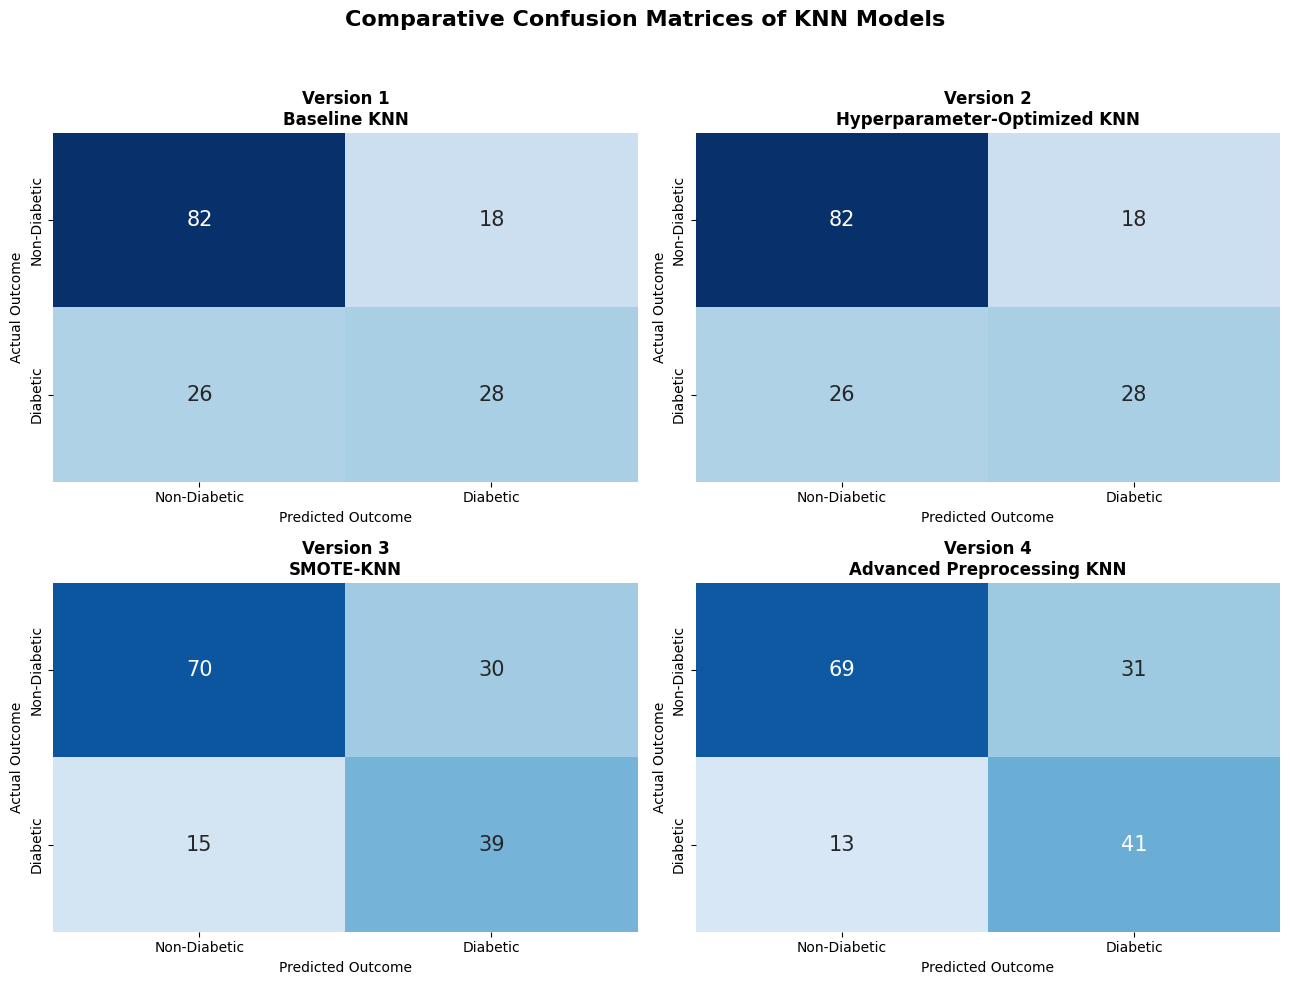

In [ ]:
# Visualize confusion matrices of all four models

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

axes = axes.flatten()

maximum_count = max(
    matrix.max()
    for matrix in all_confusion_matrices.values()
)

for index, (version, matrix) in enumerate(
    all_confusion_matrices.items()
):

    sns.heatmap(
        matrix,
        annot=True,
        fmt='d',
        cmap='Blues',
        vmin=0,
        vmax=maximum_count,
        cbar=False,
        annot_kws={'size': 15},
        xticklabels=[
            'Non-Diabetic',
            'Diabetic'
        ],
        yticklabels=[
            'Non-Diabetic',
            'Diabetic'
        ],
        ax=axes[index]
    )

    axes[index].set_title(
        f"{version}\n{model_descriptions[version]}",
        fontsize=12,
        fontweight='bold'
    )

    axes[index].set_xlabel('Predicted Outcome')
    axes[index].set_ylabel('Actual Outcome')

fig.suptitle(
    'Comparative Confusion Matrices of KNN Models',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()

In [ ]:
# Analyze changes in false positives and false negatives

baseline_error_row = evaluation_df.loc[
    evaluation_df['Model'] == 'Version 1'
].iloc[0]

baseline_false_negatives = int(
    baseline_error_row['False Negatives']
)

baseline_false_positives = int(
    baseline_error_row['False Positives']
)

error_analysis = []

for index, row in evaluation_df.iterrows():

    current_fn = int(row['False Negatives'])
    current_fp = int(row['False Positives'])

    fn_reduction = (
        baseline_false_negatives - current_fn
    )

    fp_change = (
        current_fp - baseline_false_positives
    )

    fn_reduction_percent = (
        fn_reduction /
        baseline_false_negatives * 100
        if baseline_false_negatives != 0
        else np.nan
    )

    error_analysis.append({
        'Model': row['Model'],
        'False Negatives': current_fn,
        'False Positives': current_fp,
        'FN Reduction (Records)': fn_reduction,
        'FN Reduction (%)': fn_reduction_percent,
        'FP Change (Records)': fp_change
    })

error_analysis_df = pd.DataFrame(error_analysis)

print("False-Positive and False-Negative Analysis:\n")

display(error_analysis_df.round(2))

final_error_row = error_analysis_df.loc[
    error_analysis_df['Model'] == final_model_version
].iloc[0]

print("\nFinal Model Error Analysis:\n")

print("Baseline False Negatives:",
      baseline_false_negatives)

print("Final Model False Negatives:",
      int(final_error_row['False Negatives']))

print("False Negatives Reduced:",
      int(final_error_row['FN Reduction (Records)']))

print(
    f"Relative False-Negative Reduction: "
    f"{final_error_row['FN Reduction (%)']:.2f}%"
)

print("\nBaseline False Positives:",
      baseline_false_positives)

print("Final Model False Positives:",
      int(final_error_row['False Positives']))

print(
    f"False-Positive Change: "
    f"{int(final_error_row['FP Change (Records)']):+d}"
)

False-Positive and False-Negative Analysis:



,Model,False Negatives,False Positives,FN Reduction (Records),FN Reduction (%),FP Change (Records)
0,Version 1,26,18,0,0.00,0
1,Version 2,26,18,0,0.00,0
2,Version 3,15,30,11,42.31,12
3,Version 4,13,31,13,50.00,13



Final Model Error Analysis:

Baseline False Negatives: 26
Final Model False Negatives: 13
False Negatives Reduced: 13
Relative False-Negative Reduction: 50.00%

Baseline False Positives: 18
Final Model False Positives: 31
False-Positive Change: +13


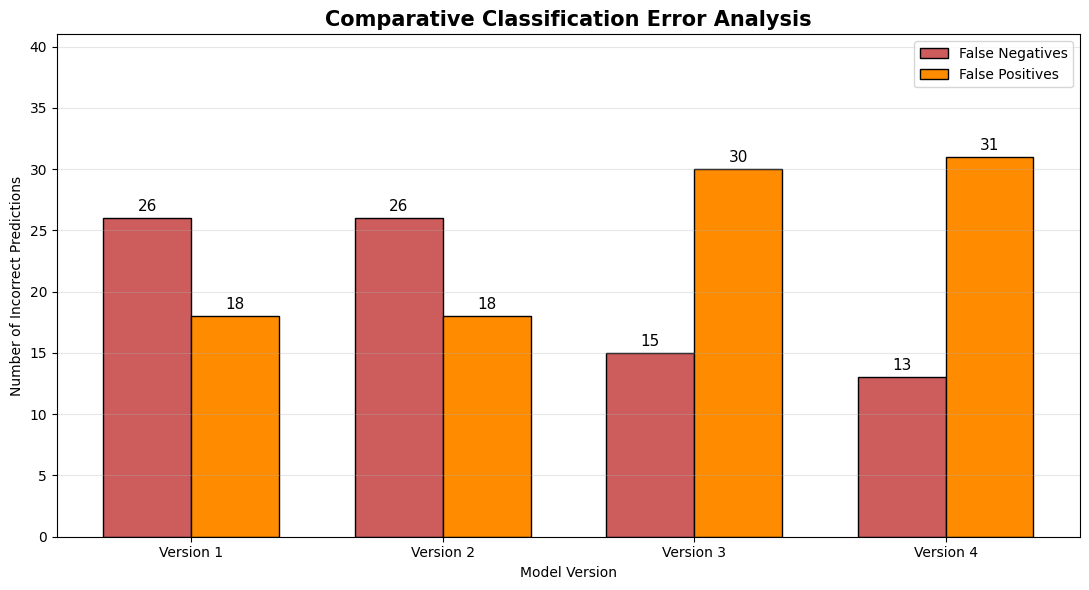

In [ ]:
# Visualize false positives and false negatives

x = np.arange(len(error_analysis_df))
width = 0.35

plt.figure(figsize=(11, 6))

bars1 = plt.bar(
    x - width / 2,
    error_analysis_df['False Negatives'],
    width,
    label='False Negatives',
    color='indianred',
    edgecolor='black'
)

bars2 = plt.bar(
    x + width / 2,
    error_analysis_df['False Positives'],
    width,
    label='False Positives',
    color='darkorange',
    edgecolor='black'
)

plt.bar_label(bars1, padding=3, fontsize=11)
plt.bar_label(bars2, padding=3, fontsize=11)

plt.title(
    'Comparative Classification Error Analysis',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Model Version')
plt.ylabel('Number of Incorrect Predictions')

plt.xticks(
    x,
    error_analysis_df['Model']
)

maximum_error = max(
    error_analysis_df['False Negatives'].max(),
    error_analysis_df['False Positives'].max()
)

plt.ylim(0, maximum_error + 10)

plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

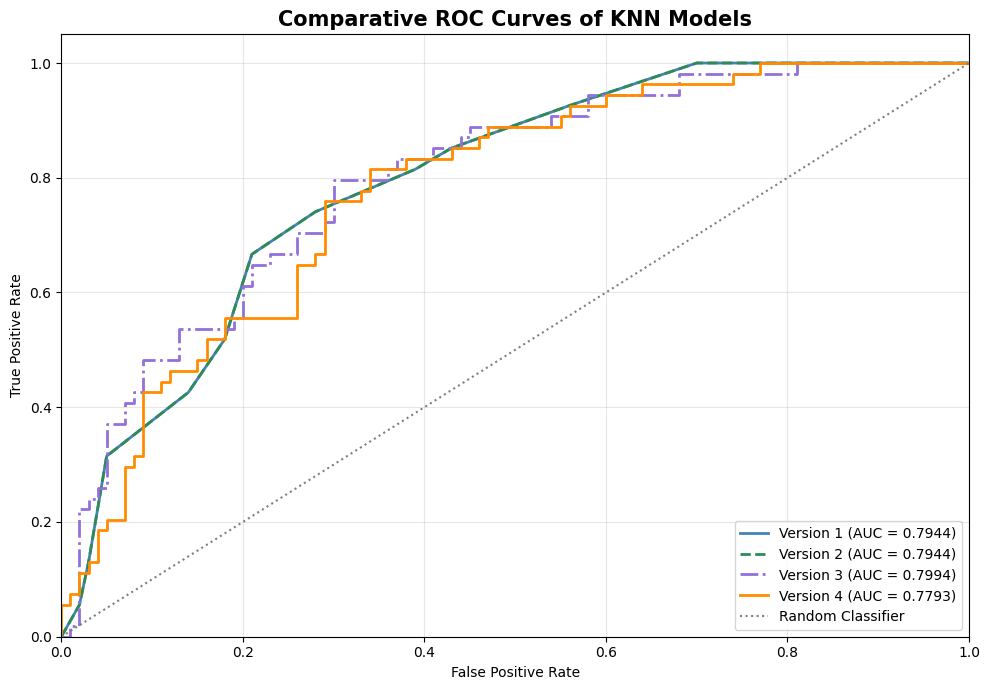

In [ ]:
# Compare ROC curves of all four KNN models

roc_colors = {
    'Version 1': 'steelblue',
    'Version 2': 'seagreen',
    'Version 3': 'mediumpurple',
    'Version 4': 'darkorange'
}

roc_styles = {
    'Version 1': '-',
    'Version 2': '--',
    'Version 3': '-.',
    'Version 4': '-'
}

plt.figure(figsize=(10, 7))

for version, probabilities in all_probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities
    )

    model_auc = roc_auc_score(
        y_test,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        color=roc_colors[version],
        linestyle=roc_styles[version],
        linewidth=2,
        label=f'{version} (AUC = {model_auc:.4f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    color='gray',
    linestyle=':',
    linewidth=1.5,
    label='Random Classifier'
)

plt.title(
    'Comparative ROC Curves of KNN Models',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

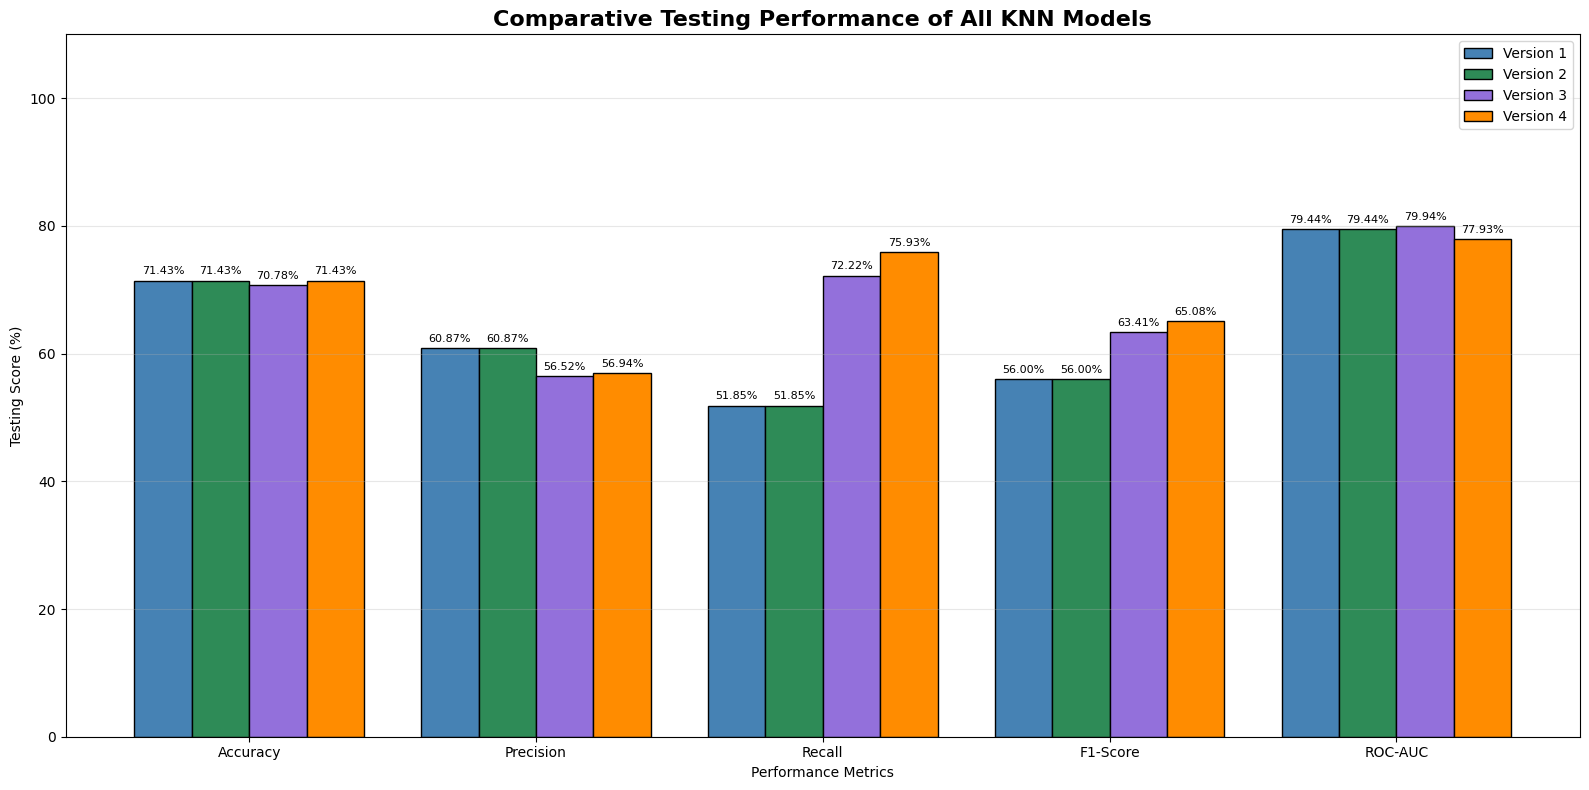

In [ ]:
# Compare testing performance of all four models

test_metric_names = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score',
    'ROC-AUC'
]

test_metric_columns = [
    'Testing Accuracy (%)',
    'Testing Precision (%)',
    'Testing Recall (%)',
    'Testing F1-Score (%)',
    'Testing ROC-AUC'
]

x = np.arange(len(test_metric_names))
width = 0.20

plt.figure(figsize=(16, 8))

for index, row in evaluation_df.iterrows():

    values = [
        row[column]
        for column in test_metric_columns
    ]

    # Convert ROC-AUC to percentage for visualization

    values[-1] *= 100

    bars = plt.bar(
        x + (index - 1.5) * width,
        values,
        width,
        label=row['Model'],
        color=roc_colors[row['Model']],
        edgecolor='black'
    )

    plt.bar_label(
        bars,
        fmt='%.2f%%',
        padding=3,
        fontsize=8
    )

plt.title(
    'Comparative Testing Performance of All KNN Models',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Performance Metrics')
plt.ylabel('Testing Score (%)')

plt.xticks(x, test_metric_names)
plt.ylim(0, 110)

plt.legend(loc='upper right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Analyze generalization performance

generalization_df = evaluation_df[[
    'Model',
    'Training Accuracy (%)',
    'CV Accuracy (%)',
    'Testing Accuracy (%)'
]].copy()

generalization_df['Train-Test Gap (pp)'] = (
    generalization_df['Training Accuracy (%)'] -
    generalization_df['Testing Accuracy (%)']
)

generalization_df['CV-Test Gap (pp)'] = (
    generalization_df['CV Accuracy (%)'] -
    generalization_df['Testing Accuracy (%)']
)

print("Generalization Performance Analysis:\n")

display(generalization_df.round(2))

print("\nInterpretation:")

print(
    "The training-testing accuracy gap indicates "
    "the difference between fitted training performance "
    "and performance on the reserved testing dataset."
)

print(
    "\nA large positive gap may suggest overfitting "
    "or limited generalization."
)

print(
    "\nThe gap alone does not establish overfitting, "
    "and cross-validation scores are affected by "
    "hyperparameter selection."
)

Generalization Performance Analysis:



,Model,Training Accuracy (%),CV Accuracy (%),Testing Accuracy (%),Train-Test Gap (pp),CV-Test Gap (pp)
0,Version 1,80.62,77.52,71.43,9.19,6.10
1,Version 2,80.62,77.52,71.43,9.19,6.10
2,Version 3,100.00,76.21,70.78,29.22,5.43
3,Version 4,100.00,76.37,71.43,28.57,4.95



Interpretation:
The training-testing accuracy gap indicates the difference between fitted training performance and performance on the reserved testing dataset.

A large positive gap may suggest overfitting or limited generalization.

The gap alone does not establish overfitting, and cross-validation scores are affected by hyperparameter selection.


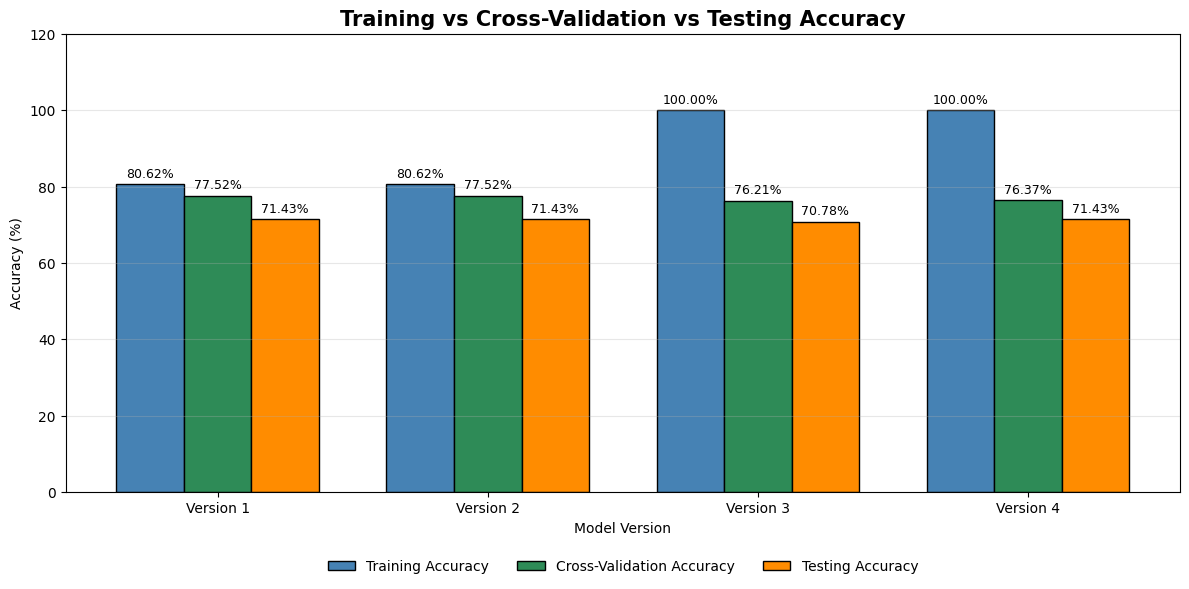

In [ ]:
# Visualize training, cross-validation and testing accuracy

x = np.arange(len(generalization_df))
width = 0.25

plt.figure(figsize=(12, 6))

bars1 = plt.bar(
    x - width,
    generalization_df['Training Accuracy (%)'],
    width,
    label='Training Accuracy',
    color='steelblue',
    edgecolor='black'
)

bars2 = plt.bar(
    x,
    generalization_df['CV Accuracy (%)'],
    width,
    label='Cross-Validation Accuracy',
    color='seagreen',
    edgecolor='black'
)

bars3 = plt.bar(
    x + width,
    generalization_df['Testing Accuracy (%)'],
    width,
    label='Testing Accuracy',
    color='darkorange',
    edgecolor='black'
)

plt.bar_label(bars1, fmt='%.2f%%', padding=3, fontsize=9)
plt.bar_label(bars2, fmt='%.2f%%', padding=3, fontsize=9)
plt.bar_label(bars3, fmt='%.2f%%', padding=3, fontsize=9)

plt.title(
    'Training vs Cross-Validation vs Testing Accuracy',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Model Version')
plt.ylabel('Accuracy (%)')

plt.xticks(
    x,
    generalization_df['Model']
)

plt.ylim(0, 120)

plt.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=False
)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Compare the baseline and final selected model

baseline_test_row = evaluation_df.loc[
    evaluation_df['Model'] == 'Version 1'
].iloc[0]

final_test_row = evaluation_df.loc[
    evaluation_df['Model'] == final_model_version
].iloc[0]

final_metric_columns = {
    'Accuracy': 'Testing Accuracy (%)',
    'Precision': 'Testing Precision (%)',
    'Recall': 'Testing Recall (%)',
    'F1-Score': 'Testing F1-Score (%)',
    'ROC-AUC': 'Testing ROC-AUC',
    'Specificity': 'Specificity (%)'
}

final_improvement_results = []

for metric, column in final_metric_columns.items():

    baseline_value = baseline_test_row[column]
    final_value = final_test_row[column]

    # Convert ROC-AUC to percentage for consistency

    if metric == 'ROC-AUC':

        baseline_value *= 100
        final_value *= 100

    difference = final_value - baseline_value

    if np.isclose(difference, 0):

        difference = 0.0
        status = 'No Change'

    elif difference > 0:

        status = 'Improved'

    else:

        status = 'Decreased'

    relative_change = (
        difference / baseline_value * 100
        if baseline_value != 0
        else np.nan
    )

    final_improvement_results.append({
        'Metric': metric,
        'Baseline (%)': baseline_value,
        'Final Model (%)': final_value,
        'Change (pp)': difference,
        'Relative Change (%)': relative_change,
        'Status': status
    })

final_improvement_df = pd.DataFrame(
    final_improvement_results
)

print("Baseline vs Final Model - Testing Improvements:\n")

display(final_improvement_df.round(2))

Baseline vs Final Model - Testing Improvements:



,Metric,Baseline (%),Final Model (%),Change (pp),Relative Change (%),Status
0,Accuracy,71.43,71.43,0.00,0.00,No Change
1,Precision,60.87,56.94,-3.93,-6.45,Decreased
2,Recall,51.85,75.93,24.07,46.43,Improved
3,F1-Score,56.00,65.08,9.08,16.21,Improved
4,ROC-AUC,79.44,77.93,-1.52,-1.91,Decreased
5,Specificity,82.00,69.00,-13.00,-15.85,Decreased


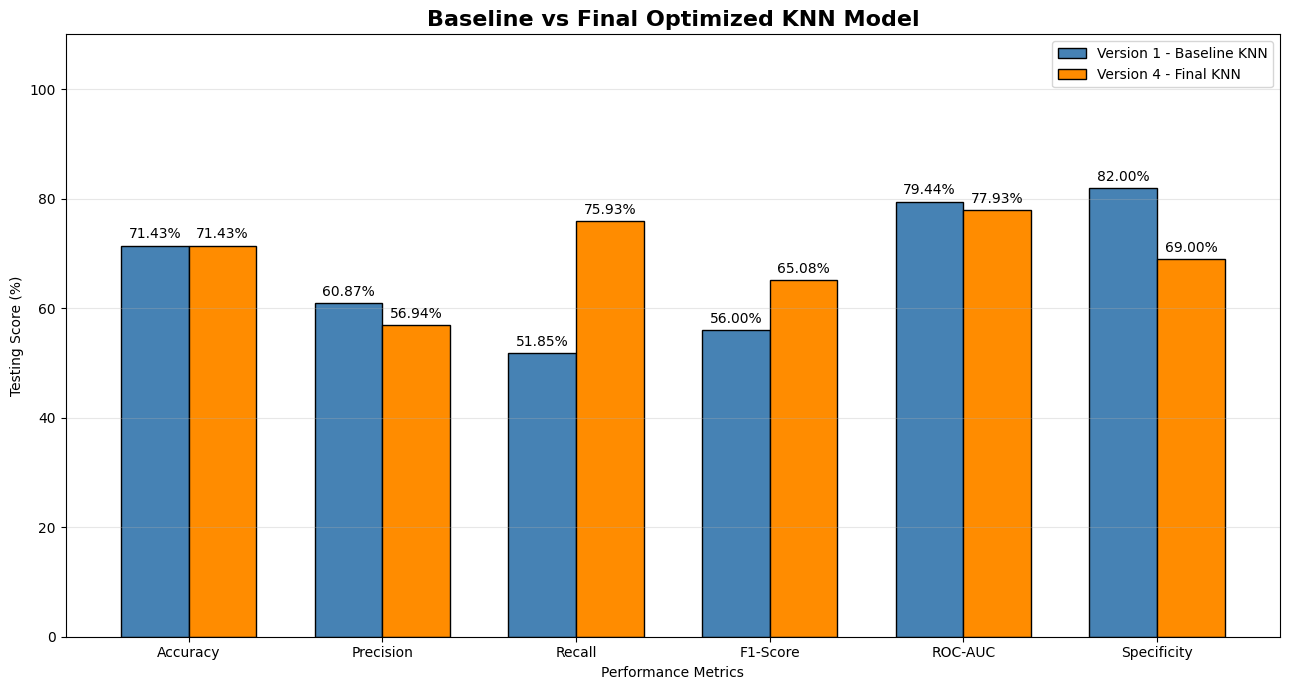

In [ ]:
# Visualize baseline and final model testing performance

plot_metrics = final_improvement_df['Metric']

baseline_scores = final_improvement_df['Baseline (%)']

final_scores = final_improvement_df['Final Model (%)']

x = np.arange(len(plot_metrics))
width = 0.35

plt.figure(figsize=(13, 7))

bars1 = plt.bar(
    x - width / 2,
    baseline_scores,
    width,
    label='Version 1 - Baseline KNN',
    color='steelblue',
    edgecolor='black'
)

bars2 = plt.bar(
    x + width / 2,
    final_scores,
    width,
    label=f'{final_model_version} - Final KNN',
    color='darkorange',
    edgecolor='black'
)

plt.bar_label(
    bars1,
    fmt='%.2f%%',
    padding=3,
    fontsize=10
)

plt.bar_label(
    bars2,
    fmt='%.2f%%',
    padding=3,
    fontsize=10
)

plt.title(
    'Baseline vs Final Optimized KNN Model',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Performance Metrics')
plt.ylabel('Testing Score (%)')

plt.xticks(x, plot_metrics)
plt.ylim(0, 110)

plt.legend(loc='upper right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

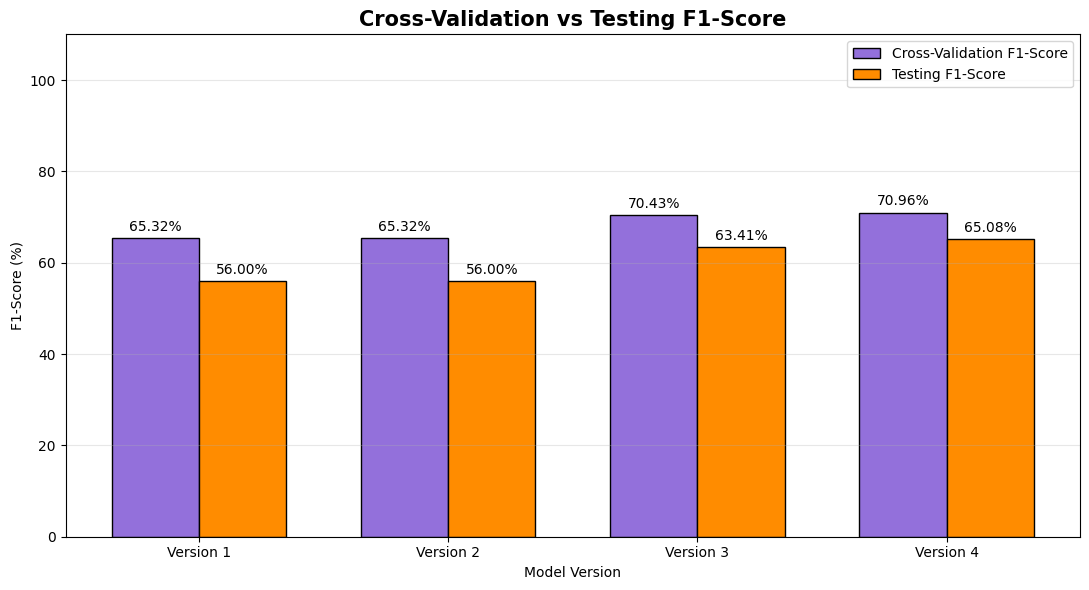

In [ ]:
# Compare development and testing F1-scores

x = np.arange(len(evaluation_df))
width = 0.35

plt.figure(figsize=(11, 6))

bars1 = plt.bar(
    x - width / 2,
    evaluation_df['CV F1-Score (%)'],
    width,
    label='Cross-Validation F1-Score',
    color='mediumpurple',
    edgecolor='black'
)

bars2 = plt.bar(
    x + width / 2,
    evaluation_df['Testing F1-Score (%)'],
    width,
    label='Testing F1-Score',
    color='darkorange',
    edgecolor='black'
)

plt.bar_label(
    bars1,
    fmt='%.2f%%',
    padding=3,
    fontsize=10
)

plt.bar_label(
    bars2,
    fmt='%.2f%%',
    padding=3,
    fontsize=10
)

plt.title(
    'Cross-Validation vs Testing F1-Score',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Model Version')
plt.ylabel('F1-Score (%)')

plt.xticks(
    x,
    evaluation_df['Model']
)

plt.ylim(0, 110)
plt.legend(loc='upper right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Preserve final model predictions and evaluation metrics

final_predictions = all_predictions[
    final_model_version
]

final_probabilities = all_probabilities[
    final_model_version
]

final_cm = all_confusion_matrices[
    final_model_version
]

final_tn, final_fp, final_fn, final_tp = (
    final_cm.ravel()
)

final_test_summary = {
    'Training Accuracy':
        final_test_row['Training Accuracy (%)'] / 100,
    'Testing Accuracy':
        final_test_row['Testing Accuracy (%)'] / 100,
    'Precision':
        final_test_row['Testing Precision (%)'] / 100,
    'Recall':
        final_test_row['Testing Recall (%)'] / 100,
    'F1-Score':
        final_test_row['Testing F1-Score (%)'] / 100,
    'ROC-AUC':
        final_test_row['Testing ROC-AUC'],
    'Specificity':
        final_test_row['Specificity (%)'] / 100
}

final_best_k = final_model.named_steps[
    'knn'
].n_neighbors

print("Final model evaluation preserved successfully!")

print("\nFinal Model:", final_model_version)
print("Optimal K:", final_best_k)

print("\nFinal Confusion Matrix:")
print(final_cm)

print("\nTrue Negatives:", final_tn)
print("False Positives:", final_fp)
print("False Negatives:", final_fn)
print("True Positives:", final_tp)

print("\nFinal Testing Performance:\n")

for metric, value in final_test_summary.items():

    if metric == 'ROC-AUC':

        print(f"{metric:20s}: {value:.4f}")

    else:

        print(f"{metric:20s}: {value * 100:.2f}%")

Final model evaluation preserved successfully!

Final Model: Version 4
Optimal K: 25

Final Confusion Matrix:
[[69 31]
 [13 41]]

True Negatives: 69
False Positives: 31
False Negatives: 13
True Positives: 41

Final Testing Performance:

Training Accuracy   : 100.00%
Testing Accuracy    : 71.43%
Precision           : 56.94%
Recall              : 75.93%
F1-Score            : 65.08%
ROC-AUC             : 0.7793
Specificity         : 69.00%


In [ ]:
# Generate the final comparative experimental summary

print("=" * 70)
print("      DIABETES PREDICTION USING KNN - FINAL MODEL SUMMARY")
print("=" * 70)

print("\nDataset Information:")

print("Total Dataset Records:", len(df))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Input Features:", X_train.shape[1])

print("\nModel Development Journey:")

for version, summary in all_cv_summaries.items():

    print(
        f"{version} - {model_descriptions[version]}: "
        f"CV F1-Score = {summary['f1'] * 100:.2f}%"
    )

print("\nFinal Model Selection:")

print("Selected Model:", final_model_version)
print("Description:", final_model_name)
print("Selection Metric: Cross-Validation F1-Score")

print(
    f"Selected CV F1-Score: "
    f"{final_cv_summary['f1'] * 100:.2f}%"
)

print("\nFinal Testing Performance:")

for metric, value in final_test_summary.items():

    if metric == 'ROC-AUC':

        print(f"{metric:20s}: {value:.4f}")

    else:

        print(f"{metric:20s}: {value * 100:.2f}%")

print("\nTesting Performance Changes from Baseline:")

for index, row in final_improvement_df.iterrows():

    print(
        f"{row['Metric']:15s}: "
        f"{row['Change (pp)']:+.2f} pp "
        f"({row['Status']})"
    )

print("\nFalse-Negative Analysis:")

print("Baseline False Negatives:",
      baseline_false_negatives)

print("Final Model False Negatives:",
      final_fn)

print(
    f"Relative False-Negative Reduction: "
    f"{final_error_row['FN Reduction (%)']:.2f}%"
)

print("\nFinal Experimental Conclusion:")

final_f1_change = (
    final_test_summary['F1-Score'] -
    baseline_test_summary['F1-Score']
) * 100

if np.isclose(final_f1_change, 0):

    print(
        "The final model matched the baseline "
        "in testing F1-score."
    )

elif final_f1_change > 0:

    print(
        "The final model improved testing F1-score "
        "compared with the baseline."
    )

else:

    print(
        "The final model achieved a lower testing "
        "F1-score than the baseline."
    )

print(
    "\nThe final model was selected using "
    "cross-validation performance."
)

print(
    "No additional hyperparameter tuning was "
    "performed using the testing results."
)

print(
    "\nThis model is intended for educational "
    "machine learning experimentation only."
)

print(
    "It is not a clinically validated "
    "diabetes diagnostic system."
)

print("=" * 70)

      DIABETES PREDICTION USING KNN - FINAL MODEL SUMMARY

Dataset Information:
Total Dataset Records: 768
Training Records: 614
Testing Records: 154
Input Features: 8

Model Development Journey:
Version 1 - Baseline KNN: CV F1-Score = 65.32%
Version 2 - Hyperparameter-Optimized KNN: CV F1-Score = 65.32%
Version 3 - SMOTE-KNN: CV F1-Score = 70.43%
Version 4 - Advanced Preprocessing KNN: CV F1-Score = 70.96%

Final Model Selection:
Selected Model: Version 4
Description: Advanced Preprocessing KNN
Selection Metric: Cross-Validation F1-Score
Selected CV F1-Score: 70.96%

Final Testing Performance:
Training Accuracy   : 100.00%
Testing Accuracy    : 71.43%
Precision           : 56.94%
Recall              : 75.93%
F1-Score            : 65.08%
ROC-AUC             : 0.7793
Specificity         : 69.00%

Testing Performance Changes from Baseline:
Accuracy       : +0.00 pp (No Change)
Precision      : -3.93 pp (Decreased)
Recall         : +24.07 pp (Improved)
F1-Score       : +9.08 pp (Improved)

In [ ]:
# Save the final trained model and evaluation results

import os
import joblib
import sklearn
import imblearn

os.makedirs('results', exist_ok=True)
os.makedirs('models', exist_ok=True)

# Save the complete fitted model pipeline

joblib.dump(
    final_model,
    'models/final_knn_model.joblib'
)

# Save the baseline model

joblib.dump(
    baseline_model,
    'models/baseline_knn_model.joblib'
)

# Save cross-validation performance

comparison_df.to_csv(
    'results/cross_validation_comparison.csv',
    index=False
)

# Save testing performance

evaluation_df.to_csv(
    'results/testing_performance_comparison.csv',
    index=False
)

# Save performance improvements

final_improvement_df.to_csv(
    'results/final_model_improvements.csv',
    index=False
)

# Save classification error analysis

error_analysis_df.to_csv(
    'results/classification_error_analysis.csv',
    index=False
)

# Save generalization analysis

generalization_df.to_csv(
    'results/generalization_analysis.csv',
    index=False
)

# Record package versions

package_versions = pd.DataFrame({
    'Package': [
        'numpy',
        'pandas',
        'scikit-learn',
        'imbalanced-learn',
        'joblib'
    ],
    'Version': [
        np.__version__,
        pd.__version__,
        sklearn.__version__,
        imblearn.__version__,
        joblib.__version__
    ]
})

package_versions.to_csv(
    'results/package_versions.csv',
    index=False
)

print("Models and evaluation results saved successfully!")

print("\nSaved Model Files:")

for filename in sorted(os.listdir('models')):

    print("-", filename)

print("\nSaved Result Files:")

for filename in sorted(os.listdir('results')):

    print("-", filename)

Models and evaluation results saved successfully!

Saved Model Files:
- baseline_knn_model.joblib
- final_knn_model.joblib

Saved Result Files:
- classification_error_analysis.csv
- cross_validation_comparison.csv
- final_model_improvements.csv
- generalization_analysis.csv
- package_versions.csv
- testing_performance_comparison.csv


In [ ]:
# Verify that the saved final model works correctly

loaded_final_model = joblib.load(
    'models/final_knn_model.joblib'
)

loaded_predictions = loaded_final_model.predict(
    X_test
)

positive_class_index = list(
    loaded_final_model.classes_
).index(1)

loaded_probabilities = (
    loaded_final_model.predict_proba(X_test)
    [:, positive_class_index]
)

predictions_match = np.array_equal(
    loaded_predictions,
    final_predictions
)

probabilities_match = np.allclose(
    loaded_probabilities,
    final_probabilities
)

print("Saved Final Model Verification:\n")

print("Predictions Match:", predictions_match)

print("Probabilities Match:", probabilities_match)

print(
    f"Loaded Model Testing Accuracy: "
    f"{accuracy_score(y_test, loaded_predictions) * 100:.2f}%"
)

assert predictions_match
assert probabilities_match

print("\nSaved final model verified successfully!")

Saved Final Model Verification:

Predictions Match: True
Probabilities Match: True
Loaded Model Testing Accuracy: 71.43%

Saved final model verified successfully!


In [ ]:
# Create a ZIP archive of the saved models and results

import zipfile

archive_name = 'Diabetes_KNN_Models_and_Results.zip'

with zipfile.ZipFile(
    archive_name,
    'w',
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for folder in ['models', 'results']:

        for root, directories, filenames in os.walk(folder):

            for filename in filenames:

                file_path = os.path.join(
                    root,
                    filename
                )

                archive.write(
                    file_path,
                    arcname=file_path
                )

print("Model and results archive created successfully!")

print("Archive Name:", archive_name)

print(
    f"Archive Size: "
    f"{os.path.getsize(archive_name) / 1024:.2f} KB"
)

files.download(archive_name)

Model and results archive created successfully!
Archive Name: Diabetes_KNN_Models_and_Results.zip
Archive Size: 104.00 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**FINAL EVALUATION METHODOLOGY AND LIMITATIONS**

The final model was selected using the highest mean cross-validation F1-score obtained during the model development experiments.

All four model versions were evaluated using the same original testing dataset containing 154 records. No additional hyperparameter optimization was performed using the comparative testing results.

**Evaluation Limitations**

1. Cross-validation performance estimates were influenced by hyperparameter selection because the same cross-validation folds were used for model optimization and performance comparison.

2. The reported cross-validation improvements represent development performance and should not be interpreted as independent estimates of generalization performance.

3. The original testing dataset had previously been evaluated for the baseline model. Therefore, the comparative testing evaluation is retrospective and does not constitute independent external validation.

4. The relatively small dataset size may limit the reliability and generalizability of the performance estimates.

5. The dataset represents a specific population, which limits the applicability of the model to broader populations.

6. SMOTE generates synthetic observations through interpolation and may produce fractional values for originally discrete features.

7. The differences between model versions cannot be attributed exclusively to individual optimization techniques because several hyperparameters were optimized jointly.

8. The observed performance differences do not establish statistical significance.

9. KNN probability estimates are not necessarily calibrated estimates of clinical diabetes risk.

10. The developed model is intended for educational machine learning experimentation and is not a clinically validated medical diagnostic system.

Future work may incorporate nested cross-validation, independent external validation, probability calibration and larger, more diverse datasets to obtain stronger evidence of model generalization.

**FINAL COMPARATIVE OBSERVATIONS AND PERFORMANCE ANALYSIS**

**Model Development and Optimization**

1. Four versions of the K-Nearest Neighbors classification model were developed through successive optimization experiments.

2. Version 1 established the baseline model using median imputation, standard feature scaling, uniform neighbor weights and Euclidean distance.

3. Version 2 expanded the hyperparameter search space but selected the same optimal configuration as the baseline model. Consequently, no improvement was observed in cross-validation or testing performance.

4. Version 3 incorporated SMOTE-based class balancing and advanced hyperparameter optimization, resulting in substantial improvements in recall and F1-score.

5. Version 4 investigated alternative preprocessing techniques and joint hyperparameter optimization, producing the highest cross-validation F1-score among the four model versions.

**Final Model Selection**

6. Version 4 was selected as the final model based on its cross-validation F1-score of 70.96%.

7. The final selected model configuration consisted of:

   - Feature Scaling: MinMaxScaler
   - Missing-Value Imputation: KNNImputer
   - Imputer Neighbors: 3
   - Class Balancing: SMOTE
   - SMOTE Sampling Ratio: 1.0
   - SMOTE Neighbors: 5
   - Number of Neighbors (K): 25
   - Neighbor Weights: Distance
   - Distance Metric: Euclidean

8. Final model selection was performed before comparative testing evaluation, using cross-validation F1-score as the primary selection criterion.

**Comparative Testing Performance**

9. All four model versions were evaluated on the same original testing dataset containing 154 records.

10. The final selected model achieved the following testing performance:

    - Accuracy: 71.43%
    - Precision: 56.94%
    - Recall: 75.93%
    - F1-Score: 65.08%
    - ROC-AUC: 0.7793
    - Specificity: 69.00%

11. The final model achieved the highest testing recall and F1-score among the four model versions.

12. Compared with the baseline model, testing recall improved from 51.85% to 75.93%, representing an improvement of 24.07 percentage points and a relative improvement of 46.43%.

13. Testing F1-score improved from 56.00% to 65.08%, representing an improvement of 9.08 percentage points and a relative improvement of 16.21%.

14. Testing accuracy remained unchanged at 71.43%, demonstrating that the improvement in minority-class classification was achieved without reducing overall testing accuracy.

**Confusion Matrix and Classification Error Analysis**

15. The baseline model correctly identified 28 out of 54 actual diabetic testing records, whereas the final model correctly identified 41 out of 54.

16. The number of false negatives decreased from 26 to 13, representing a relative reduction of 50.00%.

17. The number of false positives increased from 18 to 31.

18. Both the baseline and final models correctly classified 110 out of 154 testing records. However, the final model identified a greater number of diabetic records.

19. The reduction in false negatives was accompanied by a decrease in precision and specificity, demonstrating the trade-off between identifying more positive records and incorrectly classifying negative records.

**ROC-AUC and Generalization Analysis**

20. Version 3 achieved the highest testing ROC-AUC score of 0.7994.

21. The final model achieved a testing ROC-AUC score of 0.7793, which was lower than the baseline ROC-AUC score of 0.7944.

22. The improvement in testing recall and F1-score was therefore not accompanied by an improvement in overall ranking-based class discrimination.

23. Versions 3 and 4 achieved 100% training accuracy. This can be explained in part by the distance-weighted KNN mechanism, in which training observations may act as their own nearest neighbors.

24. The final model exhibited a training-testing accuracy gap of 28.57 percentage points, indicating a potential generalization concern.

25. The difference between cross-validation and testing F1-score decreased from 9.32 percentage points in the baseline model to 5.88 percentage points in the final model.

26. Although these findings are encouraging, the observed performance differences do not establish statistical significance or guarantee generalization to other populations.

**Final Comparative Conclusion**

The successive optimization experiments demonstrated that class balancing, advanced preprocessing and hyperparameter optimization can improve minority-class classification performance within the investigated experimental framework.

The final optimized KNN model improved testing recall by 24.07 percentage points and testing F1-score by 9.08 percentage points while maintaining the baseline testing accuracy of 71.43%.

Furthermore, the number of false-negative predictions decreased by 50.00%, demonstrating a substantial reduction in missed diabetic testing records.

These improvements were accompanied by increased false-positive predictions and decreases in precision, specificity and testing ROC-AUC.

Version 4 was retained as the final model because it achieved the highest cross-validation F1-score according to the predefined model selection criterion.

The final model will be integrated into an interactive diabetes prediction system for educational demonstration.

The developed model is intended solely for educational machine learning experimentation and is not a clinically validated diabetes diagnostic system.

All reported performance changes were calculated using unrounded metric values before rounding the final results.

**FINAL INTERACTIVE DIABETES PREDICTION SYSTEM**

The final optimized KNN model (Version 4) is integrated
into an interactive diabetes prediction system.

The system accepts eight input features and generates
a predicted outcome using the fitted machine learning
pipeline.

The interactive prediction system includes:

- User input collection
- Input validation and error handling
- Missing-value treatment
- Automated feature scaling and imputation
- Diabetes classification
- Estimated class probabilities
- Prediction visualization
- Baseline and optimized model comparison

The system is intended for educational machine learning
demonstration only and is not a clinically validated
medical diagnostic system.

In [108]:
# Verify final model availability

from sklearn.utils.validation import check_is_fitted

check_is_fitted(final_model.named_steps['knn'])
check_is_fitted(baseline_model.named_steps['knn'])

print("Final Interactive Prediction System")
print("=" * 55)

print("\nFinal Model:", final_model_version)
print("Model Description:", final_model_name)

print(
    "Number of Neighbors:",
    final_model.named_steps['knn'].n_neighbors
)

print(
    "Neighbor Weights:",
    final_model.named_steps['knn'].weights
)

print(
    "Distance Metric:",
    final_model.named_steps['knn'].effective_metric_
)

print("\nFinal model is trained and ready for prediction!")
print("Baseline model is available for comparison!")

Final Interactive Prediction System

Final Model: Version 4
Model Description: Advanced Preprocessing KNN
Number of Neighbors: 25
Neighbor Weights: distance
Distance Metric: euclidean

Final model is trained and ready for prediction!
Baseline model is available for comparison!


In [109]:
# Define the input features and their descriptions

feature_information = pd.DataFrame({
    'Feature': [
        'Pregnancies',
        'Glucose',
        'BloodPressure',
        'SkinThickness',
        'Insulin',
        'BMI',
        'DiabetesPedigreeFunction',
        'Age'
    ],

    'Description': [
        'Number of pregnancies',
        'Plasma glucose concentration',
        'Diastolic blood pressure',
        'Triceps skinfold thickness',
        '2-hour serum insulin',
        'Body mass index',
        'Diabetes pedigree function',
        'Age of the individual'
    ],

    'Unit': [
        'Count',
        'mg/dL',
        'mmHg',
        'mm',
        'mu U/mL',
        'kg/m²',
        'Score',
        'Years'
    ],

    'Input Type': [
        'Integer',
        'Float',
        'Float',
        'Float',
        'Float',
        'Float',
        'Float',
        'Integer'
    ]
})

print("Input Features Required for Diabetes Prediction:\n")

display(feature_information)

print("\nTotal Input Features:", len(feature_information))

assert feature_information['Feature'].tolist() == (
    X_train.columns.tolist()
)

print("Feature names and order verified successfully!")

Input Features Required for Diabetes Prediction:



,Feature,Description,Unit,Input Type
0,Pregnancies,Number of pregnancies,Count,Integer
1,Glucose,Plasma glucose concentration,mg/dL,Float
2,BloodPressure,Diastolic blood pressure,mmHg,Float
3,SkinThickness,Triceps skinfold thickness,mm,Float
4,Insulin,2-hour serum insulin,mu U/mL,Float
5,BMI,Body mass index,kg/m²,Float
6,DiabetesPedigreeFunction,Diabetes pedigree function,Score,Float
7,Age,Age of the individual,Years,Integer



Total Input Features: 8
Feature names and order verified successfully!


In [110]:
# Define the input validation function

def validate_prediction_input(input_data):

    # Check the number of input features

    if len(input_data) != len(X_train.columns):

        raise ValueError(
            "Exactly eight input features are required."
        )

    # Convert input values into numeric format

    try:

        values = np.asarray(
            input_data,
            dtype=float
        )

    except (ValueError, TypeError):

        raise ValueError(
            "All input values must be numeric."
        )

    # Check input dimensions

    if values.shape != (8,):

        raise ValueError(
            "Input must contain eight individual values."
        )

    # Check for NaN and infinite values

    if not np.all(np.isfinite(values)):

        raise ValueError(
            "Input values must be finite numbers."
        )

    # Check for negative values

    if np.any(values < 0):

        raise ValueError(
            "Negative input values are not allowed."
        )

    # Pregnancies must be an integer

    if not values[0].is_integer():

        raise ValueError(
            "Number of pregnancies must be an integer."
        )

    # Age must be an integer

    if not values[7].is_integer():

        raise ValueError(
            "Age must be an integer."
        )

    # Dataset age restriction

    if values[7] < 21:

        raise ValueError(
            "Age must be at least 21 years "
            "for this dataset-based demonstration."
        )

    return values.tolist()


print("Input validation function created successfully!")

Input validation function created successfully!


In [111]:
# Prepare input data for model prediction

def prepare_prediction_input(input_data):

    # Validate the input values

    validated_data = validate_prediction_input(
        input_data
    )

    # Create DataFrame with original feature names

    input_df = pd.DataFrame(
        [validated_data],
        columns=X_train.columns
    )

    # Replace invalid zero values with NaN

    input_df[columns_to_check] = (
        input_df[columns_to_check]
        .replace(0, np.nan)
    )

    return input_df


print("Input preprocessing function created successfully!")

Input preprocessing function created successfully!


In [112]:
# Define the final optimized diabetes prediction function

def predict_diabetes_final(input_data):

    # Prepare the input data

    input_df = prepare_prediction_input(
        input_data
    )

    # Generate the predicted outcome

    prediction = int(
        final_model.predict(input_df)[0]
    )

    # Generate estimated class probabilities

    probabilities = final_model.predict_proba(
        input_df
    )[0]

    # Identify the correct class positions

    class_labels = list(final_model.classes_)

    non_diabetic_probability = float(
        probabilities[class_labels.index(0)]
    )

    diabetic_probability = float(
        probabilities[class_labels.index(1)]
    )

    # Preserve the prediction results

    result = {
        'Prediction': prediction,

        'Predicted Outcome':
            'Diabetic' if prediction == 1
            else 'Non-Diabetic',

        'Non-Diabetic Probability':
            non_diabetic_probability,

        'Diabetic Probability':
            diabetic_probability,

        'Model Version':
            final_model_version,

        'Optimal K':
            final_model.named_steps['knn'].n_neighbors
    }

    return result


print("Final diabetes prediction function created successfully!")

Final diabetes prediction function created successfully!


In [113]:
# Display prediction results in a formatted manner

def display_final_prediction(result):

    print("=" * 60)
    print("       FINAL KNN DIABETES PREDICTION RESULT")
    print("=" * 60)

    print("\nModel:", result['Model Version'])
    print("Optimal K:", result['Optimal K'])

    print(
        "\nPredicted Outcome:",
        result['Predicted Outcome']
    )

    print("\nEstimated Class Probabilities:")

    print(
        f"Non-Diabetic: "
        f"{result['Non-Diabetic Probability'] * 100:.2f}%"
    )

    print(
        f"Diabetic: "
        f"{result['Diabetic Probability'] * 100:.2f}%"
    )

    print("\nImportant Note:")

    print(
        "These are model-estimated class probabilities, "
        "not calibrated clinical risk estimates."
    )

    print(
        "This system is intended for educational "
        "purposes only and does not provide "
        "a medical diagnosis."
    )

    print("=" * 60)


print("Formatted prediction output function created successfully!")

Formatted prediction output function created successfully!


In [114]:
# Test the final model using sample input 1

sample_input_1 = [
    1,       # Pregnancies
    95,      # Glucose
    70,      # Blood Pressure
    30,      # Skin Thickness
    85,      # Insulin
    23.5,    # BMI
    0.200,   # Diabetes Pedigree Function
    25       # Age
]

print("Sample Input 1:\n")

display(
    pd.DataFrame(
        [sample_input_1],
        columns=X_train.columns
    )
)

sample_result_1 = predict_diabetes_final(
    sample_input_1
)

display_final_prediction(sample_result_1)

Sample Input 1:



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,1,95,70,30,85,23.5,0.2,25


       FINAL KNN DIABETES PREDICTION RESULT

Model: Version 4
Optimal K: 25

Predicted Outcome: Non-Diabetic

Estimated Class Probabilities:
Non-Diabetic: 100.00%
Diabetic: 0.00%

Important Note:
These are model-estimated class probabilities, not calibrated clinical risk estimates.
This system is intended for educational purposes only and does not provide a medical diagnosis.


In [115]:
# Test the final model using sample input 2

sample_input_2 = [
    6,       # Pregnancies
    180,     # Glucose
    85,      # Blood Pressure
    35,      # Skin Thickness
    200,     # Insulin
    36.5,    # BMI
    0.850,   # Diabetes Pedigree Function
    50       # Age
]

print("Sample Input 2:\n")

display(
    pd.DataFrame(
        [sample_input_2],
        columns=X_train.columns
    )
)

sample_result_2 = predict_diabetes_final(
    sample_input_2
)

display_final_prediction(sample_result_2)

Sample Input 2:



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,180,85,35,200,36.5,0.85,50


       FINAL KNN DIABETES PREDICTION RESULT

Model: Version 4
Optimal K: 25

Predicted Outcome: Diabetic

Estimated Class Probabilities:
Non-Diabetic: 4.04%
Diabetic: 95.96%

Important Note:
These are model-estimated class probabilities, not calibrated clinical risk estimates.
This system is intended for educational purposes only and does not provide a medical diagnosis.


In [116]:
# Test prediction with missing-value indicators

sample_input_3 = [
    2,       # Pregnancies
    140,     # Glucose
    72,      # Blood Pressure
    0,       # Missing Skin Thickness
    0,       # Missing Insulin
    30.5,    # BMI
    0.450,   # Diabetes Pedigree Function
    35       # Age
]

print("Original Sample Input:\n")

display(
    pd.DataFrame(
        [sample_input_3],
        columns=X_train.columns
    )
)

prepared_sample_3 = prepare_prediction_input(
    sample_input_3
)

print("\nInput After Invalid Zero-Value Treatment:\n")

display(prepared_sample_3)

print("\nFeatures Requiring Imputation:")

missing_features = prepared_sample_3.columns[
    prepared_sample_3.isna().any()
].tolist()

for feature in missing_features:

    print("-", feature)

sample_result_3 = predict_diabetes_final(
    sample_input_3
)

print()

display_final_prediction(sample_result_3)

Original Sample Input:



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,2,140,72,0,0,30.5,0.45,35



Input After Invalid Zero-Value Treatment:



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,2.0,140.0,72.0,NaN,NaN,30.5,0.45,35.0



Features Requiring Imputation:
- SkinThickness
- Insulin

       FINAL KNN DIABETES PREDICTION RESULT

Model: Version 4
Optimal K: 25

Predicted Outcome: Diabetic

Estimated Class Probabilities:
Non-Diabetic: 28.07%
Diabetic: 71.93%

Important Note:
These are model-estimated class probabilities, not calibrated clinical risk estimates.
This system is intended for educational purposes only and does not provide a medical diagnosis.


In [117]:
# Test input validation and error handling

validation_test_cases = {
    'Incorrect Number of Features':
        [1, 95, 70],

    'Negative Glucose Value':
        [1, -95, 70, 30, 85, 23.5, 0.2, 25],

    'Invalid Age':
        [1, 95, 70, 30, 85, 23.5, 0.2, 18],

    'Non-Numeric Input':
        [1, 'invalid', 70, 30, 85, 23.5, 0.2, 25],

    'Fractional Pregnancies':
        [1.5, 95, 70, 30, 85, 23.5, 0.2, 25],

    'Fractional Age':
        [1, 95, 70, 30, 85, 23.5, 0.2, 25.5],

    'Infinite Input':
        [1, np.inf, 70, 30, 85, 23.5, 0.2, 25]
}

passed_tests = 0

print("Input Validation Testing")
print("=" * 60)

for test_name, test_data in validation_test_cases.items():

    print(f"\nTest: {test_name}")

    try:

        validate_prediction_input(test_data)

        print("Status: FAILED")

    except ValueError as error:

        print("Status: PASSED")
        print("Validation Message:", error)

        passed_tests += 1

print("\n" + "=" * 60)

print(
    f"Validation Tests Passed: "
    f"{passed_tests}/{len(validation_test_cases)}"
)

assert passed_tests == len(validation_test_cases)

print("All input validation tests passed successfully!")

Input Validation Testing

Test: Incorrect Number of Features
Status: PASSED
Validation Message: Exactly eight input features are required.

Test: Negative Glucose Value
Status: PASSED
Validation Message: Negative input values are not allowed.

Test: Invalid Age
Status: PASSED
Validation Message: Age must be at least 21 years for this dataset-based demonstration.

Test: Non-Numeric Input
Status: PASSED
Validation Message: All input values must be numeric.

Test: Fractional Pregnancies
Status: PASSED
Validation Message: Number of pregnancies must be an integer.

Test: Fractional Age
Status: PASSED
Validation Message: Age must be an integer.

Test: Infinite Input
Status: PASSED
Validation Message: Input values must be finite numbers.

Validation Tests Passed: 7/7
All input validation tests passed successfully!


**INTERACTIVE DIABETES PREDICTION USING THE FINAL OPTIMIZED KNN MODEL**

Enter the eight required input features to generate
a prediction using the final selected Version 4 model.

The system validates the entered values and automatically
applies the fitted preprocessing pipeline.

For demonstration purposes, enter 0 for unavailable
glucose, blood pressure, skin thickness, insulin or BMI
measurements. These values will be treated as missing.

The generated outcome is a machine learning classification
and must not be interpreted as a medical diagnosis.

In [118]:
# Interactive diabetes prediction using the final model
# Reset previous results to prevent stale predictions

final_user_data = None
final_user_result = None

print("=" * 60)
print("       INTERACTIVE DIABETES PREDICTION SYSTEM")
print("=" * 60)

print("\nModel: Version 4 - Advanced Preprocessing KNN")

print("\nEnter the following input features:")

print(
    "\nFor unavailable glucose, blood pressure, "
    "skin thickness, insulin or BMI, enter 0.\n"
)

try:

    pregnancies = int(
        input("Enter Number of Pregnancies: ")
    )

    glucose = float(
        input("Enter Glucose Level (mg/dL): ")
    )

    blood_pressure = float(
        input("Enter Blood Pressure (mmHg): ")
    )

    skin_thickness = float(
        input("Enter Skin Thickness (mm): ")
    )

    insulin = float(
        input("Enter Insulin Level (mu U/mL): ")
    )

    bmi = float(
        input("Enter BMI (kg/m²): ")
    )

    dpf = float(
        input("Enter Diabetes Pedigree Function: ")
    )

    age = int(
        input("Enter Age (Years): ")
    )

    candidate_data = [
        pregnancies,
        glucose,
        blood_pressure,
        skin_thickness,
        insulin,
        bmi,
        dpf,
        age
    ]

    candidate_result = predict_diabetes_final(
        candidate_data
    )

    # Preserve results only after successful prediction

    final_user_data = candidate_data

    final_user_result = candidate_result

    print("\nEntered Input Features:\n")

    display(
        pd.DataFrame(
            [final_user_data],
            columns=X_train.columns
        )
    )

    print()

    display_final_prediction(
        final_user_result
    )

except ValueError as error:

    print("\nInvalid Input:", error)

    print(
        "Please run the cell again "
        "and enter valid input values."
    )

except (KeyboardInterrupt, EOFError):

    print("\nInput cancelled. No prediction generated.")

       INTERACTIVE DIABETES PREDICTION SYSTEM

Model: Version 4 - Advanced Preprocessing KNN

Enter the following input features:

For unavailable glucose, blood pressure, skin thickness, insulin or BMI, enter 0.

Enter Number of Pregnancies: 8
Enter Glucose Level (mg/dL): 180
Enter Blood Pressure (mmHg): 85
Enter Skin Thickness (mm): 35
Enter Insulin Level (mu U/mL): 200
Enter BMI (kg/m²): 36.5
Enter Diabetes Pedigree Function: 0.850
Enter Age (Years): 50

Entered Input Features:



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,8,180.0,85.0,35.0,200.0,36.5,0.85,50



       FINAL KNN DIABETES PREDICTION RESULT

Model: Version 4
Optimal K: 25

Predicted Outcome: Diabetic

Estimated Class Probabilities:
Non-Diabetic: 3.76%
Diabetic: 96.24%

Important Note:
These are model-estimated class probabilities, not calibrated clinical risk estimates.
This system is intended for educational purposes only and does not provide a medical diagnosis.


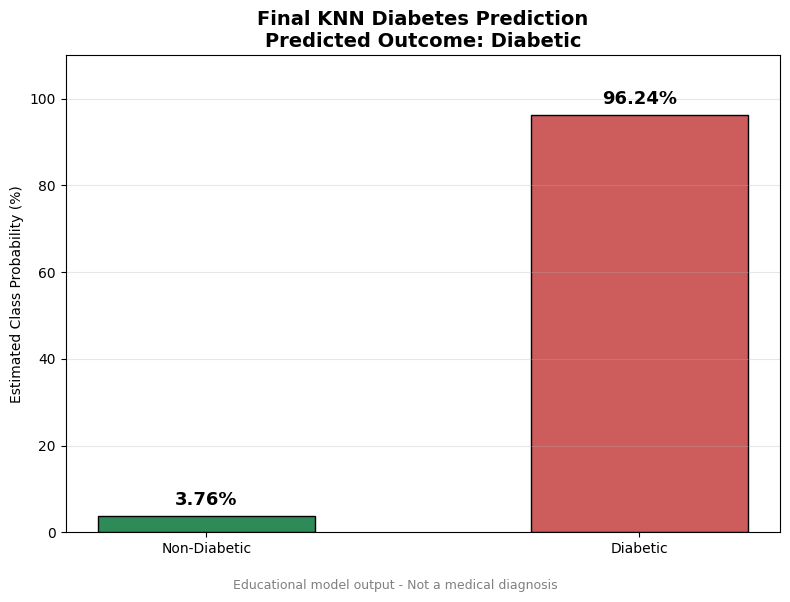

In [119]:
# Visualize the final interactive prediction

if final_user_result is not None:

    prediction_labels = [
        'Non-Diabetic',
        'Diabetic'
    ]

    prediction_probabilities = [
        final_user_result[
            'Non-Diabetic Probability'
        ] * 100,

        final_user_result[
            'Diabetic Probability'
        ] * 100
    ]

    prediction_colors = [
        'seagreen',
        'indianred'
    ]

    plt.figure(figsize=(8, 6))

    bars = plt.bar(
        prediction_labels,
        prediction_probabilities,
        color=prediction_colors,
        width=0.5,
        edgecolor='black'
    )

    plt.bar_label(
        bars,
        fmt='%.2f%%',
        padding=5,
        fontsize=13,
        fontweight='bold'
    )

    plt.title(
        'Final KNN Diabetes Prediction\n'
        f"Predicted Outcome: "
        f"{final_user_result['Predicted Outcome']}",
        fontsize=14,
        fontweight='bold'
    )

    plt.ylabel(
        'Estimated Class Probability (%)'
    )

    plt.ylim(0, 110)

    plt.grid(
        axis='y',
        alpha=0.3
    )

    plt.figtext(
        0.5,
        0.01,
        'Educational model output - Not a medical diagnosis',
        ha='center',
        fontsize=9,
        color='gray'
    )

    plt.tight_layout(
        rect=[0, 0.04, 1, 1]
    )

    plt.show()

else:

    print(
        "No valid interactive prediction is available."
    )

    print(
        "Please execute the interactive input cell first."
    )

In [120]:
# Compare baseline and final model predictions

def compare_model_predictions(input_data):

    input_df = prepare_prediction_input(
        input_data
    )

    comparison_results = []

    prediction_models = {
        'Version 1 - Baseline KNN':
            baseline_model,

        'Version 4 - Final Optimized KNN':
            final_model
    }

    for model_name, model in prediction_models.items():

        prediction = int(
            model.predict(input_df)[0]
        )

        probabilities = model.predict_proba(
            input_df
        )[0]

        class_labels = list(model.classes_)

        comparison_results.append({
            'Model': model_name,

            'Optimal K':
                model.named_steps['knn'].n_neighbors,

            'Predicted Outcome':
                'Diabetic' if prediction == 1
                else 'Non-Diabetic',

            'Non-Diabetic Probability (%)':
                probabilities[class_labels.index(0)] * 100,

            'Diabetic Probability (%)':
                probabilities[class_labels.index(1)] * 100
        })

    return pd.DataFrame(comparison_results)


print("Model prediction comparison function created successfully!")

Model prediction comparison function created successfully!


In [121]:
# Compare baseline and optimized predictions for sample inputs

sample_inputs = {
    'Sample 1 - Lower Glucose and BMI':
        sample_input_1,

    'Sample 2 - Higher Glucose and BMI':
        sample_input_2,

    'Sample 3 - Missing-Value Indicators':
        sample_input_3
}

sample_comparison_results = []

for sample_name, input_data in sample_inputs.items():

    print("=" * 65)

    print(sample_name)

    print("=" * 65)

    comparison = compare_model_predictions(
        input_data
    )

    display(comparison.round(2))

    comparison.insert(
        0,
        'Sample',
        sample_name
    )

    sample_comparison_results.append(
        comparison
    )

    print()

sample_comparison_df = pd.concat(
    sample_comparison_results,
    ignore_index=True
)

print("All sample prediction comparisons completed successfully!")

Sample 1 - Lower Glucose and BMI


,Model,Optimal K,Predicted Outcome,Non-Diabetic Probability (%),Diabetic Probability (%)
0,Version 1 - Baseline KNN,13,Non-Diabetic,100.0,0.0
1,Version 4 - Final Optimized KNN,25,Non-Diabetic,100.0,0.0



Sample 2 - Higher Glucose and BMI


,Model,Optimal K,Predicted Outcome,Non-Diabetic Probability (%),Diabetic Probability (%)
0,Version 1 - Baseline KNN,13,Diabetic,15.38,84.62
1,Version 4 - Final Optimized KNN,25,Diabetic,4.04,95.96



Sample 3 - Missing-Value Indicators


,Model,Optimal K,Predicted Outcome,Non-Diabetic Probability (%),Diabetic Probability (%)
0,Version 1 - Baseline KNN,13,Diabetic,38.46,61.54
1,Version 4 - Final Optimized KNN,25,Diabetic,28.07,71.93



All sample prediction comparisons completed successfully!


In [122]:
# Compare model predictions for the interactive input

interactive_comparison_df = None

if final_user_result is not None:

    interactive_comparison_df = (
        compare_model_predictions(
            final_user_data
        )
    )

    print(
        "Baseline vs Final Optimized Model "
        "Prediction Comparison:\n"
    )

    display(
        interactive_comparison_df.round(2)
    )

    baseline_outcome = (
        interactive_comparison_df
        .iloc[0]['Predicted Outcome']
    )

    optimized_outcome = (
        interactive_comparison_df
        .iloc[1]['Predicted Outcome']
    )

    print("\nBaseline Prediction:", baseline_outcome)

    print("Optimized Prediction:", optimized_outcome)

    if baseline_outcome == optimized_outcome:

        print(
            "\nBoth models generated "
            "the same predicted outcome."
        )

    else:

        print(
            "\nThe models generated "
            "different predicted outcomes."
        )

    diabetic_probability_change = (
        interactive_comparison_df
        .iloc[1]['Diabetic Probability (%)']
        -
        interactive_comparison_df
        .iloc[0]['Diabetic Probability (%)']
    )

    print(
        f"\nChange in Estimated Diabetic "
        f"Probability: "
        f"{diabetic_probability_change:+.2f} "
        f"percentage points"
    )

else:

    print(
        "No valid interactive input is available."
    )

Baseline vs Final Optimized Model Prediction Comparison:



,Model,Optimal K,Predicted Outcome,Non-Diabetic Probability (%),Diabetic Probability (%)
0,Version 1 - Baseline KNN,13,Diabetic,7.69,92.31
1,Version 4 - Final Optimized KNN,25,Diabetic,3.76,96.24



Baseline Prediction: Diabetic
Optimized Prediction: Diabetic

Both models generated the same predicted outcome.

Change in Estimated Diabetic Probability: +3.93 percentage points


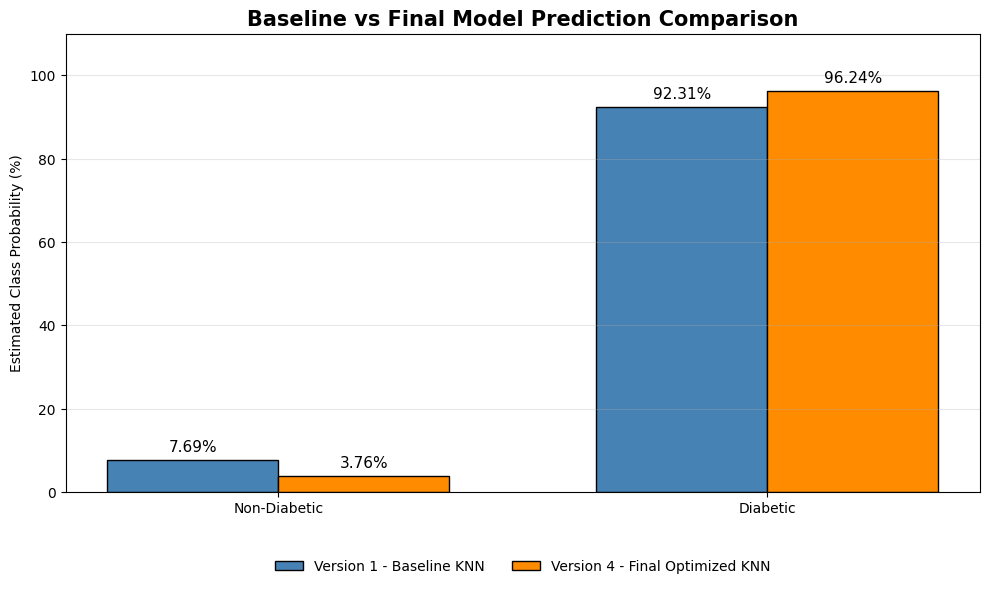

In [123]:
# Visualize baseline and optimized prediction probabilities

if final_user_result is not None:

    # Recalculate comparison for the current valid input

    interactive_comparison_df = (
        compare_model_predictions(
            final_user_data
        )
    )

    labels = [
        'Non-Diabetic',
        'Diabetic'
    ]

    baseline_probabilities = [
        interactive_comparison_df.iloc[0][
            'Non-Diabetic Probability (%)'
        ],

        interactive_comparison_df.iloc[0][
            'Diabetic Probability (%)'
        ]
    ]

    optimized_probabilities = [
        interactive_comparison_df.iloc[1][
            'Non-Diabetic Probability (%)'
        ],

        interactive_comparison_df.iloc[1][
            'Diabetic Probability (%)'
        ]
    ]

    x = np.arange(len(labels))
    width = 0.35

    plt.figure(figsize=(10, 6))

    bars1 = plt.bar(
        x - width / 2,
        baseline_probabilities,
        width,
        label='Version 1 - Baseline KNN',
        color='steelblue',
        edgecolor='black'
    )

    bars2 = plt.bar(
        x + width / 2,
        optimized_probabilities,
        width,
        label='Version 4 - Final Optimized KNN',
        color='darkorange',
        edgecolor='black'
    )

    plt.bar_label(
        bars1,
        fmt='%.2f%%',
        padding=4,
        fontsize=11
    )

    plt.bar_label(
        bars2,
        fmt='%.2f%%',
        padding=4,
        fontsize=11
    )

    plt.title(
        'Baseline vs Final Model Prediction Comparison',
        fontsize=15,
        fontweight='bold'
    )

    plt.ylabel(
        'Estimated Class Probability (%)'
    )

    plt.xticks(x, labels)

    plt.ylim(0, 110)

    plt.legend(
        loc='upper center',
        bbox_to_anchor=(0.5, -0.12),
        ncol=2,
        frameon=False
    )

    plt.grid(axis='y', alpha=0.3)

    plt.tight_layout()

    plt.show()

else:

    print(
        "Please generate a valid interactive "
        "prediction before visualization."
    )

In [124]:
# Verify the correctness of the prediction system

verification_results = []

for sample_name, input_data in sample_inputs.items():

    prepared_input = prepare_prediction_input(
        input_data
    )

    function_result = predict_diabetes_final(
        input_data
    )

    direct_prediction = int(
        final_model.predict(prepared_input)[0]
    )

    direct_probabilities = (
        final_model.predict_proba(prepared_input)[0]
    )

    class_labels = list(final_model.classes_)

    prediction_match = (
        function_result['Prediction'] ==
        direct_prediction
    )

    probabilities_match = np.allclose(
        [
            function_result[
                'Non-Diabetic Probability'
            ],

            function_result[
                'Diabetic Probability'
            ]
        ],
        [
            direct_probabilities[
                class_labels.index(0)
            ],

            direct_probabilities[
                class_labels.index(1)
            ]
        ]
    )

    probability_sum = (
        function_result['Non-Diabetic Probability']
        +
        function_result['Diabetic Probability']
    )

    valid_probability_sum = np.isclose(
        probability_sum,
        1.0
    )

    verification_results.append({
        'Sample': sample_name,
        'Prediction Match': prediction_match,
        'Probabilities Match': probabilities_match,
        'Probability Sum Valid': valid_probability_sum
    })

verification_df = pd.DataFrame(
    verification_results
)

print("Final Prediction System Verification:\n")

display(verification_df)

all_verification_passed = (
    verification_df[[
        'Prediction Match',
        'Probabilities Match',
        'Probability Sum Valid'
    ]].all().all()
)

assert all_verification_passed

print("\nAll prediction system verification tests passed!")

Final Prediction System Verification:



,Sample,Prediction Match,Probabilities Match,Probability Sum Valid
0,Sample 1 - Lower Glucose and BMI,True,True,True
1,Sample 2 - Higher Glucose and BMI,True,True,True
2,Sample 3 - Missing-Value Indicators,True,True,True



All prediction system verification tests passed!


In [125]:
# Save demonstration prediction results

os.makedirs('results', exist_ok=True)

sample_comparison_df.to_csv(
    'results/sample_prediction_comparison.csv',
    index=False
)

verification_df.to_csv(
    'results/prediction_system_verification.csv',
    index=False
)

print("Prediction demonstration results saved successfully!")

print("\nSaved Files:")

print("- sample_prediction_comparison.csv")
print("- prediction_system_verification.csv")

Prediction demonstration results saved successfully!

Saved Files:
- sample_prediction_comparison.csv
- prediction_system_verification.csv


In [126]:
# Generate the final interactive prediction system summary

print("=" * 65)
print("      FINAL INTERACTIVE PREDICTION SYSTEM SUMMARY")
print("=" * 65)

print("\nModel Information:")

print("Selected Model:", final_model_version)
print("Model Description:", final_model_name)
print("Optimal K:", final_best_k)

print("\nPrediction System Features:")

print("1. Eight input features")
print("2. Input validation and error handling")
print("3. Invalid zero-value treatment")
print("4. Automated feature scaling")
print("5. Automated KNN imputation")
print("6. Diabetes classification")
print("7. Estimated class probabilities")
print("8. Prediction visualization")
print("9. Baseline and optimized model comparison")

print("\nSystem Verification:")

print(
    f"Input Validation Tests: "
    f"{passed_tests}/{len(validation_test_cases)} Passed"
)

print(
    "Prediction Consistency Tests:",
    "Passed" if all_verification_passed else "Failed"
)

print("\nFinal Model Testing Performance:")

print(
    f"Accuracy: "
    f"{final_test_summary['Testing Accuracy'] * 100:.2f}%"
)

print(
    f"Precision: "
    f"{final_test_summary['Precision'] * 100:.2f}%"
)

print(
    f"Recall: "
    f"{final_test_summary['Recall'] * 100:.2f}%"
)

print(
    f"F1-Score: "
    f"{final_test_summary['F1-Score'] * 100:.2f}%"
)

print(
    f"ROC-AUC: "
    f"{final_test_summary['ROC-AUC']:.4f}"
)

print("\nInteractive Prediction Status:")

if final_user_result is not None:

    print("Interactive Prediction: Successful")

    print(
        "Predicted Outcome:",
        final_user_result['Predicted Outcome']
    )

else:

    print("No valid interactive prediction available.")

print("\nImportant Disclaimer:")

print(
    "This system is intended for educational "
    "machine learning demonstration only."
)

print(
    "The predicted outcome and estimated probabilities "
    "must not be interpreted as a medical diagnosis "
    "or an individual's clinical diabetes risk."
)

print("=" * 65)

      FINAL INTERACTIVE PREDICTION SYSTEM SUMMARY

Model Information:
Selected Model: Version 4
Model Description: Advanced Preprocessing KNN
Optimal K: 25

Prediction System Features:
1. Eight input features
2. Input validation and error handling
3. Invalid zero-value treatment
4. Automated feature scaling
5. Automated KNN imputation
6. Diabetes classification
7. Estimated class probabilities
8. Prediction visualization
9. Baseline and optimized model comparison

System Verification:
Input Validation Tests: 7/7 Passed
Prediction Consistency Tests: Passed

Final Model Testing Performance:
Accuracy: 71.43%
Precision: 56.94%
Recall: 75.93%
F1-Score: 65.08%
ROC-AUC: 0.7793

Interactive Prediction Status:
Interactive Prediction: Successful
Predicted Outcome: Diabetic

Important Disclaimer:
This system is intended for educational machine learning demonstration only.
The predicted outcome and estimated probabilities must not be interpreted as a medical diagnosis or an individual's clinical d

In [127]:
# Archive the synthetic prediction demonstration results

import zipfile

prediction_archive = (
    'Diabetes_KNN_Prediction_Demo_Results.zip'
)

with zipfile.ZipFile(
    prediction_archive,
    'w',
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for file_path in [
        'results/sample_prediction_comparison.csv',
        'results/prediction_system_verification.csv'
    ]:

        archive.write(
            file_path,
            arcname=file_path
        )

print("Prediction demonstration archive created successfully!")

print("Archive Name:", prediction_archive)

files.download(prediction_archive)

Prediction demonstration archive created successfully!
Archive Name: Diabetes_KNN_Prediction_Demo_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**FINAL INTERACTIVE PREDICTION SYSTEM: EXPERIMENTAL OBSERVATIONS AND ANALYSIS**

**Final Model Integration**

1. The final selected Version 4 KNN model was successfully integrated into an interactive diabetes prediction system.

2. The system uses the previously fitted machine learning pipeline without requiring additional model training or hyperparameter optimization.

3. The final model uses MinMaxScaler, KNNImputer with three neighbors, SMOTE-based training class balancing and a distance-weighted KNN classifier with 25 neighbors and Euclidean distance.

4. SMOTE is applied only during model training and is automatically skipped during prediction.

**Input Validation and Preprocessing**

5. The interactive prediction system accepts eight input features in the same order and format used during model training.

6. Input validation was implemented to reject incorrect feature counts, negative values, non-numeric values, infinite values, fractional pregnancy counts, fractional ages and ages below the dataset-based minimum of 21 years.

7. All seven predefined input validation tests passed successfully.

8. Invalid zero values in glucose, blood pressure, skin thickness, insulin and BMI are converted into missing values before prediction.

9. The fitted preprocessing pipeline automatically performs feature scaling and missing-value imputation.

**Sample Prediction Analysis**

10. Sample 1, containing comparatively lower glucose and BMI values, was classified as Non-Diabetic with an estimated non-diabetic probability of 100.00%.

11. Sample 2, containing comparatively higher glucose and BMI values, was classified as Diabetic with an estimated diabetic probability of 95.96%.

12. Sample 3 contained missing-value indicators for skin thickness and insulin. Both zero values were successfully converted into NaN and handled by the fitted preprocessing pipeline.

13. Sample 3 was classified as Diabetic with an estimated diabetic probability of 71.93%.

14. All three synthetic sample predictions were generated successfully without execution errors.

**Baseline and Optimized Model Comparison**

15. Both the baseline and optimized models generated identical predicted outcome classes for all three synthetic samples.

16. For Sample 1, both models generated an estimated diabetic probability of 0.00%.

17. For Sample 2, the estimated diabetic probability increased from 84.62% in the baseline model to 95.96% in the optimized model.

18. For Sample 3, the estimated diabetic probability increased from 61.54% in the baseline model to 71.93% in the optimized model.

19. These differences demonstrate changes in the prediction behaviour of the optimized model. Higher estimated probabilities do not independently establish greater prediction accuracy.

**Interactive Prediction Analysis**

20. The interactive prediction system successfully accepted all eight user-entered input features.

21. The demonstration input consisted of eight pregnancies, glucose of 180 mg/dL, blood pressure of 85 mmHg, skin thickness of 35 mm, insulin of 200 mu U/mL, BMI of 36.5, diabetes pedigree function of 0.850 and age of 50 years.

22. The final optimized model classified the demonstration input as Diabetic with estimated class probabilities of 3.76% for Non-Diabetic and 96.24% for Diabetic.

23. The baseline model classified the same input as Diabetic with an estimated diabetic probability of 92.31%.

24. The optimized model produced an estimated diabetic probability that was 3.93 percentage points higher than that of the baseline model.

25. Prediction probability visualizations and comparative bar graphs were successfully generated to illustrate the model outputs.

**System Verification and Reliability**

26. Prediction consistency was verified by comparing the custom prediction function with direct predictions from the fitted model pipeline.

27. All three sample inputs passed the prediction matching, probability matching and probability summation checks.

28. All nine individual prediction consistency checks passed successfully.

29. The system resets previous interactive prediction results before collecting new inputs to prevent stale predictions from being reused after an unsuccessful input attempt.

30. Synthetic sample prediction comparisons and system verification results were saved as CSV files for future documentation.

**Final Interactive Prediction System Conclusion**

The final optimized KNN model was successfully integrated into an interactive prediction system incorporating input validation, automated preprocessing, classification, estimated class probabilities, visualization and comparative model analysis.

The final model retained its previously evaluated testing accuracy of 71.43%, precision of 56.94%, recall of 75.93%, F1-score of 65.08% and ROC-AUC of 0.7793.

The successful completion of all predefined validation and prediction consistency tests demonstrates the functional correctness of the implemented system for the investigated test cases.

However, the synthetic sample predictions do not constitute independent evidence of predictive accuracy or clinical reliability.

The estimated class probabilities are not calibrated clinical diabetes risk estimates. Even a model-estimated probability of 100% does not establish medical certainty.

The developed system is intended solely for educational machine learning experimentation and is not a clinically validated medical diagnostic system.